![Technical Validation.png](<attachment:Technical Validation.png>)
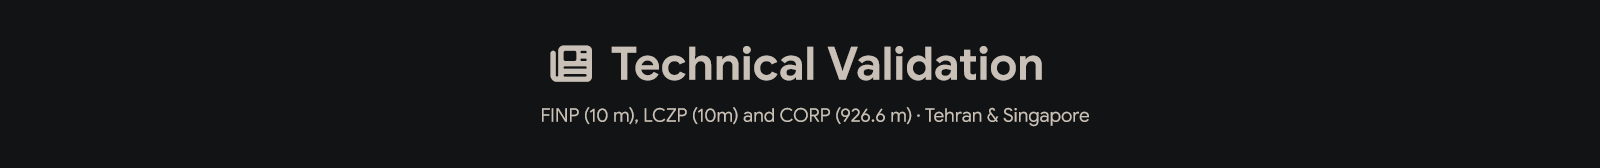

| | |
|:--|:--|
| **Authors** | Ali Rezaali & Parastoo Pilehforooshha |
| **Code Archive** | Zenodo · [10.5281/zenodo.22865045](https://doi.org/10.5281/zenodo.22865045) |
| **Data Archive** | Zenodo · [10.5281/zenodo.22723885](https://doi.org/10.5281/zenodo.22723885) |
| **Notebook Version** | 1.0.0 |
| **Runtime** | Google Colab (Python 3) |

#### **How To Cite**

**UC4D (Code):**

> Rezaali, A., & Pilehforooshha, P. (2026). UC4D: Urban Climate 4D Data Cube Framework (Version 1.0) [Computer software]. Zenodo. https://doi.org/10.5281/zenodo.22865045

**UC4D (Dataset):**

> Rezaali, A., & Pilehforooshha, P. (2026). UC4D: Urban Climate 4D Data Cube (Version 1.0) [Data set]. Zenodo. https://doi.org/10.5281/zenodo.22723885

---

#### **Overview**

This notebook plots and maps every technical-validation figure and table for UC4D: physical-range compliance across all 27 variable bands, Sentinel-2/Sentinel-1 composite coverage accounting, SAR speckle-suppression, interannual temporal consistency across TIRP-based pixels, cross-index physical plausibility, nighttime-lights plausibility and backward-aggregation fidelity, topographic cross-tier consistency of the FINP and CORP tiers, the building-height gap-fill benchmark, and the per-city multi-layer map panels.

Every figure is written to `BaseDir / Figures` as PNG at 600 dpi and rendered inline. Every table is written to `BaseDir / Tables` as CSV. Every figure's audit table is printed inside the same cell, so a number in the manuscript can always be traced back to the exact cell that produced it.

| § | Section | What Happens |
|:--:|:--|:--|
| 0 | Setup | Imports, Configuration, *EB Garamond*, Theme, Helpers, CSV Load. |
| 1 | Physical Range Compliance | 27-Band Square Grid + Compliance Audit |
| 2 | Composite Coverage | 3 × 2 Grid + Coverage Audit. |
| 3 | SAR Speckle Suppression | 2 × 3 Grid + Full ENL Audit. |
| 4 | Interannual Temporal Consistency | Heatmaps + Statistical Audit + CSVs. |
| 5 | Cross-Index Physical Plausibility | 2 × 2 Grid + Audit. |
| 6 | NTL Plausibility and Backward Aggregation | 2 × 3 Grid + Full Audit. |
| 7 | Topographic Distribution | 2 × 4 Grid + Tables 3a / 3b. |
| 8 |  Validation Summary Tables | Tables 1 and 2. |
| 9  | Gap-Fill Validation (3D) | Building-Height Gap-Fill Benchmark + Table 4. |
| 10 | GLCM Validation | Saturation & Texture Class Ordering (per city). |
| 11 | Map Panel Set | Per-City Multi-Layer Map Figure. |
| 12 | Global UC4D Check | Global map + Köppen Glyph per city. |

---

#### **Before You Begin**

[1] **Google Drive Tree** at **UC4D / UC4D-Validation**, holding the ten validation CSVs: Validation-CompositeCoverage.csv, Validation-SpeckleSuppression.csv, Validation-PhysicalRange.csv, Validation-TemporalConsistency.csv, Validation-CrossIndexPlausibility.csv, Validation-NTLPlausibility.csv, Validation-PopulationMass.csv, Validation-TopographicDistribution.csv, Validation-GridAlignment.csv, Validation-GLCM.csv and UC4D-Global-Check.csv.

[2] **EB Garamond Font Files** at **Fonts / EB Garamond**, with the six static files EBGaramond-Regular, Italic, Medium, SemiBold, Bold, and BoldItalic.

[3] **Gap-Fill Inputs (§9)** at **UC4D/UC4D-Validation/**: Validation-3D-GapFill.csv and one {City}-Fill-Budget.csv Per City.

[4] **Map Inputs (§11)**: Earth Engine access to the project set in the configuration cell, and **UC4D / Visualization / UC4D-Visualization.js**.

[5] **Writable Output Folders** Figures and Tables inside UC4D-Validation. Both are created if missing.

**Suggested Workflow:** run §0 once per session, then run any section you need in any order. Every section cell is self-contained once §0 has run. §8 will print `SKIPPED` for the temporal-consistency rows if §4 has not yet been executed, but will not crash.


---

#### **[§0] Configuration & Setup**

In [1]:
# ———————
# Imports
# ———————

import os

import math

import time

import warnings

import json

import re

import datetime

import hashlib

import shutil

import tempfile

from concurrent.futures import ThreadPoolExecutor, as_completed

from io import BytesIO

from pathlib import Path

import matplotlib

import matplotlib.font_manager as FontManager

import matplotlib.pyplot as plt

import matplotlib.ticker as Ticker

import numpy as np

import pandas as pd

from PIL import Image

import requests

from matplotlib.backends.backend_agg import RendererAgg

from matplotlib.colors import LinearSegmentedColormap, Normalize

from matplotlib.gridspec import GridSpec

from matplotlib.lines import Line2D

from matplotlib.cm import ScalarMappable

from matplotlib.offsetbox import AnchoredOffsetbox, HPacker, TextArea, AnnotationBbox

from matplotlib.patches import Patch, Polygon, Rectangle, FancyBboxPatch

try:

    import ee

except ImportError:

    ee = None

try:

    from google.colab import drive

except ImportError:

    drive = None

warnings.filterwarnings('ignore')

import logging

logging.getLogger('google_auth_httplib2').setLevel(logging.ERROR)


In [2]:
# —————
# Paths
# —————

if drive is not None:

    drive.mount('/content/drive')

DriveRoot       = Path('/content/drive/MyDrive')

BaseDir         = DriveRoot / 'UC4D' / 'UC4D-Validation'

GapFillDir      = BaseDir

VisualizationJs = DriveRoot / 'UC4D' / 'Visualization' / 'UC4D-Visualization.js'

FigureDir       = BaseDir / 'Figures'

TableDir        = BaseDir / 'Tables'

if not BaseDir.exists():

    raise FileNotFoundError(f'Base Directory Not Found: {BaseDir}')

FigureDir.mkdir( parents = True , exist_ok = True )

TableDir.mkdir( parents = True , exist_ok = True )

# ————————————
# Earth Engine
# ————————————

EarthEngineProject                = 'ee-alirezaali'

AssetRoot                         = 'projects/ee-alirezaali/assets/UC4D'

os.environ['EARTHENGINE_PROJECT'] = EarthEngineProject

# —————————————————
# Earth Engine Auth
# —————————————————

try:

    ee.Initialize( project = EarthEngineProject )

    print(f'Earth Engine ready (project = {EarthEngineProject}).')

except Exception:

    ee.Authenticate()

    ee.Initialize( project = EarthEngineProject )

    print(f'Earth Engine authenticated and ready (project = {EarthEngineProject}).')

# ——————
# Output
# ——————

SaveDPI = 600

# ———————————
# EB Garamond
# ———————————

FontDir                         = next( (D for D in ( DriveRoot / 'Fonts' / 'EB Garamond' , DriveRoot / 'UC4D' / 'Fonts' / 'EB Garamond' ) if D.exists()) , None )

FontTemp                        = Path(tempfile.gettempdir()) / 'EBGaramond'

FontStyles                      = [ 'Regular' , 'Italic' , 'Medium' , 'SemiBold' , 'Bold' , 'BoldItalic' ]

FontFamily                      = 'DejaVu Serif'

FontManager.fontManager.ttflist = [

    F for F in FontManager.fontManager.ttflist

    if not str(F.fname).startswith(str(DriveRoot)) and 'EBGaramond.ttf' not in str(F.fname)

]

if FontDir is not None:

    try:

        FontTemp.mkdir( exist_ok = True )

        for Style in FontStyles:

            Destination = FontTemp / f'EBGaramond-{Style}.ttf'

            if not Destination.exists():

                shutil.copy( FontDir / f'EBGaramond-{Style}.ttf' , Destination )

            FontManager.fontManager.addfont(str(Destination))

        FontFamily = 'EB Garamond'

    except Exception as Error:

        print(f'EB Garamond Not Registered, Falling Back To {FontFamily}: {Error}')

# ————————————————
# Matplotlib Theme
# ————————————————

BaseStyle = {

    'font.family'       : 'serif'                                                            ,

    'font.serif'        : [ FontFamily , 'Garamond' , 'Georgia' , 'DejaVu Serif' , 'serif' ] ,

    'mathtext.fontset'  : 'stix'                                                             ,

    'mathtext.default'  : 'regular'                                                          ,

    'figure.dpi'        : 110                                                                ,

    'savefig.dpi'       : SaveDPI                                                            ,

    'savefig.bbox'      : 'tight'                                                            ,

    'savefig.facecolor' : 'white'                                                            ,

    'font.size'         : 10                                                                 ,

    'axes.titlesize'    : 10.5                                                               ,

    'axes.titleweight'  : 'bold'                                                             ,

    'axes.labelsize'    : 9.5                                                                ,

    'axes.edgecolor'    : '#333333'                                                        ,

    'axes.linewidth'    : 0.8                                                                ,

    'axes.grid'         : True                                                               ,

    'axes.spines.top'   : False                                                              ,

    'axes.spines.right' : False                                                              ,

    'grid.color'        : '#f0f0f0'                                                        ,

    'grid.linewidth'    : 0.6                                                                ,

    'legend.frameon'    : True                                                               ,

    'ps.fonttype'       : 42

}

matplotlib.rcParams.update(BaseStyle)

pd.set_option( 'display.width' , 240 )

pd.set_option( 'display.max_rows' , None )

pd.set_option( 'display.max_columns' , None )

# ————————————
#  Study design
# ————————————

Cities      = [ 'Tehran' , 'Singapore' ]

CityPalette = { 'Tehran' : '#0b4f8a' , 'Singapore' : '#0e6b3a' }

SeasonOrder = {

    'Tehran'    : [ 'SPR' , 'SUM' , 'AUT' , 'WIN' ] ,

    'Singapore' : [ 'NEM' , 'IM1' , 'SWM' , 'IM2' ]

}

Years = [ 2020 , 2021 , 2022 , 2023 , 2024 , 2025 ]

# —————————————————————————————————
# Physical Bounds (Used By §1 & §8)
# —————————————————————————————————

ReflectiveBands = [ 'B2' , 'B3' , 'B4' , 'B8' , 'B11' , 'B12' , 'B1' , 'B5' , 'B6' , 'B7' , 'B8A' , 'B9' ]

Bounds          = {

    'NDVI'       : ( -1.00 , 1.00 , 'Theoretical' , 'Rouse 1974' )       ,

    'MSAVI2'     : ( -1.00 , 1.00 , 'Theoretical' , 'Qi 1994' )          ,

    'EVI2'       : ( -0.75 , 1.25 , 'Theoretical' , 'Jiang 2008' )       ,

    'NDRE'       : ( -1.00 , 1.00 , 'Theoretical' , 'Gitelson 1994' )    ,

    'NDMI'       : ( -1.00 , 1.00 , 'Theoretical' , 'Gao 1996' )         ,

    'NDWI'       : ( -1.00 , 1.00 , 'Theoretical' , 'McFeeters 1996' )   ,

    'MNDWI'      : ( -1.00 , 1.00 , 'Theoretical' , 'Xu 2006' )          ,

    'BSI'        : ( -1.00 , 1.00 , 'Theoretical' , 'Rikimaru 2002' )    ,

    'BLFEI'      : ( -1.00 , 1.00 , 'Theoretical' , 'Bouhennache 2018' ) ,

    'Albedo'     : ( 0.00 , 1.00 , 'Theoretical' , 'Definition' )        ,
   
    'FVC'        : ( 0.00 , 1.00 , 'Theoretical' , 'Definition' )        ,

    'Emissivity' : ( 0.85 , 0.99 , 'Literature' , 'Sobrino 2004' )       ,

    'VV'         : ( -25.0 , 10.0 , 'Literature' , 'ESA S1 GRD' )        ,

    'VH'         : ( -30.0 , 5.0 , 'Literature' , 'ESA S1 GRD' )         ,

    'Diff'       : ( 0.00 , 15.0 , 'Theoretical' , 'Derived' )

}

Bounds.update({B: ( 0.0 , 10000.0 , 'Theoretical' , 'Surface Reflectance' ) for B in ReflectiveBands})

Threshold = 3.0


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Earth Engine ready (project = ee-alirezaali).


In [3]:
# ———————
# Helpers
# ———————

Float3   = '{:.3f}'.format

General6 = '{:.6g}'.format

def PascalName(Name):

    Parts = re.split( r'[-_]' , str(Name) )

    return ''.join(P[:1].upper() + P[1:] for P in Parts if P)

def LoadValidation(CSVName):

    PathToCsv = BaseDir / f'{CSVName}.csv'

    if PathToCsv.exists():

        Frame         = pd.read_csv(PathToCsv)

        Frame.columns = [ C.replace( '-' , '_' ) for C in Frame.columns ]

        for C in list(Frame.columns):

            P = PascalName(C)

            if P != C and P not in Frame.columns:

                Frame[P] = Frame[C]

        return Frame

    raise FileNotFoundError(f'Missing: {PathToCsv}')

def SeasonSortKey(City):

    Order = SeasonOrder[City]

    def Key(Label):

        Season, Year = Label.split('-')

        Rank         = Order.index(Season) if Season in Order else 99

        return ( int(Year) , Rank )

    return Key

def OrderedFrame( Frame , City ):

    Labels         = [ f'{S}-{Y}' for Y in Years for S in SeasonOrder[City] ]

    Sub            = Frame[Frame['City'] == City].set_index('Season_Year').reindex(Labels)

    Sub.index.name = 'Season_Year'

    return Sub.reset_index()

def AddTwoLevelAxis( Ax , Sub , YearY = -0.14 ):

    X           = np.arange(len(Sub))

    Seasons     = [ S.split('-')[0] for S in Sub['Season_Year'] ]

    YearStrings = [ S.split('-')[1] for S in Sub['Season_Year'] ]

    Ax.set_xlim( -0.6 , len(Sub) - 0.4 )

    Ax.set_xticks(X)

    Ax.set_xticklabels( Seasons , rotation = 90 , ha = 'center' , va = 'top' , fontsize = 7.5 )

    Ax.tick_params( axis = 'x' , pad = 2 )

    for Year in dict.fromkeys(YearStrings):

        Indices = [ I for I , Label in enumerate(YearStrings) if Label == Year ]

        Center  = (Indices[0] + Indices[-1]) / 2.0

        Ax.text( Center , YearY , Year , transform = Ax.get_xaxis_transform() , 

ha = 'center' , va = 'top' , fontsize = 8 , fontweight = 'bold' , color = '#2b2d42' )

def StyledLegend( Ax , *Args , **Kwargs ):

    Options = dict( framealpha = 0.92 , facecolor = '#ffffff' , edgecolor = '#cccccc' )

    Options.update(Kwargs)

    Legend = Ax.legend( *Args , **Options )

    Legend.set_zorder(100)

    return Legend

def CoreCompliance( Frame , Epsilon = 1e-9 ):

    Lo = Frame['Band'].map(lambda B: Bounds[B][0])

    Hi = Frame['Band'].map(lambda B: Bounds[B][1])

    return (Frame['P5'] >= Lo - Epsilon) & (Frame['P95'] <= Hi + Epsilon)

def DescribeRange(Series):

    Series = Series.dropna()

    if len(Series) == 0:

        return 'n/a'

    return f'{Series.min():.3g}–{Series.max():.3g} (med {Series.median():.3g})'

def SaveFigure( Fig , Name ):

    Fig.savefig( FigureDir / f'{Name}.png' , dpi = SaveDPI , bbox_inches = 'tight' , facecolor = 'white' )

def PrintHeader( Title ):

    print('———————————')

    print(Title)

    print('———————————''\n')

# —————————————————
# Validation Tables
# —————————————————

CoverageDF     = LoadValidation('Validation-CompositeCoverage')

ENLDF          = LoadValidation('Validation-SpeckleSuppression')

RangeDF        = LoadValidation('Validation-PhysicalRange')

TIRPDF         = LoadValidation('Validation-TemporalConsistency')

PlausibilityDF = LoadValidation('Validation-CrossIndexPlausibility')

NTLDF          = LoadValidation('Validation-NTLPlausibility')

PopDF          = LoadValidation('Validation-PopulationMass')

TopoDF         = LoadValidation('Validation-TopographicDistribution')

GridDF         = LoadValidation('Validation-GridAlignment')

GLCMQuantDF         = LoadValidation('Validation-GLCM-Quantisation')
GLCMTexDF         = LoadValidation('Validation-GLCM-Texture')


# —————————————————
# Environment Stamp
# —————————————————

PrintHeader('Environment')

print(f"  Run Started (UTC) : {datetime.datetime.now(datetime.timezone.utc):%Y-%m-%d %H:%M:%S}")

print(f"  Font Family       : {FontFamily}")

print(f"  Base Directory    : {BaseDir}")

print(f"  Figure Directory  : {FigureDir}")

print(f"  Table Directory   : {TableDir}")

print(f"  Save DPI          : {SaveDPI}")

print()

for CSVName, Frame in [ 

    ( 'Coverage'     , CoverageDF )     ,

    ( 'ENL'          , ENLDF )          ,

    ( 'Range'        , RangeDF )        ,

    ( 'TIRP'         , TIRPDF )         ,

    ( 'Plausibility' , PlausibilityDF ) ,

    ( 'NTL'          , NTLDF )          ,

    ( 'Pop'          , PopDF )          ,

    ( 'Topo'         , TopoDF )         ,

    ( 'Grid'         , GridDF )         ,

    ( 'GLCMQuant'    , GLCMQuantDF )    ,

    ( 'GLCMTex'      , GLCMTexDF )

]:

    Rows = len(Frame) if Frame is not None else 0

    print(f"  {CSVName:<14} : {Rows} Rows")

———————————
Environment
———————————

  Run Started (UTC) : 2026-11-06 20:44:43
  Font Family       : EB Garamond
  Base Directory    : /content/drive/MyDrive/UC4D/UC4D-Validation
  Figure Directory  : /content/drive/MyDrive/UC4D/UC4D-Validation/Figures
  Table Directory   : /content/drive/MyDrive/UC4D/UC4D-Validation/Tables
  Save DPI          : 600

  Coverage       : 48 Rows
  ENL            : 48 Rows
  Range          : 2592 Rows
  TIRP           : 891384 Rows
  Plausibility   : 96 Rows
  NTL            : 48 Rows
  Pop            : 12 Rows
  Topo           : 6 Rows
  Grid           : 120 Rows
  GLCMQuant      : 288 Rows
  GLCMTex        : 3840 Rows


---

#### **[§1] Physical Range Compliance**

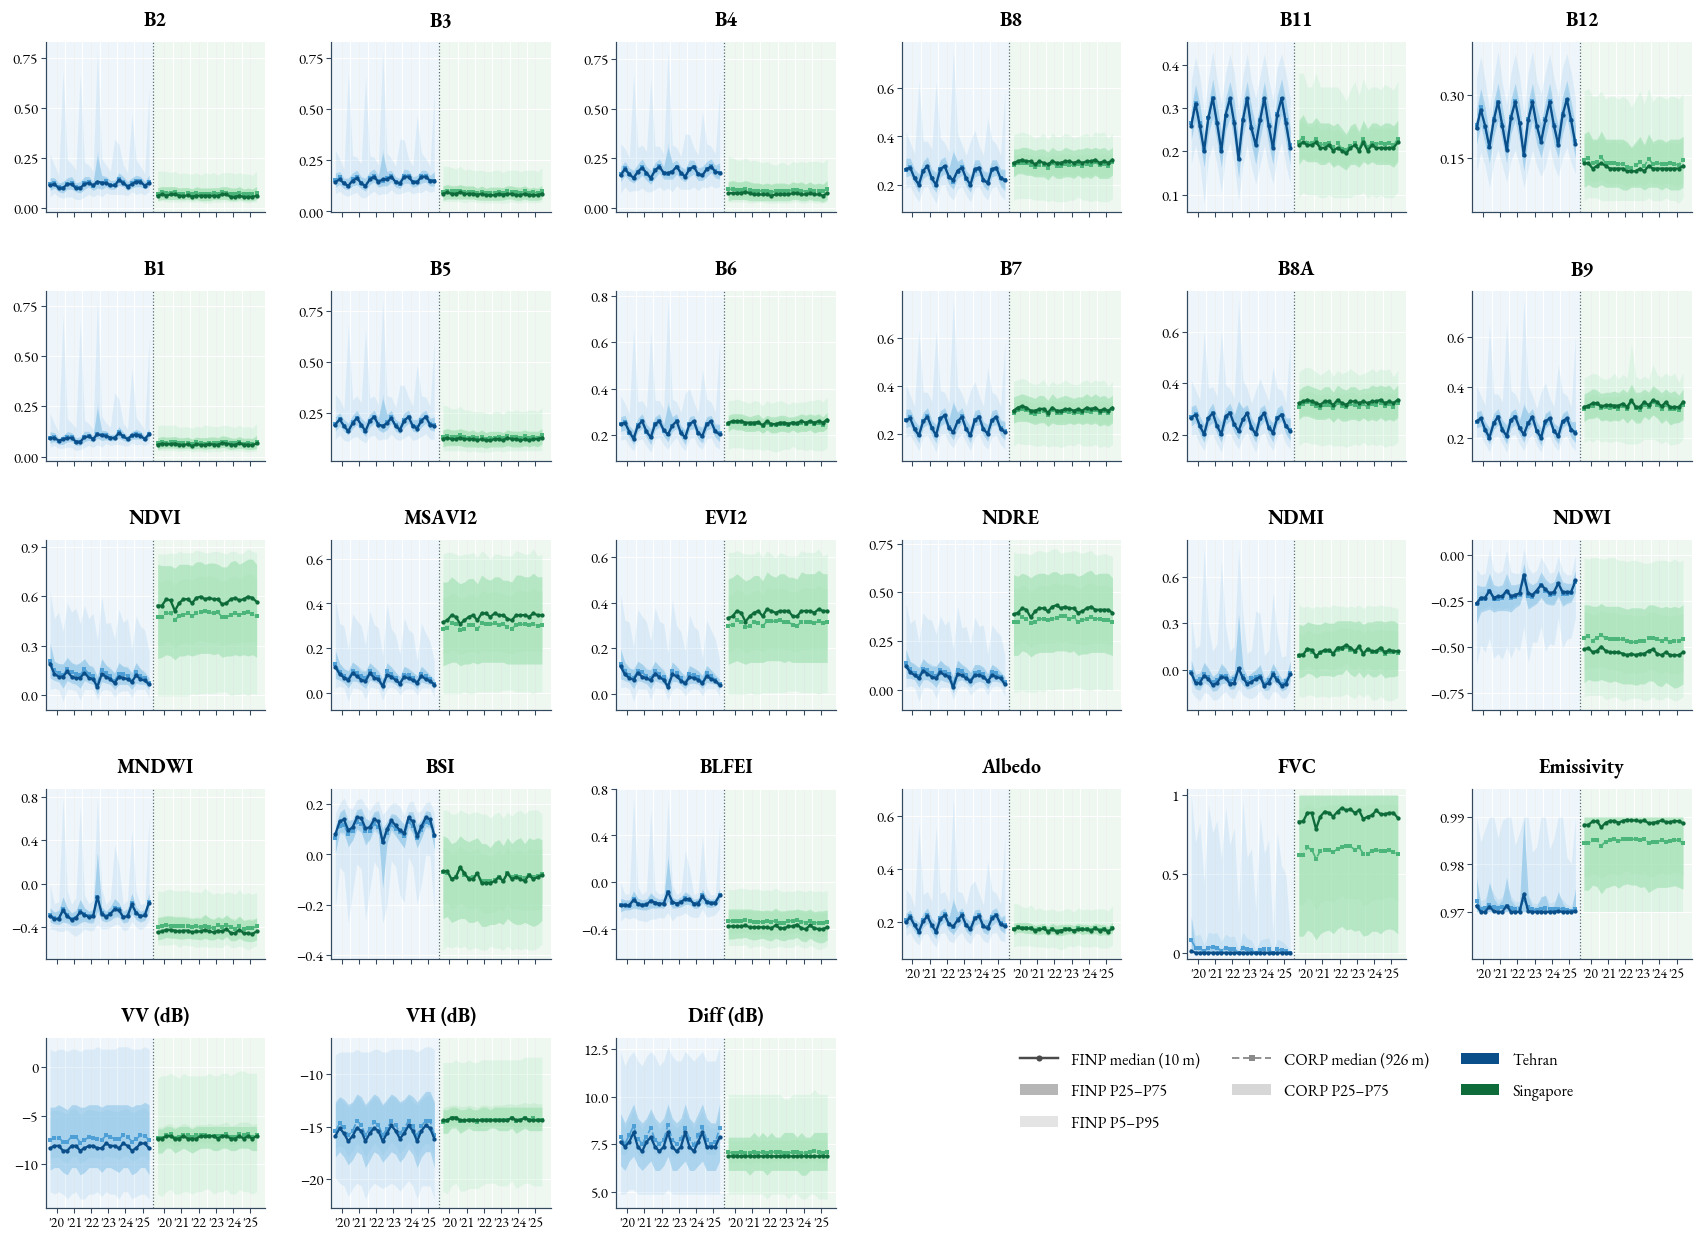

——————————
Cube Audit
——————————

[1] Scope: 2,592 rows | 27 bands | 48 season-years | cities ['Singapore', 'Tehran'] | tiers ['CORP', 'FINP']

[2] Series with missing seasons (expected 24 per Band x City x Tier)
  none

[3] CORP vs FINP seasonal medians (Bias = CORP - FINP, in band units; r = Pearson over seasons)
      Band      City  Seasons    FINP    CORP   Bias   IQR  Bias/IQR      r
        B2 Singapore       24   0.060   0.072  0.012 0.062     0.193  0.805
        B2    Tehran       24   0.117   0.120  0.003 0.058     0.059  0.960
        B3 Singapore       24   0.084   0.095  0.011 0.064     0.170  0.890
        B3    Tehran       24   0.152   0.154  0.003 0.065     0.040  0.974
        B4 Singapore       24   0.070   0.086  0.017 0.090     0.189  0.897
        B4    Tehran       24   0.182   0.182  0.000 0.075     0.001  0.986
        B8 Singapore       24   0.295   0.284 -0.011 0.115    -0.095  0.909
        B8    Tehran       24   0.243   0.242 -0.001 0.075    -0.014  0.993

In [4]:
# ——————————————————
# [§1] Cube Overview
# ——————————————————

RangeBands        = ReflectiveBands + [ 'NDVI' , 'MSAVI2' , 'EVI2' , 'NDRE' , 'NDMI' , 'NDWI' , 'MNDWI' , 'BSI' , 'BLFEI' , 'Albedo' , 'FVC' , 'Emissivity' , 'VV' , 'VH' , 'Diff' ]

Units             = { 'VV' : 'dB' , 'VH' : 'dB' , 'Diff' : 'dB' }

ReflectiveDivisor = 10000

FixedYLim         = { 'FVC' : (-0.04, 1.04) , 'Emissivity' : (0.960, 0.996) }

FixedYTicks       = { 'FVC' : [ 0 , 0.5 , 1 ] , 'Emissivity' : [ 0.97 , 0.98 , 0.99 ] }

Dark              = { 'Tehran' : '#0b4f8a' , 'Singapore' : '#0e6b3a' }

Mid               = { 'Tehran' : '#4d9fd6' , 'Singapore' : '#4cb67a' }

Light             = { 'Tehran' : '#8ec5e8' , 'Singapore' : '#9de0b0' }

Tint              = { 'Tehran' : '#eef5fb' , 'Singapore' : '#eef8f1' }

DividerColor, SpineColor, Ink = '#566573', '#34495e', '#4a4a4a'

Keys = [ 'Band' , 'City' , 'Season_Year' , 'Source' ]

# ————————————
# Data checks
# ————————————

TehranSeasons    = [ f'{S}-{Y}' for Y in Years for S in SeasonOrder['Tehran'] ]

SingaporeSeasons = [ f'{S}-{Y}' for Y in Years for S in SeasonOrder['Singapore'] ]

NTehran          = len(TehranSeasons)

PositionMap = {

    **{SY: I for I, SY in enumerate(TehranSeasons)},

    **{SY: NTehran + 1 + I for I, SY in enumerate(SingaporeSeasons)},

}

Divider = float(NTehran)

Range   = RangeDF.copy()

Range['X'] = Range['Season_Year'].map(PositionMap)

Dropped = int(Range['X'].isna().sum())

if Dropped:

    print(f'WARNING: {Dropped} rows outside the study design were dropped: '
          f"{sorted(Range.loc[Range['X'].isna(), 'Season_Year'].unique())}")

Range = Range.dropna(subset=[ 'X' ]).copy()

Dup = int(Range.duplicated(Keys).sum())

if Dup:

    print(f'WARNING: {Dup} duplicated (Band, City, Season, Source) rows; keeping the first of each.')

    Range = Range.drop_duplicates(Keys).copy()

View = Range.copy()

for B in ReflectiveBands:

    Mask = View['Band'] == B

    for C in [ 'Min' , 'Max' , 'P5' , 'P25' , 'P50' , 'P75' , 'P95' ]:

        View.loc[Mask, C] = View.loc[Mask, C] / ReflectiveDivisor

def FrameLimits(Sub):

    Lo  = Sub[[ 'P5' , 'P25' , 'P50' , 'P75' , 'P95' ]].min().min()

    Hi  = Sub[[ 'P5' , 'P25' , 'P50' , 'P75' , 'P95' ]].max().max()

    Pad = 0.06 * max(Hi - Lo, 1e-9)

    return Lo - Pad, Hi + Pad

# ———————
# Figure
# ———————

Fig = plt.figure(figsize=(15.8, 12.4), facecolor='white')

Grid = GridSpec(5, 6, figure=Fig, left=0.045, right=0.992, top=0.930, bottom=0.075,

                wspace=0.30, hspace=0.46)

YearPositions = [ 1.5 + 4 * I for I in range(6) ] + [ NTehran + 1 + 1.5 + 4 * I for I in range(6) ]

YearLabels    = [ f"'{str(Y)[-2:]}" for Copy in range(2) for Y in Years ]

YearEdges     = [ 3.5 + 4 * I for I in range(5) ] + [ NTehran + 1 + 3.5 + 4 * I for I in range(5) ]

for Index, Band in enumerate(RangeBands):

    Row, Col = divmod(Index, 6)

    Ax  = Fig.add_subplot(Grid[Row, Col])

    Sub = View[View['Band'] == Band]

    Y0, Y1 = FixedYLim.get(Band) or FrameLimits(Sub)

    Ax.set_xlim(-1, 2 * NTehran + 2)

    Ax.set_ylim(Y0, Y1)

    Ax.axvspan(-1, Divider, facecolor=Tint['Tehran'], zorder=0, lw=0)

    Ax.axvspan(Divider, 2 * NTehran + 2, facecolor=Tint['Singapore'], zorder=0, lw=0)

    for XEdge in YearEdges:

        Ax.axvline(XEdge, color='white', lw=0.7, zorder=0.5)

    Ax.axvline(Divider, color=DividerColor, lw=0.8, ls=':', zorder=1)

    for City in [ 'Tehran' , 'Singapore' ]:

        for Source in [ 'CORP' , 'FINP' ]:

            S = Sub[(Sub['City'] == City) & (Sub['Source'] == Source)].sort_values('X')

            if S.empty:

                continue

            X = S['X'].values

            if Source == 'FINP':

                Ax.fill_between(X, S['P5'], S['P95'], color=Light[City], alpha=0.20, lw=0, zorder=2)

                Ax.fill_between(X, S['P25'], S['P75'], color=Light[City], alpha=0.60, lw=0, zorder=2.5)

                Ax.plot(X, S['P50'], color=Dark[City], lw=1.5, marker='o', ms=2.8, mew=0, zorder=5)

            else:

                Ax.fill_between(X, S['P25'], S['P75'], color=Light[City], alpha=0.25, lw=0, zorder=2)

                Ax.plot(X, S['P50'], color=Mid[City], lw=1.1, ls=(0, (4, 2)), marker='s', ms=2.3, mew=0, zorder=4)

    Ax.set_title(Band + (f' ({Units[Band]})' if Band in Units else ''), loc='center',

                 fontsize=13, fontweight='bold', pad=11)

    BottomExposed = Index + 6 >= len(RangeBands)

    Ax.set_xticks(YearPositions)

    Ax.set_xticklabels(YearLabels if BottomExposed else [], fontsize=9, rotation=0, ha='center')

    Ax.tick_params(axis='x', length=3, width=0.7, color=SpineColor, pad=2)

    if Band in FixedYTicks:

        Ax.set_yticks(FixedYTicks[Band])

        Ax.yaxis.set_major_formatter(Ticker.FormatStrFormatter('%.2f' if Band == 'Emissivity' else '%g'))

    else:

        Ax.yaxis.set_major_locator(Ticker.MaxNLocator(nbins=4))

    Ax.tick_params(axis='y', labelsize=10, length=3, width=0.7, color=SpineColor, pad=2)

    for Spine in ('left', 'bottom'):

        Ax.spines[Spine].set_color(SpineColor)

    Ax.grid(axis='y', color='white', lw=0.7, alpha=0.9, zorder=0.6)

    Ax.set_axisbelow(True)

# ———————
# Legend
# ———————

KeyAx = Fig.add_subplot(Grid[4, 3:6])

KeyAx.axis('off')

Handles = [

    Line2D([0], [0], color=Ink, lw=1.6, marker='o', ms=4, mew=0,                          label='FINP median (10 m)'),

    Patch(facecolor=Ink, alpha=0.40, edgecolor='none',                                    label='FINP P25–P75'),

    Patch(facecolor=Ink, alpha=0.15, edgecolor='none',                                    label='FINP P5–P95'),

    Line2D([0], [0], color='#8a8a8a', lw=1.2, ls=(0, (4, 2)), marker='s', ms=3.5, mew=0,  label='CORP median (926 m)'),

    Patch(facecolor=Ink, alpha=0.22, edgecolor='none',                                    label='CORP P25–P75'),

    Patch(facecolor=Dark['Tehran'],    edgecolor='none',                                  label='Tehran'),

    Patch(facecolor=Dark['Singapore'], edgecolor='none',                                  label='Singapore'),

]

KeyAx.legend(handles=Handles, loc='upper center', bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False,

             fontsize=10.5, handlelength=2.4, labelspacing=0.9, columnspacing=2.0)

SaveFigure(Fig, 'Figure 1 Cube Overview')

plt.show()

# —————
# Audit
# —————

print('——————————')
print('Cube Audit')
print('——————————')

Expected = len(Years) * 4

print(f'\n[1] Scope: {len(Range):,} rows | {Range.Band.nunique()} bands | '

      f'{Range.Season_Year.nunique()} season-years | cities {sorted(Range.City.unique())} '

      f'| tiers {sorted(Range.Source.unique())}')

print(f'\n[2] Series with missing seasons (expected {Expected} per Band x City x Tier)')

Counts = Range.groupby([ 'Band' , 'City' , 'Source' ]).size().rename('Seasons').reset_index()

Short  = Counts[Counts.Seasons != Expected]

print(Short.to_string(index=False) if len(Short) else '  none')

# FINP (10 m) vs CORP (926 m): do the two tiers tell the same story?

Keys3 = [ 'Band' , 'City' , 'Season_Year' ]

F = View[View.Source == 'FINP'].set_index(Keys3)[[ 'P25' , 'P50' , 'P75' ]]

C = View[View.Source == 'CORP'].set_index(Keys3)[[ 'P50' ]]

J = F.join(C, how='inner', lsuffix='_F', rsuffix='_C').sort_index()

J['Bias'] = J['P50_C'] - J['P50_F']

J['IQR']  = J['P75'] - J['P25']

Agree = J.groupby([ 'Band' , 'City' ]).agg(

    Seasons=('Bias', 'size'),

    FINP=('P50_F', 'mean'),

    CORP=('P50_C', 'mean'),

    Bias=('Bias', 'mean'),

    IQR=('IQR', 'mean'),

)

Agree['Bias/IQR'] = Agree['Bias'] / Agree['IQR'].replace(0, np.nan)

Agree['r']        = [ J.loc[(B, Cty), 'P50_F'].corr(J.loc[(B, Cty), 'P50_C']) for B, Cty in Agree.index ]

Agree = Agree.reset_index()

Agree['Band'] = pd.Categorical(Agree['Band'], RangeBands, ordered=True)

Agree = Agree.sort_values([ 'Band' , 'City' ]).reset_index(drop=True)

print('\n[3] CORP vs FINP seasonal medians (Bias = CORP - FINP, in band units; r = Pearson over seasons)')

print(Agree.to_string(index=False, float_format=Float3))

print('\n[4] Largest tier disagreements, |Bias| relative to the FINP IQR')

Worst = Agree.reindex(Agree['Bias/IQR'].abs().sort_values(ascending=False).index).head(8)

print(Worst[[ 'Band' , 'City' , 'FINP' , 'CORP' , 'Bias' , 'Bias/IQR' , 'r' ]].to_string(index=False, float_format=Float3))

print('\n[5] Collapsed percentiles (P5 == P95)')

Collapsed = Range[np.isclose(Range.P5, Range.P95)].groupby([ 'Band' , 'City' , 'Source' ]).size().rename('Seasons').reset_index()

print(Collapsed.to_string(index=False) if len(Collapsed) else '  none')

print('\n[6] Flat-quartile seasons (P25 == P75)')

FlatQuartile = Range[np.isclose(Range.P25, Range.P75)].groupby([ 'Band' , 'Source' ]).size().rename('Seasons').reset_index()

print(FlatQuartile.to_string(index=False) if len(FlatQuartile) else '  none')

---

#### **[§2] Composite Coverage**

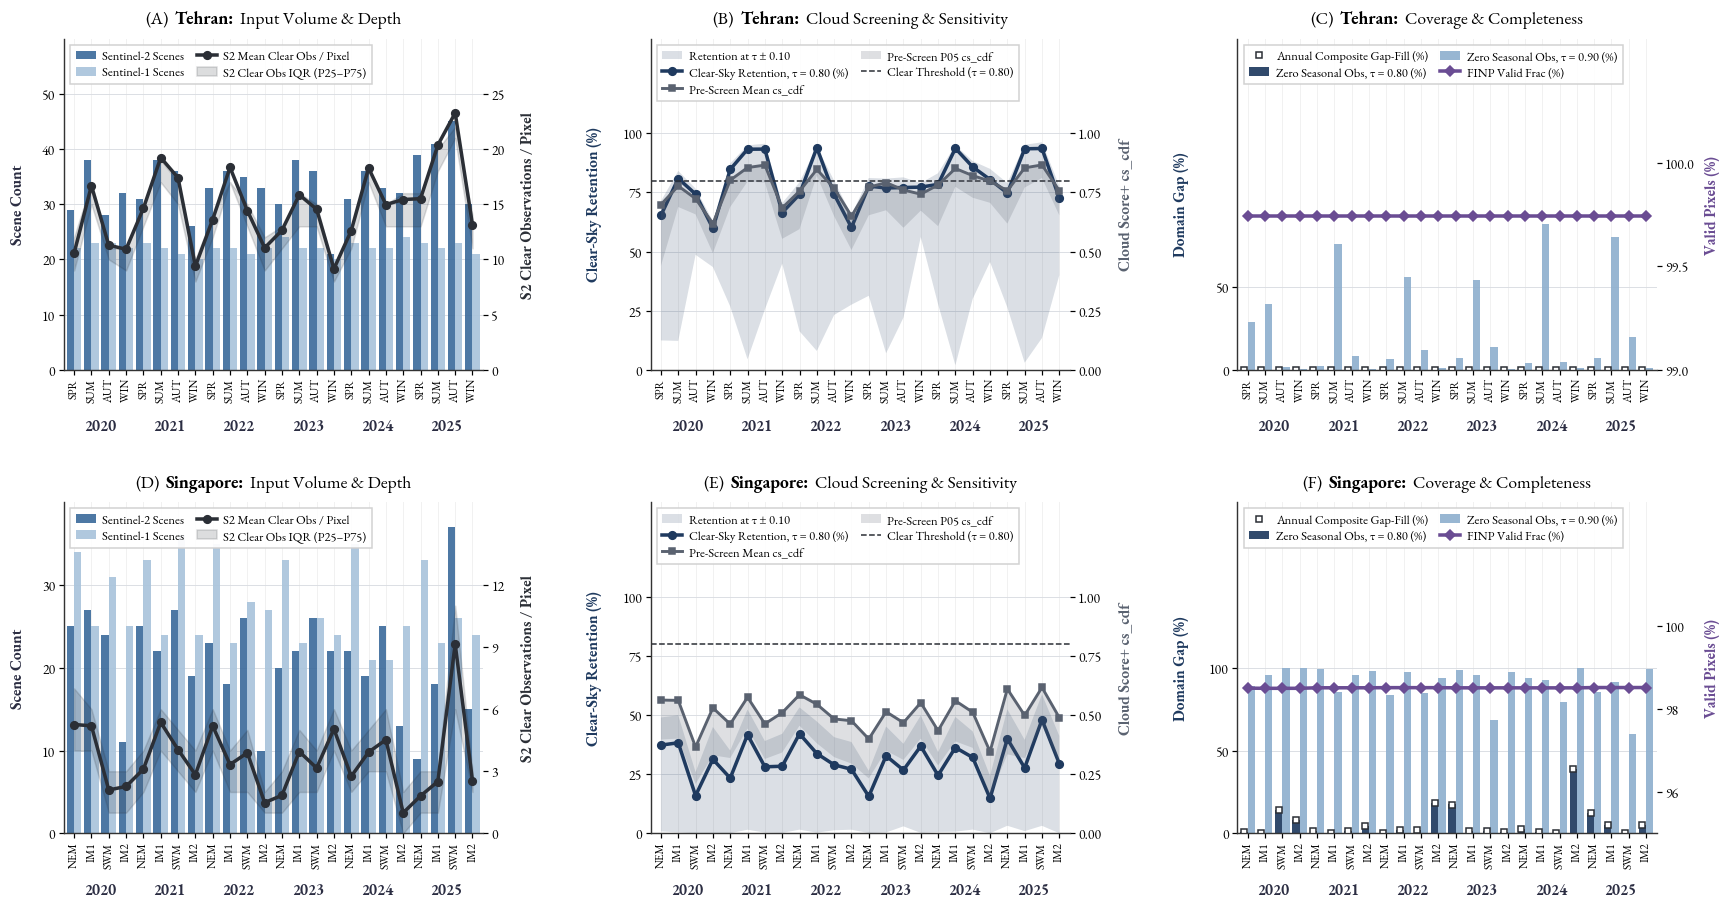

————————————————————————
Composite Coverage Audit
————————————————————————

[1] Coverage & Quality Summary (24 Seasons Per City)

Tehran
  S2Scenes                21–45 (med 33)
  S1Scenes                20–24 (med 22)
  CandObsMean             11.8–24.9 (med 18.5)
  ObsMean                 9.15–23.3 (med 14.6)
  ObsP25                  8–21 (med 13)
  ObsP75                  9–22 (med 15)
  RetentionFrac           0.598–0.939 (med 0.774)
  RetentionFracRelaxed    0.629–0.962 (med 0.812)
  RetentionFracStrict     0.0191–0.562 (med 0.259)
  FracAnyCoverage         1–1 (med 1)
  ZeroObsFrac             0–1.77e-05 (med 0)
  ZeroObsFracRelaxed      0–0 (med 0)
  ZeroObsFracStrict       0.0021–0.878 (med 0.07)
  FilledByAnnualFrac      0–0 (med 0)
  MeanClearSkyConf        0.618–0.866 (med 0.775)
  P05ClearSkyConf         0.439–0.821 (med 0.665)
  FINPValidFrac           0.997–0.997 (med 0.997)

Singapore
  S2Scenes                9–37 (med 22)
  S1Scenes                21–36 (med 25.5)
  C

In [5]:
# ———————————————————————————————————
# [§2] Composite Coverage Diagnostics
# ———————————————————————————————————

if CoverageDF is not None:

    # Layout Constants

    FigSize     = ( 16 , 8.6 )

    TitleSize   = 11.5

    LabelSize   = 10

    TickSize    = 9

    LegendSize  = 8.2

    LineW       = 2.3

    MarkerS     = 5.0

    BarW        = 0.42

    PanelLabels = [ [ '(A)' , '(B)' , '(C)' ] ,

                     [ '(D)' , '(E)' , '(F)' ] ]

    PanelTitles = [ 'Input Volume & Depth' ,

                     'Cloud Screening & Sensitivity',

                     'Coverage & Completeness' ]

    assert CoverageDF['ClearThreshold'].nunique() == 1 and CoverageDF['ThresholdStep'].nunique() == 1

    Tau  = float(CoverageDF['ClearThreshold'].iloc[0])

    Step = float(CoverageDF['ThresholdStep'].iloc[0])

    def StyleTwin( AxLeft , AxRight ):

        AxRight.grid(False)

        AxLeft.set_facecolor('white')

        AxLeft.set_axisbelow(True)

        AxLeft.grid( True , axis = 'y' , color = '#d9dde2' , linewidth = 0.6 )

        AxRight.spines['top'].set_visible(False)

        AxLeft.tick_params( axis = 'both' , labelsize = TickSize , pad = 2 )

        AxRight.tick_params( axis = 'y' , labelsize = TickSize , pad = 2 )

    def MergedLegend( AxLeft , AxRight ):

        H1, L1 = AxLeft.get_legend_handles_labels()

        H2, L2 = AxRight.get_legend_handles_labels()

        Leg    = AxRight.legend( H1 + H2 , L1 + L2 , loc = 'upper left' , ncol = 2 ,

fontsize      = LegendSize , frameon = True , fancybox = False ,

framealpha    = 0.93 , edgecolor = '#cfcfcf'                   ,

borderpad     = 0.45 , labelspacing = 0.35                     ,

columnspacing = 1.0 , handlelength = 1.6 , handletextpad = 0.5 )

        Leg.set_zorder(20)

    def NiceCeil(Value):

        if Value <= 0:

            return 1.0

        Exp  = 10 ** np.floor(np.log10(Value))

        Mant = next(M for M in ( 1 , 2 , 2.5 , 5 , 10 ) if Value / Exp <= M + 1e-9)

        return Mant * Exp

    def TickSet( Lo , Hi , Bins = 4 ):

        Raw = Ticker.MaxNLocator( nbins = Bins , steps = [ 1 , 2 , 5 , 10 ] ).tick_values( Lo , Hi )

        return [ T for T in Raw if Lo - 1e-9 <= T <= Hi + 1e-9 ]

    def DecimalsFor(Ticks):

        return int(max( 0 , -np.floor(np.log10(abs(Ticks[1] - Ticks[0]))) ))

    def PanelTitle( Ax , Row , Col , City ):

        Box = AnchoredOffsetbox( loc = 'lower center',

                                child = HPacker( children = [ TextArea( PanelLabels[Row][Col] , textprops = dict( fontsize = TitleSize ) ) ,

                                TextArea( f'{City}:' , textprops = dict( fontsize = TitleSize , fontweight = 'bold' ) ) ,

                                TextArea( PanelTitles[Col] , textprops = dict( fontsize = TitleSize ) )] ,align = 'baseline' , pad = 0 , sep = 4 )      ,pad   = 0 , borderpad = 0.6 , frameon = False ,                                bbox_to_anchor = ( 0.5 , 1.0 ), bbox_transform=Ax.transAxes ,prop           = dict( size = TitleSize ))

        Ax.add_artist(Box)

        Box.set_clip_on(False)

    Fig, Axes = plt.subplots( 2 , 3 , figsize = FigSize )

    for RowIdx, City in enumerate(Cities):

        Sub = CoverageDF[CoverageDF['City'] == City].copy()

        Sub = Sub.sort_values( 'Season_Year' , key = lambda S: S.map(SeasonSortKey(City)) )

        X   = np.arange(len(Sub))

        # Column 1: Input Volume & Observation Depth

        AxLeft  = Axes[RowIdx, 0]

        AxRight = AxLeft.twinx()

        StyleTwin( AxLeft , AxRight )

        AxLeft.bar( X - BarW / 2 , Sub['S2Scenes'] , width = BarW , color = '#3E6C9C' , alpha = 0.92 , label = 'Sentinel-2 Scenes' , edgecolor = 'none' )

        AxLeft.bar( X + BarW / 2 , Sub['S1Scenes'] , width = BarW , color = '#A9C4DC' , alpha = 0.92 , label = 'Sentinel-1 Scenes' , edgecolor = 'none' )

        AxLeft.set_ylabel( 'Scene Count' , color = '#2b2d42' , fontweight = 'bold' , fontsize = LabelSize , labelpad = 3 )

        AxRight.plot( X , Sub['ObsMean'] , 'o-' , color = '#2B2F36' , linewidth = LineW , markersize = MarkerS , label = 'S2 Mean Clear Obs / Pixel' , zorder = 5 )

        AxRight.fill_between( X , Sub['ObsP25'] , Sub['ObsP75'] , color = '#2B2F36' , alpha = 0.16 , label = 'S2 Clear Obs IQR (P25–P75)' , zorder = 4 )

        AxRight.set_ylabel( 'S2 Clear Observations / Pixel' , color = '#2B2F36' , fontweight = 'bold' , fontsize = LabelSize , labelpad = 3 )

        AxLeft.yaxis.set_label_coords( -0.090 , 0.5 )

        AxRight.yaxis.set_label_coords( 1.090 , 0.5 )

        if City == 'Tehran':

            AxLeft.set_ylim( 0 , 60 );   AxLeft.set_yticks(np.arange( 0 , 51 , 10 ))

            AxRight.set_ylim( 0 , 30 );  AxRight.set_yticks(np.arange( 0 , 26 , 5 ))

        else:

            AxLeft.set_ylim( 0 , 40 );   AxLeft.set_yticks(np.arange( 0 , 31 , 10 ))

            AxRight.set_ylim( 0 , 16 );  AxRight.set_yticks(np.arange( 0 , 13 , 3 ))

        AxLeft.set_xlim( -0.6 , len(Sub) - 0.4 )

        PanelTitle( AxLeft , RowIdx , 0 , City )

        MergedLegend( AxLeft , AxRight )

        # Column 2: Cloud Screening & Threshold Sensitivity

        AxLeft  = Axes[RowIdx, 1]

        AxRight = AxLeft.twinx()

        StyleTwin( AxLeft , AxRight )

        AxLeft.fill_between( X , Sub['RetentionFracStrict'] * 100 , Sub['RetentionFracRelaxed'] * 100 , color = '#1F3A5F' , alpha = 0.16 , label = f'Retention at τ ± {Step:.2f}' , edgecolor = 'none' , zorder = 3 )

        AxLeft.plot( X , Sub['RetentionFrac'] * 100 , 'o-' , color = '#1F3A5F' , linewidth = LineW , markersize = MarkerS , label = f'Clear-Sky Retention, τ = {Tau:.2f} (%)' , zorder = 5 )

        AxLeft.set_ylabel( 'Clear-Sky Retention (%)' , color = '#1F3A5F' , fontweight = 'bold' , fontsize = LabelSize , labelpad = 3 )

        AxRight.plot( X , Sub['MeanClearSkyConf'] , 's-' , color = '#5A6270' , linewidth = LineW - 0.4 , markersize = MarkerS - 1.0 , label = 'Pre-Screen Mean cs_cdf' , zorder = 4 )

        AxRight.fill_between( X , Sub['P05ClearSkyConf'] , Sub['MeanClearSkyConf'] , color = '#5A6270' , alpha = 0.20 , label = 'Pre-Screen P05 cs_cdf' , edgecolor = 'none' , zorder = 3 )

        AxRight.axhline( Tau , color = '#2B2F36' , linewidth = 1.0 , linestyle = '--' , label = f'Clear Threshold (τ = {Tau:.2f})' , zorder = 2 )

        AxRight.set_ylabel( 'Cloud Score+ cs_cdf' , color = '#5A6270' , fontweight = 'bold' , fontsize = LabelSize , labelpad = 3 )

        AxLeft.yaxis.set_label_coords( -0.115 , 0.5 )

        AxRight.yaxis.set_label_coords( 1.115 , 0.5 )

        AxLeft.set_ylim( 0 , 140 );   AxLeft.set_yticks(np.arange( 0 , 101 , 25 ))

        AxRight.set_ylim( 0 , 1.4 );  AxRight.set_yticks(np.arange( 0 , 1.01 , 0.25 ))

        AxRight.yaxis.set_major_formatter(Ticker.FormatStrFormatter('%.2f'))

        AxLeft.set_xlim( -0.6 , len(Sub) - 0.4 )

        PanelTitle( AxLeft , RowIdx , 1 , City )

        MergedLegend( AxLeft , AxRight )

        # Column 3: Coverage Accounting & Product Completeness

        AxLeft  = Axes[RowIdx, 2]

        AxRight = AxLeft.twinx()

        StyleTwin( AxLeft , AxRight )

        ZeroMax = max( float(Sub['ZeroObsFrac'].max()) , float(Sub['ZeroObsFracStrict'].max()) ) * 100

        ZeroMax = ZeroMax if ZeroMax > 0 else 1.0

        AxLeft.bar( X - BarW / 2 , Sub['ZeroObsFrac'] * 100 , width = BarW , color = '#1F3A5F' , alpha = 0.92 , label = f'Zero Seasonal Obs, τ = {Tau:.2f} (%)' , edgecolor = 'none' )

        AxLeft.bar( X + BarW / 2 , Sub['ZeroObsFracStrict'] * 100 , width = BarW , color = '#8FB0CF' , alpha = 0.92 , label = f'Zero Seasonal Obs, τ = {Tau + Step:.2f} (%)' , edgecolor = 'none' )

        AxLeft.plot( X - BarW / 2 , Sub['FilledByAnnualFrac'] * 100 , linestyle = 'none' , marker = 's' , markersize = MarkerS - 1.0 , markerfacecolor = 'white' , markeredgecolor = '#2B2F36' , markeredgewidth = 1.0 , label = 'Annual Composite Gap-Fill (%)' , zorder = 6 )

        AxLeft.set_ylabel( 'Domain Gap (%)' , color = '#1F3A5F' , fontweight = 'bold' , fontsize = LabelSize , labelpad = 3 )

        LeftTicks = TickSet( 0 , ZeroMax * 1.05 )

        AxLeft.set_ylim( 0 , NiceCeil(ZeroMax * 1.5) )

        AxLeft.set_yticks(LeftTicks)

        AxLeft.yaxis.set_major_formatter(Ticker.FormatStrFormatter(f'%.{DecimalsFor(LeftTicks)}f'))

        AxRight.plot( X , Sub['FINPValidFrac'] * 100 , 'D-' , color = '#6A4C93' , linewidth = LineW , markersize = MarkerS - 0.5 , label = 'FINP Valid Frac (%)' , zorder = 5 )

        AxRight.set_ylabel( 'Valid Pixels (%)' , color = '#6A4C93' , fontweight = 'bold' , fontsize = LabelSize , labelpad = 3 )

        FinpSpan   = max( NiceCeil((100 - float(Sub['FINPValidFrac'].min()) * 100) * 3) , 1.0 )

        RightTicks = TickSet( 100 - FinpSpan , 100 )

        AxRight.set_ylim( 100 - FinpSpan , 100 + FinpSpan * 0.6 )

        AxRight.set_yticks(RightTicks)

        AxRight.yaxis.set_major_formatter(Ticker.FormatStrFormatter(f'%.{DecimalsFor(RightTicks)}f'))

        AxLeft.yaxis.set_label_coords( -0.115 , 0.5 )

        AxRight.yaxis.set_label_coords( 1.115 , 0.5 )

        AxLeft.set_xlim( -0.6 , len(Sub) - 0.4 )

        PanelTitle( AxLeft , RowIdx , 2 , City )

        MergedLegend( AxLeft , AxRight )

        for RowAx in Axes[RowIdx]:

            AddTwoLevelAxis( RowAx , Sub , YearY = -0.15 )

            for T in RowAx.texts:

                if abs(T.get_position()[1] + 0.15) < 1e-9:

                    T.set_fontsize(T.get_fontsize() + 2.0)

    Fig.subplots_adjust( left = 0.050 , right = 0.955 , bottom = 0.100 , top = 0.940 , hspace = 0.40 , wspace = 0.40 )

    SaveFigure( Fig , 'Figure 2 Composite Coverage' )

    plt.show()

    # —————
    # Audit
    # —————

    print('————————————————————————')
    print('Composite Coverage Audit')
    print('————————————————————————')

    print('\n[1] Coverage & Quality Summary (24 Seasons Per City)')

    for City in Cities:

        Sub = CoverageDF[CoverageDF.City == City]

        print(f'\n{City}')

        for Column in [ 'S2Scenes' , 'S1Scenes' , 'CandObsMean' , 'ObsMean' , 'ObsP25' , 'ObsP75' , 'RetentionFrac' , 'RetentionFracRelaxed' , 'RetentionFracStrict' , 'FracAnyCoverage' , 'ZeroObsFrac' , 'ZeroObsFracRelaxed' , 'ZeroObsFracStrict' , 'FilledByAnnualFrac' , 'MeanClearSkyConf' , 'P05ClearSkyConf' , 'FINPValidFrac' ]:

            print(f'  {Column:<24}{DescribeRange(Sub[Column])}')

    print('\n[2] Derived Checks')

    MaxGap = (CoverageDF.ZeroObsFrac - CoverageDF.FilledByAnnualFrac).abs().max()

    print(f'  Max |Zero-Obs-Frac − Filled-By-Annual-Frac| = {MaxGap:.5f}')

    print(f'  Clear Threshold τ = {Tau:.2f} ± {Step:.2f}')

    Ordered = ((CoverageDF.RetentionFracRelaxed >= CoverageDF.RetentionFrac) & (CoverageDF.RetentionFrac >= CoverageDF.RetentionFracStrict)).all()

    print(f'  Retention Ordered (Relaxed ≥ τ ≥ Strict): {Ordered}')

    for City in Cities:

        Sub = CoverageDF[CoverageDF.City == City]

        print(f'  {City} — Minimum Any-Coverage = {Sub.FracAnyCoverage.min():.4f}')

        print(f'  {City} — Minimum Retention = {Sub.RetentionFrac.min():.4f}')

        print(f'  {City} — Minimum FINP-Valid-Frac = {Sub.FINPValidFrac.min():.4f}')

        Worst = Sub.loc[Sub.ZeroObsFrac.idxmax()]

        print(f'  {City} — Worst-Season Zero-Obs-Frac = {Worst.ZeroObsFrac:.4f} ({Worst.SeasonYear})')

    Tehran    = CoverageDF[CoverageDF.City == 'Tehran']

    Singapore = CoverageDF[CoverageDF.City == 'Singapore']

    print(f'\n  Tehran Composites with Zero-Obs-Frac = 0: {(Tehran.ZeroObsFrac == 0).sum()} / {len(Tehran)}')

    print(f'  Singapore Composites with Zero-Obs-Frac > 0.10: {(Singapore.ZeroObsFrac > 0.10).sum()} / {len(Singapore)}')

    print(f'  Singapore Composites with FINP-Valid-Frac < 0.986: {(Singapore.FINPValidFrac < 0.986).sum()} / {len(Singapore)}')

---

#### **[§3] SAR Speckle Suppression**

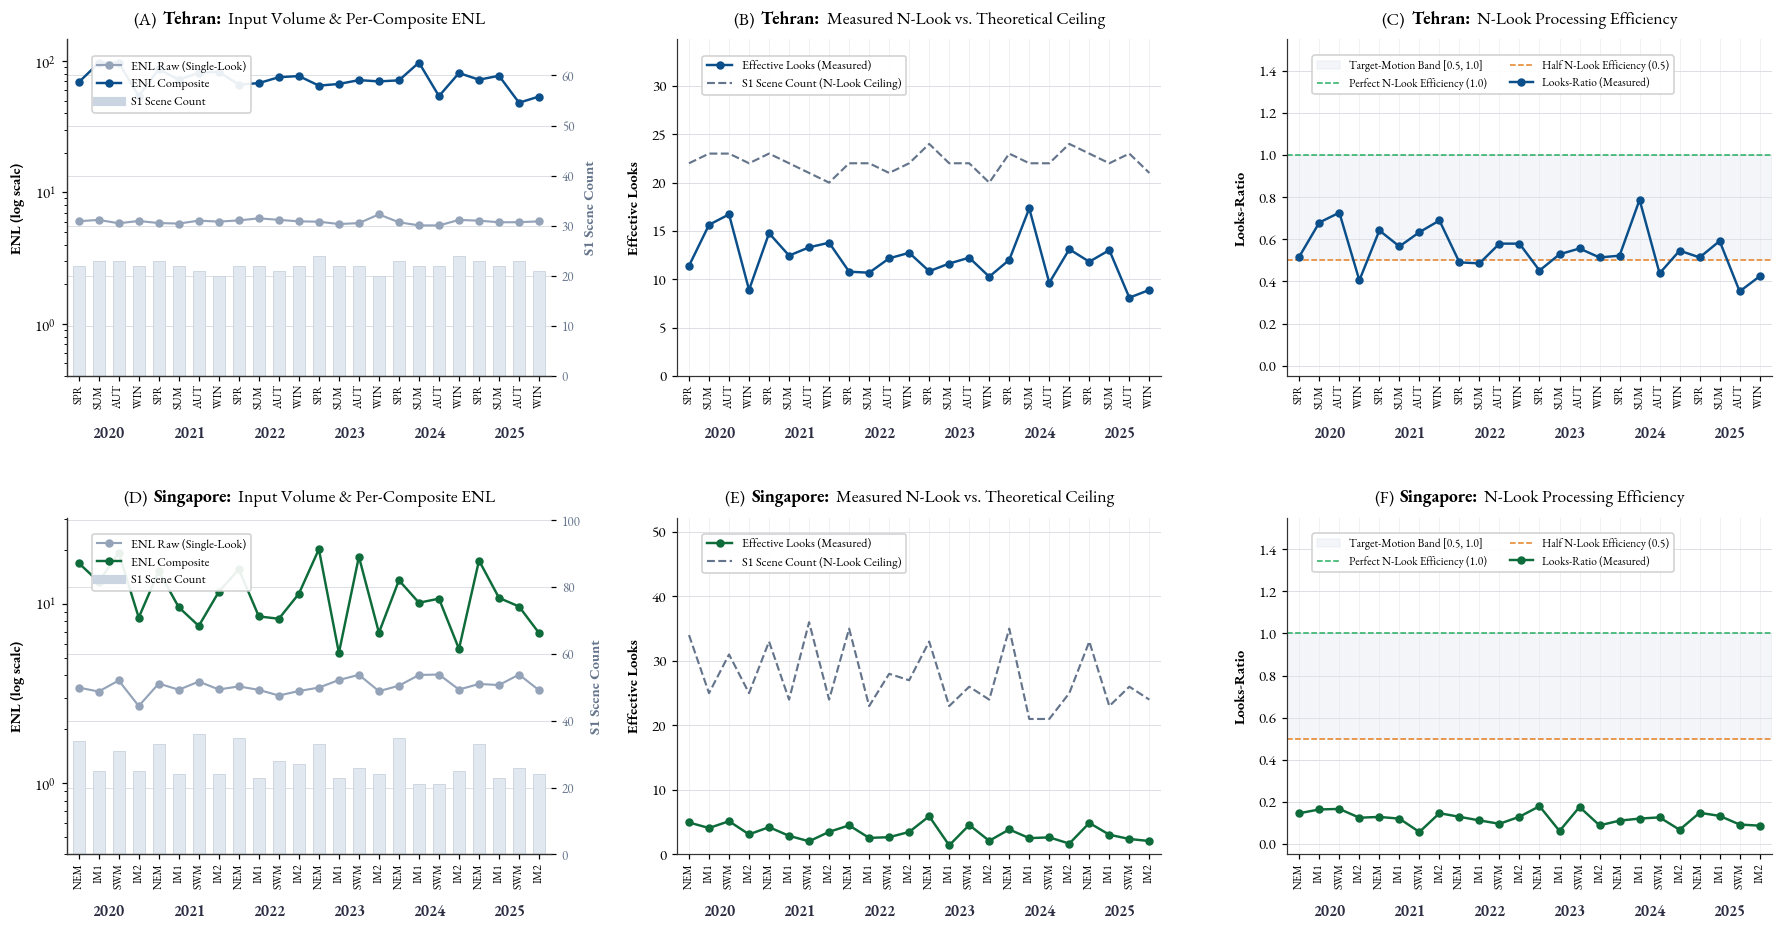

—————————————————————————————
SAR Speckle Suppression Audit
—————————————————————————————

Tehran:

  S1-Scenes       : 20 – 24
  ENL-Raw         : 5.61 – 6.81
  ENL-Composite   : 48.21 – 97.50
  Effective-Looks : 8.11 – 17.34
  Looks-Ratio     : 0.353 – 0.788

Singapore:

  S1-Scenes       : 21 – 36
  ENL-Raw         : 2.70 – 4.04
  ENL-Composite   : 5.33 – 20.23
  Effective-Looks : 1.42 – 5.92
  Looks-Ratio     : 0.057 – 0.179

Tehran:

Season_Year   City  S1_Scenes  ENL_Raw  ENL_Composite  Effective_Looks  Looks_Ratio SeasonYear  S1Scenes  ENLRaw  ENLComposite  EffectiveLooks  LooksRatio
   SPR-2020 Tehran         22  6.04427        68.9273          11.4037     0.518351   SPR-2020        22 6.04427       68.9273         11.4037    0.518351
   SUM-2020 Tehran         23  6.18314        96.7181          15.6422     0.680098   SUM-2020        23 6.18314       96.7181         15.6422    0.680098
   AUT-2020 Tehran         23  5.83139        97.4992          16.7197     0.726945   AUT-20

In [6]:
# ————————————————————————————
# [§3] SAR Speckle Suppression
# ————————————————————————————

if ENLDF is not None:

    Fig, Axes    = plt.subplots( 2 , 3 , figsize = ( 20 , 9.5 ) , gridspec_kw = {'wspace': 0.26, 'hspace': 0.42} )

    PanelLetters = [ [ '(A)' , '(B)' , '(C)' ] , [ '(D)' , '(E)' , '(F)' ] ]

    MetricTitles = [ 'Input Volume & Per-Composite ENL' , 'Measured N-Look vs. Theoretical Ceiling' , 'N-Look Processing Efficiency' ]

    def PanelTitle( Ax , Row , Col , City ):

        Box = AnchoredOffsetbox( loc = 'lower center' , child = HPacker( children = [ TextArea( PanelLetters[Row][Col] , textprops = dict( fontsize = 11.5 , fontweight = 'normal' ) ) ,

             TextArea( f'{City}:' , textprops = dict( fontsize = 11.5 , fontweight = 'bold' ) ) , TextArea( MetricTitles[Col] , textprops = dict( fontsize = 11.5 , fontweight = 'normal' ) )],

align = 'baseline' , pad = 0 , sep = 4 )      ,

pad   = 0 , borderpad = 0.6 , frameon = False ,

                                bbox_to_anchor = ( 0.5 , 1.0 ), bbox_transform=Ax.transAxes ,

                                prop           = dict( size = 11.5 ))

        Ax.add_artist(Box)

        Box.set_clip_on(False)

    for Row, City in enumerate(Cities):

        Sub     = ENLDF[ENLDF['City'] == City].copy()

        Sub     = Sub.sort_values( 'Season_Year' , key = lambda S: S.map(SeasonSortKey(City)) ).reset_index( drop = True )

        X       = np.arange(len(Sub))

        Colour  = CityPalette[City]

        Ax      = Axes[Row, 0]

        AxRight = Ax.twinx()

        AxRight.set_axisbelow(True)

        AxRight.grid( True , axis = 'y' , color = '#d9dde2' , linewidth = 0.6 )

        Ax.grid(False)

        AxRight.bar( X , Sub['S1Scenes'] , width = 0.6 , color = '#e2e8f0' , edgecolor = '#cbd5e1' , linewidth = 0.6 , label = 'S1 Scene Count' , zorder = 1 )

        AxRight.set_ylabel( 'S1 Scene Count' , color = '#64748b' , fontsize = 9.5 , labelpad = 6 , fontweight = 'bold' )

        AxRight.tick_params( axis = 'y' , labelcolor = '#64748b' , labelsize = 8.5 )

        AxRight.set_ylim( 0 , Sub['S1Scenes'].max() * 2.8 )

        Ax.set_zorder(AxRight.get_zorder() + 1)

        Ax.patch.set_visible(False)

        Ax.plot( X , Sub['ENLRaw'] , 'o-' , color = '#94a3b8' , markersize = 4.5 , linewidth = 1.4 , label = 'ENL Raw (Single-Look)' , zorder = 3 )

        Ax.plot( X , Sub['ENLComposite'] , 'o-' , color = Colour , markersize = 4.5 , linewidth = 1.6 , label = 'ENL Composite' , zorder = 4 )

        Ax.set_yscale('log')

        Ax.set_ylabel( 'ENL (log scale)' , fontsize = 9.5 , labelpad = 6 , fontweight = 'bold' )

        PanelTitle( Ax , Row , 0 , City )

        Ax.set_ylim( 0.4 , Sub['ENLComposite'].max() * 1.5 )

        Handles = [

            Line2D( [ 0 ] , [ 0 ] , color = '#94a3b8' , marker = 'o' , lw = 1.4 , markersize = 4.5 , label = 'ENL Raw (Single-Look)' ),

            Line2D( [ 0 ] , [ 0 ] , color = Colour , marker = 'o' , lw = 1.6 , markersize = 4.5 , label = 'ENL Composite' ),

            Line2D( [ 0 ] , [ 0 ] , color = '#cbd5e1' , lw = 6 , label = 'S1 Scene Count' ),

        ]

        StyledLegend( Ax , handles = Handles , fontsize = 8 , loc = 'upper left' , bbox_to_anchor = ( 0.04 , 0.97 ) )

        Ax = Axes[Row, 1]

        Ax.set_axisbelow(True)

        Ax.grid( True , axis = 'y' , color = '#d9dde2' , linewidth = 0.6 )

        Ax.plot( X , Sub['EffectiveLooks'] , 'o-' , color = Colour , markersize = 4.5 , linewidth = 1.6 , label = 'Effective Looks (Measured)' , zorder = 4 )

        Ax.plot( X , Sub['S1Scenes'] , '--' , color = '#64748b' , linewidth = 1.4 , label = 'S1 Scene Count (N-Look Ceiling)' , zorder = 3 )

        Ax.set_ylabel( 'Effective Looks' , fontsize = 9.5 , labelpad = 6 , fontweight = 'bold' )

        PanelTitle( Ax , Row , 1 , City )

        MaxLooks = max( Sub['EffectiveLooks'].max() , Sub['S1Scenes'].max() )

        Ax.set_ylim( 0 , MaxLooks * 1.45 )

        StyledLegend( Ax , fontsize = 8 , loc = 'upper left' , bbox_to_anchor = ( 0.04 , 0.97 ) )

        Ax = Axes[Row, 2]

        Ax.set_axisbelow(True)

        Ax.grid( True , axis = 'y' , color = '#d9dde2' , linewidth = 0.6 )

        Ax.axhspan( 0.5 , 1.0 , color = '#e2e8f0' , alpha = 0.4 , label = 'Target-Motion Band [0.5, 1.0]' , zorder = 1 )

        Ax.axhline( 1.0 , color = '#27ae60' , lw = 1.0 , linestyle = '--' , label = 'Perfect N-Look Efficiency (1.0)' , zorder = 2 )

        Ax.axhline( 0.5 , color = '#e67e22' , lw = 1.0 , linestyle = '--' , label = 'Half N-Look Efficiency (0.5)' , zorder = 2 )

        Ax.plot( X , Sub['LooksRatio'] , 'o-' , color = Colour , markersize = 4.5 , linewidth = 1.6 , label = 'Looks-Ratio (Measured)' , zorder = 4 )

        Ax.set_ylabel( 'Looks-Ratio' , fontsize = 9.5 , labelpad = 6 , fontweight = 'bold' )

        PanelTitle( Ax , Row , 2 , City )

        Ax.set_ylim( -0.05 , 1.55 )

        StyledLegend( Ax , fontsize = 7.5 , loc = 'upper left' , bbox_to_anchor = ( 0.04 , 0.97 ) , ncol = 2 )

        for ColIdx in range(3):

            AddTwoLevelAxis( Axes[Row, ColIdx] , Sub , YearY = -0.15 )

            for T in Axes[Row, ColIdx].texts:

                if abs(T.get_position()[1] + 0.15) < 1e-9:

                    T.set_fontsize(T.get_fontsize() + 2.0)

    plt.tight_layout()

    Fig.subplots_adjust( bottom = 0.10 , hspace = 0.42 , wspace = 0.26 )

    SaveFigure( Fig , 'Figure 3 Speckle Suppression' )

    plt.show()

    # —————
    # Audit
    # —————

    print('—————————————————————————————')
    print('SAR Speckle Suppression Audit')
    print('—————————————————————————————')

    for City in Cities:

        S = ENLDF[ENLDF['City'] == City]

        print(f'\n{City}:\n')

        print(f'  S1-Scenes       : {S.S1Scenes.min():.0f} – {S.S1Scenes.max():.0f}')

        print(f'  ENL-Raw         : {S.ENLRaw.min():.2f} – {S.ENLRaw.max():.2f}')

        print(f'  ENL-Composite   : {S.ENLComposite.min():.2f} – {S.ENLComposite.max():.2f}')

        print(f'  Effective-Looks : {S.EffectiveLooks.min():.2f} – {S.EffectiveLooks.max():.2f}')

        print(f'  Looks-Ratio     : {S.LooksRatio.min():.3f} – {S.LooksRatio.max():.3f}')

    for City in Cities:

        print(f'\n{City}:\n')

        print(OrderedFrame( ENLDF , City ).to_string( index = False , float_format = General6 ))

    print('\n[Implied Ratios Recomputed]')

    for City in Cities:

        S                    = ENLDF[ENLDF['City'] == City].copy()

        S['RatioRecomputed'] = S['EffectiveLooks'] / S['S1Scenes'].replace( 0 , np.nan )
        
        S['RatioDelta']      = S['RatioRecomputed'] - S['LooksRatio']

        MaxDelta             = S['RatioDelta'].abs().max()

        State                = 'OK' if MaxDelta < 1e-6 else 'MISMATCH'

        print(f'  {City}: max |LooksRatio − EffectiveLooks/S1Scenes| = {MaxDelta:.3g} ({State})')

---

#### **[§4] Interannual Temporal Consistency**

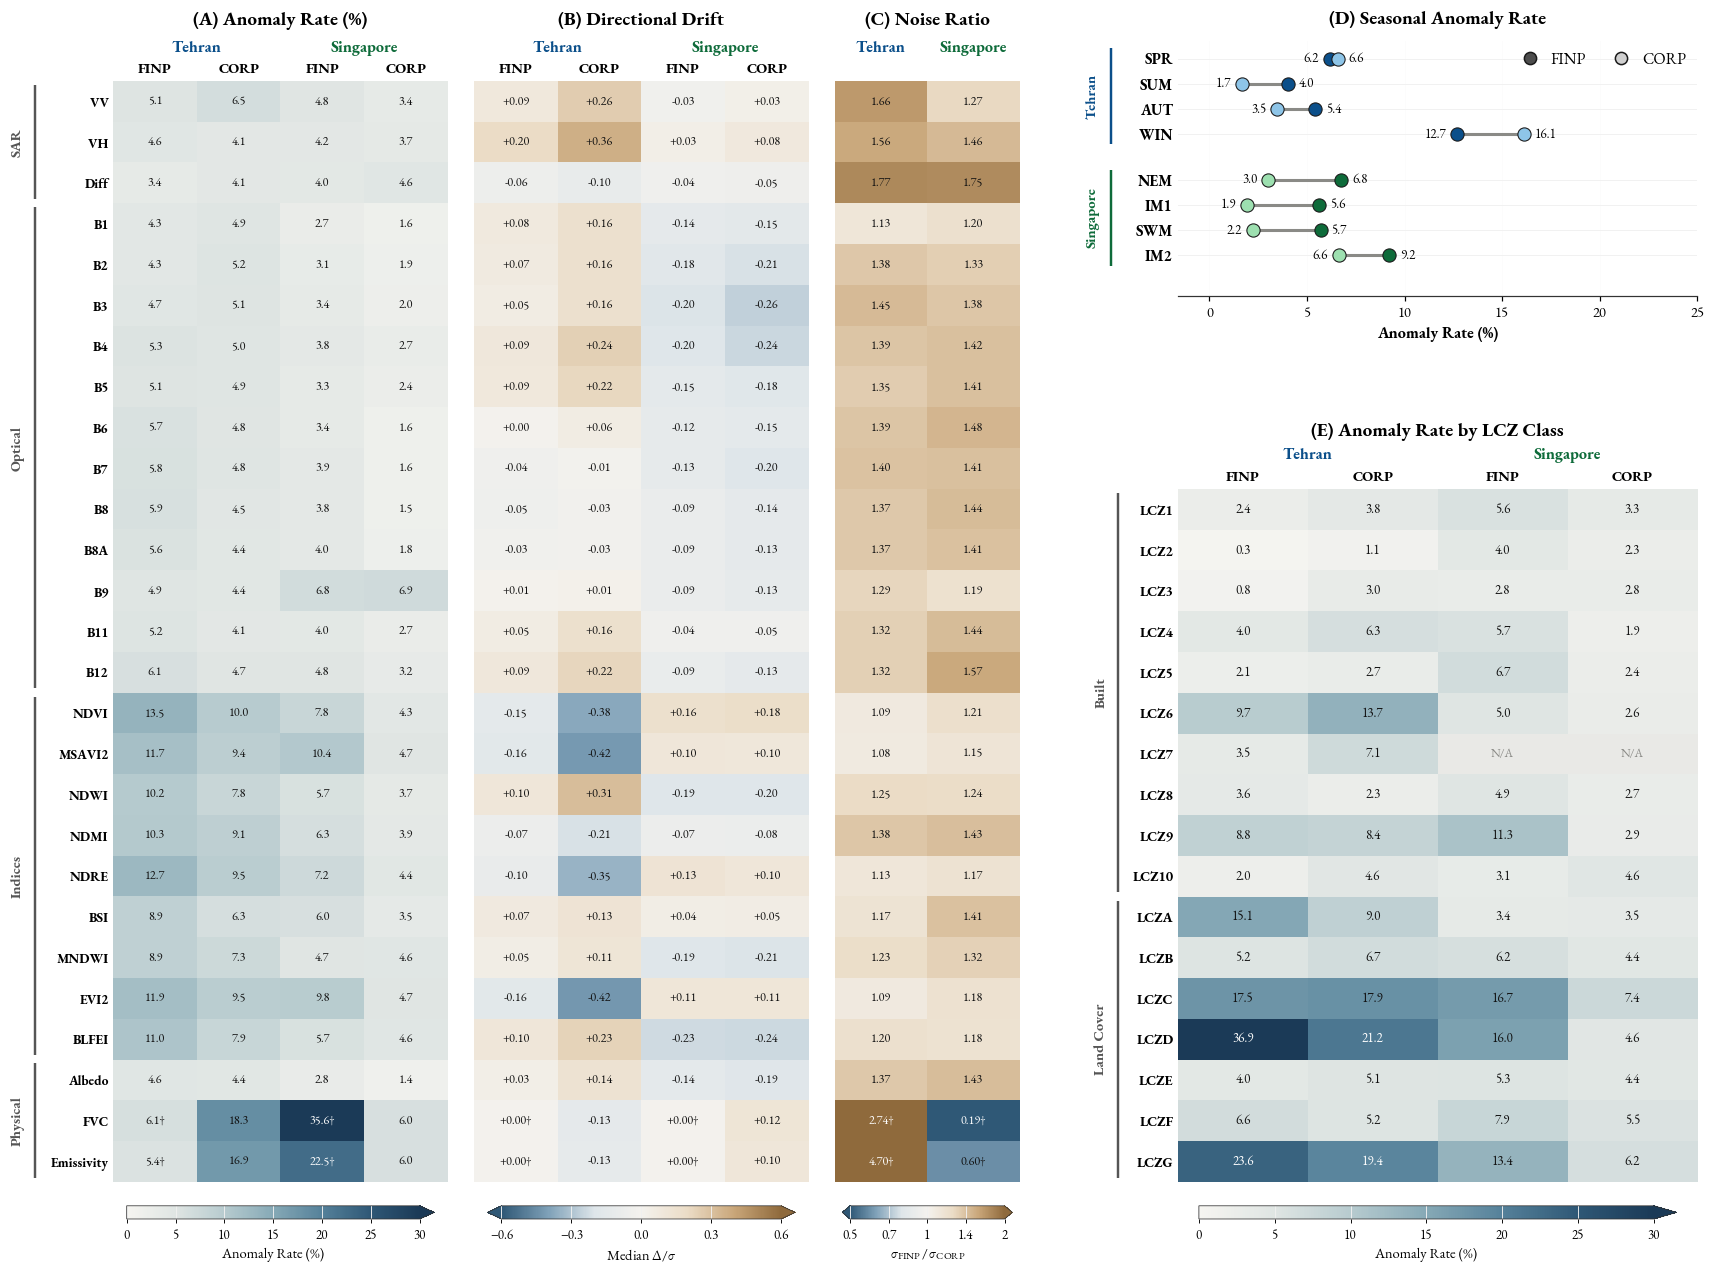

——————————————————————————
Temporal Consistency Audit
——————————————————————————

[1] Sample Size & Scope
  - Total Year-Over-Year Delta Records  : 802,440
  - ...With a Defined Sigma             : 802,440
  - Unique TIRPs Evaluated              : 405
  - Cities Covered                      : ['Singapore', 'Tehran']

[2] Global Temporal Anomaly Rate (|delta/sigma| > 3)
  - Total Anomaly Violations            : 48,205 / 802,440
  - Global Anomaly Percentage           : 6.01%   (Gaussian Expectation 0.27%)

[3] Anomaly Breakdown By City & Tier
  - Tehran     | FINP  : N = 184,680 | Anomalies = 13,075 ( 7.08%) | Median Sigma = 0.3269
  - Tehran     | CORP  : N = 184,680 | Anomalies = 12,862 ( 6.96%) | Median Sigma = 0.1847
  - Singapore  | FINP  : N = 216,540 | Anomalies = 14,783 ( 6.83%) | Median Sigma = 0.3017
  - Singapore  | CORP  : N = 216,540 | Anomalies = 7,485 ( 3.46%) | Median Sigma = 0.1958

[4] Top 5 Most Unstable Bands († = Degenerate Sigma)
  - FVC†       : Anomaly Rate = 16.

In [7]:
# —————————————————————————————————————
# [§4] Interannual Temporal Consistency
# —————————————————————————————————————

if TIRPDF is not None:

    ZeroFlagThreshold = 0.25

    SigmaFallback     = True

    Dagger            = '\u2020'

    Combos            = [ ( 'Tehran' , 'FINP' , '#0b4f8a' ) , ( 'Tehran' , 'CORP' , '#8ec5e8' ) , ( 'Singapore' , 'FINP' , '#0e6b3a' ) , ( 'Singapore' , 'CORP' , '#9de0b0' )

    ]

    CityDark       = {C: Col for C, S, Col in Combos if S == 'FINP'}

    CityLight      = {C: Col for C, S, Col in Combos if S == 'CORP'}

    TIRP           = TIRPDF.copy()

    Split          = TIRP['Season_Year'].str.rsplit( '-' , n = 1 )

    TIRP['Season'] = Split.str[0]

    TIRP['Year']   = Split.str[1].astype(int)

    IdCols         = {'City', 'Season_Year', 'Source', 'PointName', 'TIRPID', 'Season', 'Year'}

    Bands          = [ C for C in TIRP.select_dtypes('number').columns if C not in IdCols ]
    
    TIRPMedian     = (TIRP.groupby([ 'City' , 'Source' , 'PointName' , 'Season' , 'Year' , 'TIRPID' ])[Bands].median().reset_index())

    DeltaRows      = []

    for ( City , Source , LCZ , Season , Tid ), G in TIRPMedian.groupby(

            [ 'City' , 'Source' , 'PointName' , 'Season' , 'TIRPID' ]):

        G          = G.sort_values('Year')

        YearsArray = G['Year'].values

        if len(YearsArray) < 2:

            continue

        Good = np.where(np.diff(YearsArray) == 1)[0]

        if Good.size == 0:

            continue

        Values = G[Bands].astype(float).values

        for BIndex, Band in enumerate(Bands):

            Column = Values[:, BIndex]

            for I in Good:

                DeltaRows.append(( City , Source , LCZ , Season , Band , Column[I + 1] - Column[I] ))

    PooledDF = pd.DataFrame( DeltaRows , columns = [ 'City' , 'Source' , 'LCZ' , 'Season' , 'Band' , 'Delta' ] )

    def RobustSigma(Values):

        Values = Values[np.isfinite(Values)]

        if Values.size < 2:

            return np.nan, 'none'

        Median = np.median(Values)

        Sigma  = 1.4826 * np.median(np.abs(Values - Median))

        if Sigma > 0:

            return Sigma, 'MAD'

        if not SigmaFallback:

            return np.nan, 'none'

        Q25 , Q75 = np.percentile( Values , [ 25 , 75 ] )

        Sigma     = (Q75 - Q25) / 1.349

        if Sigma > 0:

            return Sigma, 'IQR'

        Sigma = 1.2533 * np.mean(np.abs(Values - Median))

        return ( Sigma , 'MeanAD' ) if Sigma > 0 else ( np.nan , 'none' )

    SigmaRows = []

    for ( City , Source , Band ), G in PooledDF.groupby([ 'City' , 'Source' , 'Band' ]):

        X             = G['Delta'].to_numpy(float)

        X             = X[np.isfinite(X)]

        Sigma, Method = RobustSigma(X)

        ZeroFrac      = float((X == 0).mean()) if X.size else np.nan

        SigmaRows.append(( City , Source , Band , Sigma , Method , ZeroFrac , X.size ))

    SigmaTable            = pd.DataFrame( SigmaRows , columns = [ 'City' , 'Source' , 'Band' , 'Sigma' , 'Method' , 'ZeroFrac' , 'N' ] )

    PooledDF              = PooledDF.merge(SigmaTable[[ 'City' , 'Source' , 'Band' , 'Sigma' ]] , on = [ 'City' , 'Source' , 'Band' ] )

    PooledDF['Sigma']     = PooledDF['Sigma'].replace( 0 , np.nan )

    PooledDF['NormDelta'] = PooledDF['Delta'] / PooledDF['Sigma']

    FlagDict              = {( R.City , R.Source , R.Band ): bool(R.Method != 'MAD' or R.ZeroFrac >= ZeroFlagThreshold)

                for R in SigmaTable.itertuples()}

    SigmaDict  = {( R.City , R.Source , R.Band ): R.Sigma for R in SigmaTable.itertuples()}

    def AnomalyRate(Series):

        Series = Series.dropna()

        return 100.0 * (Series.abs() > Threshold).mean() if len(Series) else np.nan

    Present          = set(PooledDF['Season'].dropna().unique())

    SeasonOrderFull  = [ S for S in SeasonOrder['Tehran'] if S in Present ]

    NTehran          = len(SeasonOrderFull)

    SeasonOrderFull += [ S for S in SeasonOrder['Singapore'] if S in Present ]

    SeasonOrderFull += sorted(Present.difference(SeasonOrderFull))

    LCZClasses       = [ 'LCZ1' , 'LCZ2' , 'LCZ3' , 'LCZ4' , 'LCZ5' , 'LCZ6' , 'LCZ7' , 'LCZ8' , 'LCZ9' , 'LCZ10' , 'LCZA' , 'LCZB' , 'LCZC' , 'LCZD' , 'LCZE' , 'LCZF' , 'LCZG' ]

    PresentLCZ       = [ L for L in LCZClasses if L in set(PooledDF['LCZ'].dropna().unique()) ]

    if not PresentLCZ:

        PresentLCZ = sorted(PooledDF['LCZ'].dropna().unique())

    def ToMatrix( Dictionary , RowKeys ):

        M = np.full( ( len(RowKeys) , len(Combos) ) , np.nan )

        for I, R in enumerate(RowKeys):

            for J, ( C , S , Shade ) in enumerate(Combos):

                M[I, J] = Dictionary.get( ( R , C , S ) , np.nan )

        return M

    BandGroup    = PooledDF.groupby([ 'Band' , 'City' , 'Source' ])['NormDelta']

    RateBand     = BandGroup.apply(AnomalyRate).to_dict()

    MedianBand   = BandGroup.median().to_dict()

    RateMatrix   = ToMatrix( RateBand , Bands )

    MedianMatrix = ToMatrix( MedianBand , Bands )

    RateFlags    = np.array([ [ FlagDict.get( ( C , S , B ) , False ) for C , S , Shade in Combos ] for B in Bands ])

    RatioMatrix  = np.full( ( len(Bands) , len(Cities) ) , np.nan )

    RatioFlags   = np.zeros( ( len(Bands) , len(Cities) ) , bool )

    for I, B in enumerate(Bands):

        for J, C in enumerate(Cities):

            F = SigmaDict.get( ( C , 'FINP' , B ) , np.nan )

            K = SigmaDict.get( ( C , 'CORP' , B ) , np.nan )

            if np.isfinite(F) and np.isfinite(K) and K > 0 and F > 0:

                RatioMatrix[I, J] = F / K

            RatioFlags[I, J] = FlagDict.get( ( C , 'FINP' , B ) , False ) or FlagDict.get( ( C , 'CORP' , B ) , False )

    RatioLog2  = np.log2(RatioMatrix)

    SeasonRate = (PooledDF.groupby([ 'Season' , 'City' , 'Source' ])['NormDelta'].apply(AnomalyRate).to_dict())

    LCZRate    = ToMatrix( PooledDF.groupby([ 'LCZ' , 'City' , 'Source' ])['NormDelta'].apply(AnomalyRate).to_dict() , PresentLCZ )

    SeqCmap    = LinearSegmentedColormap.from_list( 'uc4d_seq' , [ '#f6f5f1' , '#dfe5e3' , '#b7cbcf' , '#86a9b6' , '#55819a' , '#2f5876' , '#1b3a57' ] )

    DivCmap    = LinearSegmentedColormap.from_list( 'uc4d_div' , [ '#2f5876' , '#7fa1b8' , '#dfe6ea' , '#f4f2ee' , '#ebdcc6' , '#c9a679' , '#8f6a3c' ] )

    def Heat( Ax , ColorMatrix , DisplayMatrix , Cmap , Norm , Format , Flags = None , FontSize = 8.0 ):

        Ax.set_axisbelow(True)

        LocalCmap = Cmap.copy()

        LocalCmap.set_bad('#e9e9e6')

        Image = Ax.imshow( np.ma.masked_invalid(ColorMatrix) , cmap = LocalCmap , norm = Norm , aspect = 'auto' , interpolation = 'none' , zorder = 1 )

        for I in range(ColorMatrix.shape[0]):

            for J in range(ColorMatrix.shape[1]):

                if not np.isfinite(ColorMatrix[I, J]):

                    Ax.text( J , I , 'N/A' , ha = 'center' , va = 'center' , fontsize = FontSize - 0.5 , color = '#8a8a86' , zorder = 3 )

                    continue

                R, G, B, Alpha = LocalCmap(Norm(ColorMatrix[I, J]))

                TextColour     = 'white' if (0.299 * R + 0.587 * G + 0.114 * B) < 0.5 else '#111111'

                Suffix         = Dagger if (Flags is not None and Flags[I, J]) else ''

                Ax.text( J , I , Format(DisplayMatrix[I, J]) + Suffix , ha = 'center' , va = 'center' , fontsize = FontSize , color = TextColour , zorder = 3 )

        return Image

    def StyleHeat( Ax , Rows , Cols , ShowRows = True , Cities = () , RowFontSize = 8.8 ):

        Ax.set_axisbelow(True)

        Ax.set_xticks(range(len(Cols)))

        Ax.set_xticklabels( Cols , fontsize = 9.5 , fontweight = 'bold' )

        Ax.xaxis.tick_top()

        Ax.set_yticks(range(len(Rows)))

        Ax.set_yticklabels( Rows if ShowRows else [] , fontsize = RowFontSize , fontweight = 'bold' )

        Ax.tick_params( axis = 'both' , length = 0 , pad = 3 )

        for Spine in Ax.spines.values():

            Spine.set_visible(False)

        for Name, Xc, Colour in Cities:

            Ax.annotate( Name , xy = ( Xc , 1.0 ) , xycoords = ( 'data' , 'axes fraction' ) , xytext = ( 0 , 17 ), textcoords='offset points', ha='center', va='bottom',

fontsize = 10.5 , fontweight = 'bold' , color = Colour , annotation_clip = False )

    def PanelTitle( Ax , Main , Base = 34 ):

        Ax.annotate( Main , xy = ( 0.5 , 1 ) , xycoords = 'axes fraction' , xytext = ( 0 , Base ) , 

textcoords = 'offset points' , ha = 'center' , va = 'bottom' ,

fontsize   = 12.5 , fontweight = 'bold' , annotation_clip = False )

    def GroupMarks( Ax , Groups , XLine , XText , FontSize = 9.5 ):

        Transform = Ax.get_yaxis_transform()

        for Name, I0, I1, Colour in Groups:

            Ax.plot( [ XLine , XLine ] , [ I0 - 0.4 , I1 + 0.4 ] , transform = Transform , color = Colour , lw = 1.6 , clip_on = False , solid_capstyle = 'butt' )

            Ax.text( XText , (I0 + I1) / 2 , Name , transform = Transform , rotation = 90 , ha = 'center' , va = 'center' , fontsize = FontSize , fontweight = 'bold' , color = Colour , clip_on = False )

    def AddColorbar( Fig , Ax , Image , Label , Ticks , TickLabels = None , extend = 'neither' ):

        HeightInch     = Fig.get_size_inches()[1] * Ax.get_position().height

        Gap, Thickness = 0.22, 0.12

        Cax            = Ax.inset_axes([ 0.04 , -(Gap + Thickness) / HeightInch , 0.92 , Thickness / HeightInch ])

        Cb             = Fig.colorbar( Image , cax = Cax , orientation = 'horizontal' , extend = extend , ticks = Ticks )

        if TickLabels is not None:

            Cb.set_ticklabels(TickLabels)

        Cb.ax.tick_params( labelsize = 8.5 , length = 2.5 , width = 0.6 )

        Cb.outline.set_linewidth(0.5)

        Cb.ax.set_zorder(0)

        Cb.set_label( Label , fontsize = 9.5 , labelpad = 3 )

    Fig           = plt.figure( figsize = ( 16 , 12.2 ) , facecolor = 'white' )

    Bottom, Top   = 0.085, 0.905

    Height        = Top - Bottom

    AxA           = Fig.add_axes([ 0.085 , Bottom , 0.190 , Height ])

    AxB           = Fig.add_axes([ 0.290 , Bottom , 0.190 , Height ])

    AxC           = Fig.add_axes([ 0.495 , Bottom , 0.105 , Height ])

    AxD           = Fig.add_axes([ 0.690 , 0.745 , 0.295 , Top + 0.03 - 0.745 ])

    AxE           = Fig.add_axes([ 0.690 , Bottom , 0.295 , 0.516 ])

    SARBands      = [ 'VV' , 'VH' , 'Diff' ]

    IndexBands    = [ 'NDVI' , 'MSAVI2' , 'NDWI' , 'NDMI' , 'NDRE' , 'BSI' , 'MNDWI' , 'EVI2' , 'BLFEI' ]

    PhysicalBands = [ 'Albedo' , 'FVC' , 'Emissivity' ]

    def MakeGroup( Name , Members ):

        Idx = [ I for I , B in enumerate(Bands) if B in Members ]

        return ( Name , min(Idx) , max(Idx) , '#555555' ) if Idx else None

    OpticalBands = [ B for B in Bands if B not in SARBands + IndexBands + PhysicalBands ]

    BandGroups   = [ G for G in (

        MakeGroup( 'SAR'      , SARBands )     ,

        MakeGroup( 'Optical'  , OpticalBands ) ,

        MakeGroup( 'Indices'  , IndexBands )   ,

        MakeGroup( 'Physical' , PhysicalBands )) if G]

    HeaderCities = [ ( C , 0.5 + 2 * K , CityDark[C] ) for K , C in enumerate(Cities) ]

    RateNorm     = Normalize( 0 , 30 )

    RateTicks    = [ 0 , 5 , 10 , 15 , 20 , 25 , 30 ]

    ImA          = Heat( AxA , RateMatrix , RateMatrix , SeqCmap , RateNorm , lambda V: f'{V:.1f}' , Flags = RateFlags )

    StyleHeat( AxA , Bands , [ 'FINP' , 'CORP' ] * 2 , True , HeaderCities )

    PanelTitle( AxA , '(A) Anomaly Rate (%)' )

    GroupMarks( AxA , BandGroups , -0.235 , -0.285 )

    AddColorbar( Fig , AxA , ImA , 'Anomaly Rate (%)' , RateTicks , extend = 'max' )

    ImB = Heat( AxB , MedianMatrix , MedianMatrix , DivCmap , Normalize( -0.6 , 0.6 ),

lambda V: f'{V:+.2f}' , Flags = RateFlags )

    StyleHeat( AxB , Bands , [ 'FINP' , 'CORP' ] * 2 , False , HeaderCities )

    PanelTitle( AxB , '(B) Directional Drift' )

    AddColorbar( Fig , AxB , ImB , r'Median $\Delta/\sigma$' , [ -0.6 , -0.3 , 0 , 0.3 , 0.6 ] , extend = 'both' )

    ImC = Heat( AxC , RatioLog2 , RatioMatrix , DivCmap , Normalize( -1 , 1 ),

lambda V: f'{V:.2f}' , Flags = RatioFlags )

    StyleHeat( AxC , Bands , [ '' ] * len(Cities) , False , [ ( C , K , CityDark[C] ) for K , C in enumerate(Cities) ])

    PanelTitle( AxC , '(C) Noise Ratio' )

    AddColorbar( Fig , AxC , ImC , r'$\sigma_{FINP}\,/\,\sigma_{CORP}$' , [ -1 , -0.5 , 0 , 0.5 , 1 ] , [ '0.5' , '0.7' , '1' , '1.4' , '2' ] , extend = 'both' )

    DumbbellRows, DumbbellGroups, Y = [], [], 0.0

    for City in Cities:

        SeasonsForCity = [ S for S in SeasonOrderFull

                          if ( S , City , 'FINP' ) in SeasonRate or ( S , City , 'CORP' ) in SeasonRate]

        Y0 = Y

        for S in SeasonsForCity:

            DumbbellRows.append(( S , City , Y ))

            Y += 1

        if SeasonsForCity:

            DumbbellGroups.append(( City , Y0 , Y - 1 , CityDark[City] ))

        Y += 0.8

    YEnd  = Y - 0.8

    VMaxD = np.nanmax([ V for V in SeasonRate.values() if np.isfinite(V) ] or [ 20 ])

    for S, City, YY in DumbbellRows:

        F = SeasonRate.get( ( S , City , 'FINP' ) , np.nan )

        C = SeasonRate.get( ( S , City , 'CORP' ) , np.nan )

        if np.isfinite(F) and np.isfinite(C):

            AxD.hlines( YY , min( F , C ) , max( F , C ) , color = '#8a8a86' , lw = 2.0 , zorder = 2 )

        for V, Colour in ( ( F , CityDark[City] ) , ( C , CityLight[City] ) ):

            if np.isfinite(V):

                AxD.scatter( V , YY , s = 75 , color = Colour , edgecolor = '#1a1a1a' , linewidth = 0.7 , zorder = 4 )

        Values = [ V for V in ( F , C ) if np.isfinite(V) ]

        if len(Values) == 2:

            Lo, Hi = min(Values), max(Values)

            AxD.text( Lo - 0.55 , YY , f'{Lo:.1f}' , ha = 'right' , va = 'center' , fontsize = 8.5 )

            AxD.text( Hi + 0.55 , YY , f'{Hi:.1f}' , ha = 'left' , va = 'center' , fontsize = 8.5 )

        elif Values:

            AxD.text( Values[0] + 0.55 , YY , f'{Values[0]:.1f}' , ha = 'left' , va = 'center' , fontsize = 8.5 )

    AxD.set_ylim( YEnd + 0.6 , -0.7 )

    AxD.set_xlim( -1.6 , np.ceil(VMaxD) + 4 )

    AxD.set_xticks([ T for T in AxD.get_xticks() if T >= 0 ])

    AxD.set_yticks([ R[2] for R in DumbbellRows ])

    AxD.set_yticklabels( [ R[0] for R in DumbbellRows ] , fontsize = 10 , fontweight = 'bold' )

    AxD.tick_params( axis = 'y' , length = 0 )

    AxD.tick_params( axis = 'x' , labelsize = 9.5 )

    AxD.set_xlabel( 'Anomaly Rate (%)' , fontsize = 10.5 , fontweight = 'bold' )

    AxD.grid( axis = 'x' , alpha = 0.25 , lw = 0.5 )

    AxD.set_axisbelow(True)

    for Spine in ( 'top' , 'right' , 'left' ):

        AxD.spines[Spine].set_visible(False)

    GroupMarks( AxD , DumbbellGroups , -0.13 , -0.165 )

    PanelTitle( AxD , '(D) Seasonal Anomaly Rate' , Base = 8 )

    AxD.legend( handles = [ 

        Line2D( [ 0 ] , [ 0 ] , marker = 'o' , ls = 'none' , mfc = '#4d4d4d' , mec = '#1a1a1a' , ms = 8 , label = 'FINP' ),

        Line2D( [ 0 ] , [ 0 ] , marker = 'o' , ls = 'none' , mfc = '#d0d0d0' , mec = '#1a1a1a' , ms = 8 , label = 'CORP' )],

        loc = 'upper right' , ncol = 2 , frameon = False , fontsize = 10.5 , handletextpad = 0.3 , columnspacing = 1.2 , borderaxespad = 0.3 )

    ImE        = Heat( AxE , LCZRate , LCZRate , SeqCmap , RateNorm , lambda V: f'{V:.1f}' , FontSize = 8.5 )

    BuiltCount = sum(1 for L in PresentLCZ if L[3:].isdigit())

    StyleHeat( AxE , PresentLCZ , [ 'FINP' , 'CORP' ] * 2 , True , HeaderCities , RowFontSize = 9.2 )

    PanelTitle( AxE , '(E) Anomaly Rate by LCZ Class' , Base = 32 )

    LCZGroups = []

    if BuiltCount:

        LCZGroups.append(( 'Built' , 0 , BuiltCount - 1 , '#555555' ))

    if BuiltCount < len(PresentLCZ):

        LCZGroups.append(( 'Land Cover' , BuiltCount , len(PresentLCZ) - 1 , '#555555' ))

    GroupMarks( AxE , LCZGroups , -0.115 , -0.148 )

    AddColorbar( Fig , AxE , ImE , 'Anomaly Rate (%)' , RateTicks , extend = 'max' )

    SaveFigure( Fig , 'Figure 4 Temporal Consistency' )

    plt.show()

    # —————
    # Audit
    # —————

    FlaggedBands = {B for B in Bands if any( FlagDict.get( ( C , S , B ) , False ) for C , S , Shade in Combos )}

    Mark         = lambda B: B + (Dagger if B in FlaggedBands else '')

    print('——————————————————————————')
    print('Temporal Consistency Audit')
    print('——————————————————————————')

    TotalObs   = len(PooledDF)

    ValidObs   = int(PooledDF['NormDelta'].notna().sum())

    TotalTIRPs = TIRP['TIRPID'].nunique()

    print('\n[1] Sample Size & Scope')

    print(f'  - Total Year-Over-Year Delta Records  : {TotalObs:,}')

    print(f'  - ...With a Defined Sigma             : {ValidObs:,}')

    print(f'  - Unique TIRPs Evaluated              : {TotalTIRPs:,}')

    print(f'  - Cities Covered                      : {list(PooledDF["City"].unique())}')

    Valid           = PooledDF['NormDelta'].notna()

    GlobalAnomCount = int((PooledDF.loc[Valid, 'NormDelta'].abs() > Threshold).sum())

    GlobalAnomPct   = 100.0 * GlobalAnomCount / max( ValidObs , 1 )

    print('\n[2] Global Temporal Anomaly Rate (|delta/sigma| > 3)')

    print(f'  - Total Anomaly Violations            : {GlobalAnomCount:,} / {ValidObs:,}')

    print(f'  - Global Anomaly Percentage           : {GlobalAnomPct:.2f}%   (Gaussian Expectation 0.27%)')

    print('\n[3] Anomaly Breakdown By City & Tier')

    for City, Source, Shade in Combos:

        Sub  = PooledDF[(PooledDF.City == City) & (PooledDF.Source == Source)]

        NV   = int(Sub['NormDelta'].notna().sum())

        Anom = int((Sub['NormDelta'].abs() > Threshold).sum())

        Pct  = (Anom / NV * 100.0) if NV > 0 else 0.0

        print(f'  - {City:<10} | {Source:<5} : N = {len(Sub):>7,} | Anomalies = {Anom:>5,} '

              f'({Pct:>5.2f}%) | Median Sigma = {Sub["Sigma"].median():.4f}')

    BandSummary = []

    for B in Bands:

        Sub = PooledDF[PooledDF.Band == B]

        BandSummary.append({'Band': B, 'AnomalyRate': AnomalyRate(Sub['NormDelta']),

                            'MedianSigma'   : Sub['Sigma'].median()   ,

                            'MeanNormDelta' : Sub['NormDelta'].mean() ,

                            'StdNormDelta'  : Sub['NormDelta'].std()  ,

                            'Flagged'       : B in FlaggedBands})

    BandTable = pd.DataFrame(BandSummary).sort_values( 'AnomalyRate' , ascending = False )

    print(f'\n[4] Top 5 Most Unstable Bands ({Dagger} = Degenerate Sigma)')

    for Rank, R in BandTable.head(5).iterrows():

        print(f'  - {Mark(R["Band"]):<11}: Anomaly Rate = {R["AnomalyRate"]:>5.2f}% '

              f'| Median Sigma = {R["MedianSigma"]:.4f}')

    print('\n[5] Top 5 Most Stable Bands')

    for Rank, R in BandTable.tail(5).iloc[::-1].iterrows():

        print(f'  - {Mark(R["Band"]):<11}: Anomaly Rate = {R["AnomalyRate"]:>5.2f}% '

              f'| Median Sigma = {R["MedianSigma"]:.4f}')

    print('\n[6] Seasonal Anomaly Breakdown')

    SeasonPct = {}

    for S in SeasonOrderFull:

        Sub          = PooledDF[PooledDF.Season == S]

        SeasonPct[S] = AnomalyRate(Sub['NormDelta'])

        print(f'  - Season {S:<4} : Anomaly Rate = {SeasonPct[S]:>5.2f}% (N = {len(Sub):,})')

    LCZSummary = []

    for L in PresentLCZ:

        Sub = PooledDF[PooledDF.LCZ == L]

        if len(Sub):

            LCZSummary.append({'LCZ': L, 'AnomalyRate': AnomalyRate(Sub['NormDelta']), 'Count': len(Sub)})

    LCZTable = pd.DataFrame(LCZSummary).sort_values( 'AnomalyRate' , ascending = False )

    print('\n[7] LCZ Class Instability Ranking')

    print('  - Top 3 Unstable LCZs : ' + ', '.join( f"{R['LCZ']} ({R['AnomalyRate']:.1f}%)" for Rank , R in LCZTable.head(3).iterrows() ))

    print('  - Top 3 Stable LCZs   : ' + ', '.join( f"{R['LCZ']} ({R['AnomalyRate']:.1f}%)" for Rank , R in LCZTable.tail(3).iloc[::-1].iterrows() ))

    BuiltL   = [ L for L in PresentLCZ if L[3:].isdigit() ]

    NaturalL = [ L for L in PresentLCZ if not L[3:].isdigit() ]

    BuiltPct = AnomalyRate(PooledDF[PooledDF.LCZ.isin(BuiltL)]['NormDelta'])

    NatPct   = AnomalyRate(PooledDF[PooledDF.LCZ.isin(NaturalL)]['NormDelta'])

    print(f'  - Built (LCZ 1-10) : {BuiltPct:.2f}%   |   Land Cover (LCZ A-G) : {NatPct:.2f}%')

    BandTable.to_csv( TableDir / 'Table 4A Band Summary.csv' , index = False )

    PooledDF.to_csv( TableDir / 'Table 4B Pooled Deltas.csv' , index = False )

    SigmaTable.to_csv( TableDir / 'Table 4C Sigma Table.csv' , index = False )

    print(f'\n  CSVs Written to {TableDir}')


---

#### **[§5] Cross-Index Physical Plausibility**

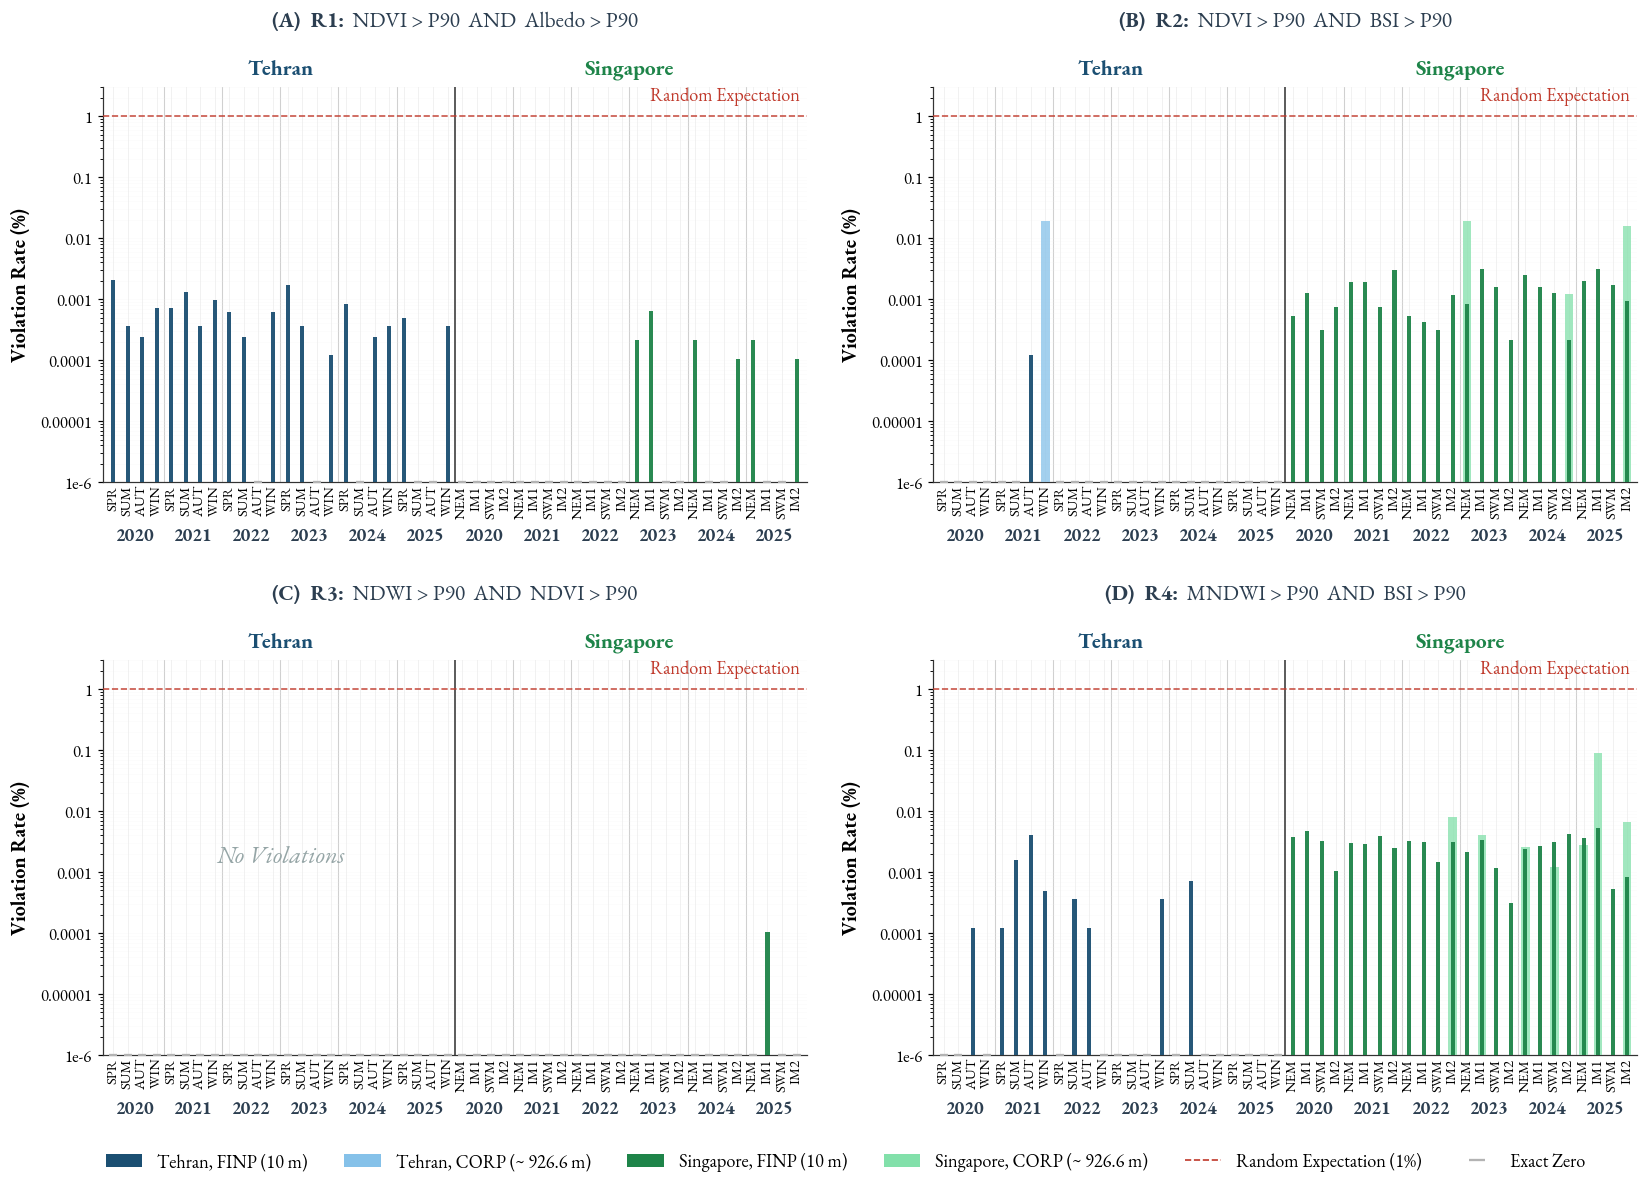

——————————————————————————————
Cross-Index Plausibility Audit
——————————————————————————————
  CSV Rows                       : 96
  Total Rule Values              : 384
  Cities                         : ['Singapore', 'Tehran']
  Tiers                          : ['CORP', 'FINP']
  Global Max Violation Rate      : 0.090581 %
  Global Exact Zeros             : 289 / 384

(A)  R1: NDVI > P90  AND  Albedo > P90

    Tehran     FINP  Min = 0.000121%  Median = 0.000363%  Max = 0.002058%  Zeros = 5/24
    Tehran     CORP  Min = 0.000000%  Median = 0.000000%  Max = 0.000000%  Zeros = 24/24
    Singapore  FINP  Min = 0.000105%  Median = 0.000000%  Max = 0.000631%  Zeros = 18/24
    Singapore  CORP  Min = 0.000000%  Median = 0.000000%  Max = 0.000000%  Zeros = 24/24

(B)  R2: NDVI > P90  AND  BSI > P90

    Tehran     FINP  Min = 0.000121%  Median = 0.000000%  Max = 0.000121%  Zeros = 23/24
    Tehran     CORP  Min = 0.019241%  Median = 0.000000%  Max = 0.019241%  Zeros = 23/24
    Singapore  F

In [8]:
# ——————————————————————————————————————
# [§5] Cross-Index Physical Plausibility
# ——————————————————————————————————————

if PlausibilityDF is not None:

    Rules = [

        ('A' , 'R1' , 'NDVIHighAlbedoHighFrac' , '  NDVI > P90  AND  Albedo > P90') ,

        ('B' , 'R2' , 'NDVIHighBSIHighFrac'    , '  NDVI > P90  AND  BSI > P90')    ,

        ('C' , 'R3' , 'NDWIHighNDVIHighFrac'   , '  NDWI > P90  AND  NDVI > P90')   ,

        ('D' , 'R4' , 'MNDWIHighBSIHighFrac'   , '  MNDWI > P90  AND  BSI > P90')

    ]

    ColourFINPTehran    = '#1b4f72'

    ColourCORPTehran    = '#85c1e9'

    ColourFINPSingapore = '#1e8449'

    ColourCORPSingapore = '#82e0aa'

    YMin                = 1e-6

    YFloor              = 3e-7

    Fig, Axes           = plt.subplots(2, 2, figsize=(18, 11))

    AxesFlat            = Axes.flatten()

    for K, (Letter, RuleNum, Column, RuleRest) in enumerate(Rules):

        Ax = AxesFlat[K]

        if Column not in PlausibilityDF.columns:

            Ax.axis('off')

            continue

        Ax.grid(axis='y', alpha=0.22, linewidth=0.5, zorder=0, which='both')

        for I in range(1, len(Years)):

            XDiv = I * 4 - 0.5

            Ax.axvline(XDiv, color='#d0d0d0', linewidth=0.7, zorder=1)

            Ax.axvline(24 + XDiv, color='#d0d0d0', linewidth=0.7, zorder=1)

        Ax.axvline(23.5, color='#404040', linewidth=1.1, zorder=2)

        CityZero = {'Tehran': True, 'Singapore': True}

        for City in Cities:

            XBase      = 0 if City == 'Tehran' else 24

            ColourFINP = ColourFINPTehran if City == 'Tehran' else ColourFINPSingapore

            ColourCORP = ColourCORPTehran if City == 'Tehran' else ColourCORPSingapore

            SubCORP    = PlausibilityDF[(PlausibilityDF['City'] == City) & (PlausibilityDF['Source'] == 'CORP')].copy()

            SubFINP    = PlausibilityDF[(PlausibilityDF['City'] == City) & (PlausibilityDF['Source'] == 'FINP')].copy()

            SubCORP    = SubCORP.set_index('Season_Year').reindex([ f'{S}-{Y}' for Y in Years for S in SeasonOrder[City] ])

            SubFINP    = SubFINP.set_index('Season_Year').reindex([ f'{S}-{Y}' for Y in Years for S in SeasonOrder[City] ])

            YCORP      = SubCORP[Column].values * 100

            YFINP      = SubFINP[Column].values * 100

            for I in range(len(YCORP)):

                XPos     = XBase + I

                ValCORP  = YCORP[I]

                ValFINP  = YFINP[I]

                HasValue = False

                if ValCORP > 0:

                    Ax.bar(XPos, ValCORP - YFloor, bottom=YFloor, width=0.58, color=ColourCORP,

                           alpha = 0.75, edgecolor='none', zorder=3)

                    HasValue = True

                if ValFINP > 0:

                    Ax.bar(XPos, ValFINP - YFloor, bottom=YFloor, width=0.28, color=ColourFINP,

                           alpha = 0.95, edgecolor='none', zorder=4)

                    HasValue = True

                if HasValue:

                    CityZero[City] = False

                else:

                    Ax.scatter([ XPos ], [ YMin ], marker='_', s=24, linewidths=1.5,

                               color = '#b3b3b3', zorder=3)

        Ax.axhline(1.0, color='#c0392b', linestyle='--', linewidth=1.1, alpha=0.85, zorder=5)

        Ax.text(0.99, 1.5, 'Random Expectation', transform=Ax.get_yaxis_transform(),

                ha = 'right', va='bottom', fontsize=12, color='#c0392b', zorder=6)

        Ax.text(11.5, 1.02, 'Tehran', transform=Ax.get_xaxis_transform(), ha='center',

                va = 'bottom', fontsize=14, fontweight='bold', color=ColourFINPTehran)

        Ax.text(35.5, 1.02, 'Singapore', transform=Ax.get_xaxis_transform(), ha='center',

                va = 'bottom', fontsize=14, fontweight='bold', color=ColourFINPSingapore)

        BoldPrefix    = TextArea(f'({Letter})  {RuleNum}:', textprops=dict(fontsize=14, fontweight='bold', color='#2c3e50'))

        RegularSuffix = TextArea(RuleRest, textprops=dict(fontsize=14, color='#2c3e50'))

        TitleBox      = HPacker(children=[ BoldPrefix , RegularSuffix ], align='center', pad=0, sep=0)

        Anchored      = AnchoredOffsetbox(loc='lower center', child=TitleBox, frameon=False ,

                                      bbox_to_anchor = (0.5, 1.14), bbox_transform=Ax.transAxes ,

                                      borderpad      = 0, pad=0)

        Ax.add_artist(Anchored)

        for City, Cx in [ ('Tehran' , 11.5) , ('Singapore' , 35.5) ]:

            if CityZero[City]:

                Ax.text(Cx, 0.5, 'No Violations', transform=Ax.get_xaxis_transform(),

                        ha    = 'center', va='center', fontsize=16, color='#95a5a6' ,

                        style = 'italic', zorder=6)

        Ax.set_yscale('log')

        Ax.set_ylim(YMin, 3.0)

        Ax.set_yticks([ 1e-6 , 1e-5 , 1e-4 , 1e-3 , 1e-2 , 1e-1 , 1.0 ])

        Ax.set_yticklabels([ '1e-6' , '0.00001' , '0.0001' , '0.001' , '0.01' , '0.1' , '1' ], fontsize=11)

        Ax.set_ylabel('Violation Rate (%)', fontsize=13, labelpad=6, fontweight='bold')

        Ax.set_xlim(-0.7, 47.7)

        SeasonsAll = SeasonOrder['Tehran'] * len(Years) + SeasonOrder['Singapore'] * len(Years)

        Ax.set_xticks(np.arange(48))

        Ax.set_xticklabels(SeasonsAll, rotation=90, fontsize=9.5, ha='center', va='top')

        Ax.tick_params(axis='x', pad=2, length=0)

        for I, Year in enumerate(Years):

            Cx = I * 4 + 1.5

            Ax.text(Cx, -0.115, str(Year), transform=Ax.get_xaxis_transform(),

                    ha = 'center', va='top', fontsize=12, fontweight='bold', color='#2c3e50')

            Ax.text(24 + Cx, -0.115, str(Year), transform=Ax.get_xaxis_transform(),

                    ha = 'center', va='top', fontsize=12, fontweight='bold', color='#2c3e50')

    LegendElements = [

        Patch(facecolor=ColourFINPTehran, edgecolor='none', label='Tehran, FINP (10 m)'),

        Patch(facecolor=ColourCORPTehran, edgecolor='none', label='Tehran, CORP (~ 926.6 m)'),

        Patch(facecolor=ColourFINPSingapore, edgecolor='none', label='Singapore, FINP (10 m)'),

        Patch(facecolor=ColourCORPSingapore, edgecolor='none', label='Singapore, CORP (~ 926.6 m)'),

        Line2D([ 0 ], [ 0 ], color='#c0392b', linestyle='--', linewidth=1.1, label='Random Expectation (1%)'),

        Line2D([ 0 ], [ 0 ], marker='_', color='w', markerfacecolor='#b3b3b3',

               markeredgecolor = '#b3b3b3', markeredgewidth=1.5, markersize=10, label='Exact Zero'),

    ]

    Fig.legend(handles=LegendElements, loc='lower center', ncol=6, fontsize=12,

               frameon = False, bbox_to_anchor=(0.5, -0.01))

    plt.subplots_adjust(hspace=0.45, wspace=0.18, bottom=0.10, top=0.90)

    SaveFigure(Fig, 'Figure 5 Cross Index Plausibility')

    plt.show()

    # —————
    #  Audit
    # —————

    print('——————————————————————————————')
    print('Cross-Index Plausibility Audit')
    print('——————————————————————————————')

    TotalValues = PlausibilityDF[[ R[2] for R in Rules ]].size

    ZeroAll     = int((PlausibilityDF[[ R[2] for R in Rules ]] == 0).sum().sum())

    MaxAll      = PlausibilityDF[[ R[2] for R in Rules ]].max().max() * 100

    print(f'  CSV Rows                       : {len(PlausibilityDF)}')

    print(f'  Total Rule Values              : {TotalValues}')

    print(f'  Cities                         : {sorted(PlausibilityDF.City.unique().tolist())}')

    print(f'  Tiers                          : {sorted(PlausibilityDF.Source.unique().tolist())}')

    print(f'  Global Max Violation Rate      : {MaxAll:.6f} %')

    print(f'  Global Exact Zeros             : {ZeroAll} / {TotalValues}')

    print()

    for Letter, RuleNum, Column, RuleRest in Rules:

        print(f'({Letter})  {RuleNum}: {RuleRest.strip()}''\n')

        for City in Cities:

            for Tier in [ 'FINP' , 'CORP' ]:

                S          = PlausibilityDF[(PlausibilityDF.City == City) & (PlausibilityDF.Source == Tier)][Column] * 100

                NonZero    = S[S > 0]

                MinNonZero = NonZero.min() if len(NonZero) else 0.0

                print(f'    {City:10s} {Tier:4s}  Min = {MinNonZero:.6f}%  Median = {S.median():.6f}%  '

                      f'Max = {S.max():.6f}%  Zeros = {int((S == 0).sum())}/24')

        print()

---

#### **[§6]  NTL Plausibility & Backward-Aggregation**

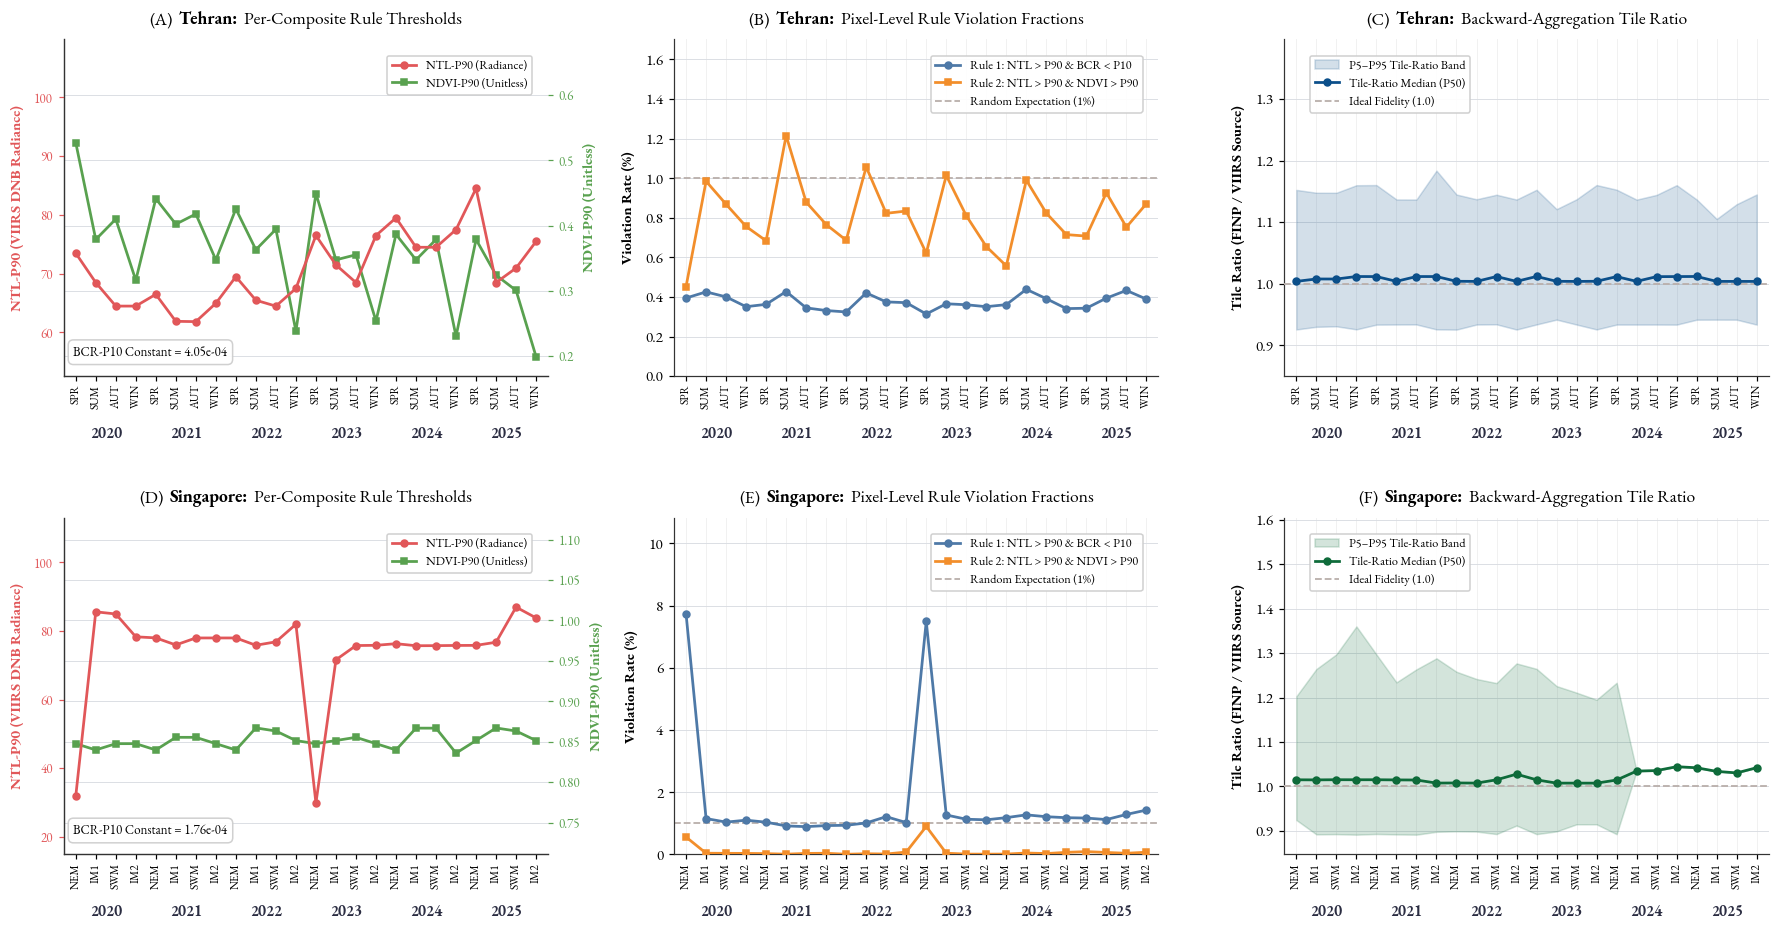


——————————————————————
NTL Plausibility Audit
——————————————————————

Tehran:

  Rule 1 Range     : 0.31–0.44%

  Rule 2 Range     : 0.453–1.215%

  TileRatio P50    : 1.006 (Median of 24)

  Collapsed rows   : 0 (P5 = P50 = P95)


Singapore:

  Rule 1 Range     : 0.89–7.73%

  Rule 2 Range     : 0.007–0.901%

  TileRatio P50    : 1.015 (Median of 24)

  Collapsed rows   : 7 (P5 = P50 = P95)


Tehran:

Season_Year   City  NTL_P90     BCR_P10  NDVI_P90  Frac_NTLhigh_BCRlow  Frac_NTLhigh_NDVIhigh  NTL_TileRatio_P5  NTL_TileRatio_P50  NTL_TileRatio_P95 SeasonYear  NTLP90      BCRP10  NDVIP90  FracNTLhighBCRlow  FracNTLhighNDVIhigh  NTLTileRatioP5  NTLTileRatioP50  NTLTileRatioP95
   SPR-2020 Tehran  73.4886 0.000404921  0.527349           0.00394827             0.00452829          0.925828            1.00386            1.15226   SPR-2020 73.4886 0.000404921 0.527349         0.00394827           0.00452829        0.925828          1.00386          1.15226
   SUM-2020 Tehran  68.4923 0.000

In [9]:
# ————————————————————————————————————————————
# [§6] NTL Plausibility & Backward-Aggregation
# ————————————————————————————————————————————

if NTLDF is not None:

    Fig, Axes    = plt.subplots( 2 , 3 , figsize = ( 20 , 9.5 ) , gridspec_kw = { 'wspace' : 0.26 , 'hspace' : 0.42 } )

    PanelLetters = [ [ '(A)' , '(B)' , '(C)' ] , [ '(D)' , '(E)' , '(F)' ] ]

    MetricTitles = [

        'Per-Composite Rule Thresholds'              ,

        'Pixel-Level Rule Violation Fractions'       ,

        'Backward-Aggregation Tile Ratio'

    ]

    def PanelTitle(Ax, Row, Col, City):

        Box = AnchoredOffsetbox( loc = 'lower center',

                                child = HPacker( children = [ TextArea( PanelLetters[Row][Col] , textprops = dict( fontsize = 11.5 , fontweight = 'normal' ) ) ,

                                TextArea( f'{City}:' , textprops = dict( fontsize = 11.5 , fontweight = 'bold' ) ) ,

                                TextArea( MetricTitles[Col] , textprops = dict( fontsize = 11.5 , fontweight = 'normal' ) )] ,

                                align = 'baseline' , pad = 0 , sep = 4 ) ,

                                pad = 0 , borderpad = 0.6 , frameon = False ,

                                bbox_to_anchor = ( 0.5 , 1.0 ) , bbox_transform = Ax.transAxes , prop = dict( size = 11.5 ))

        Ax.add_artist(Box)

        Box.set_clip_on(False)

    for Row, City in enumerate(Cities):

        Sub     = OrderedFrame( NTLDF , City )

        X       = np.arange(len(Sub))

        Colour  = CityPalette[City]

        Ax      = Axes[Row, 0]

        AxRight = Ax.twinx()

        AxRight.grid( axis = 'y' , color = '#d9dde2' , linewidth = 0.6 )

        AxRight.set_axisbelow(True)

        Ax.grid(False)

        Ax.set_zorder(AxRight.get_zorder() + 1)

        Ax.patch.set_visible(False)

        Ax.plot( X , Sub['NTLP90'] , 'o-' , color = '#E15759' , linewidth = 1.8 , markersize = 4.5 , label = 'NTL-P90 (Radiance)' , zorder = 4 )

        Ax.set_ylabel( 'NTL-P90 (VIIRS DNB Radiance)' , fontsize = 9.5 , labelpad = 6 , color = '#E15759' , fontweight = 'bold' )

        Ax.tick_params( axis = 'y' , colors = '#E15759' , labelsize = 8.5 )

        AxRight.plot( X , Sub['NDVIP90'] , 's-' , color = '#59A14F' , linewidth = 1.8 , markersize = 4.5 , label = 'NDVI-P90 (Unitless)' , zorder = 4 )

        AxRight.set_ylabel( 'NDVI-P90 (Unitless)' , fontsize = 9.5 , labelpad = 6 , color = '#59A14F' , fontweight = 'bold' )

        AxRight.tick_params( axis = 'y' , colors = '#59A14F' , labelsize = 8.5 )

        BcrConst = Sub['BCRP10'].iloc[0]

        Ax.text( 0.02 , 0.05 , f'BCR-P10 Constant = {BcrConst:.2e}' , transform = Ax.transAxes , fontsize = 8.5 , ha = 'left' , va = 'bottom' , bbox = dict( boxstyle = 'round,pad=0.4' , facecolor = 'white' , edgecolor = '#cccccc' , alpha = 0.92 ) )

        PanelTitle(Ax, Row, 0, City)

        NtlMax = Sub['NTLP90'].max()

        NtlMin = Sub['NTLP90'].min()

        if Row == 1:

            Ax.set_ylim( NtlMin - 15 , NtlMax * 1.30 )

        else:
            
            Ax.set_ylim( NtlMin * 0.85 , NtlMax * 1.30 )

        NdviMax = Sub['NDVIP90'].max()

        NdviMin = Sub['NDVIP90'].min()

        AxRight.set_ylim( NdviMin * 0.85 , NdviMax * 1.30 )

        H1, L1 = Ax.get_legend_handles_labels()

        H2, L2 = AxRight.get_legend_handles_labels()

        StyledLegend( Ax , H1 + H2 , L1 + L2 , fontsize = 8 , loc = 'upper right' , bbox_to_anchor = ( 0.98 , 0.97 ) )

        Ax = Axes[Row, 1]

        Ax.plot( X , Sub['FracNTLhighBCRlow'] * 100 , 'o-' , color = '#4E79A7' , linewidth = 1.8 , markersize = 4.5 , label = 'Rule 1: NTL > P90 & BCR < P10' , zorder = 4 )

        Ax.plot( X , Sub['FracNTLhighNDVIhigh'] * 100 , 's-' , color = '#F28E2B' , linewidth = 1.8 , markersize = 4.5 , label = 'Rule 2: NTL > P90 & NDVI > P90' , zorder = 4 )

        Ax.axhline( 1.0 , color = '#BAB0AC' , linestyle = '--' , linewidth = 1.2 , label = 'Random Expectation (1%)' , zorder = 2 )

        Ax.set_ylabel( 'Violation Rate (%)' , fontsize = 9.5 , labelpad = 6 , fontweight = 'bold' )

        PanelTitle(Ax, Row, 1, City)

        Ax.grid( axis = 'y' , color = '#d9dde2' , linewidth = 0.6 )

        Ax.set_axisbelow(True)

        MaxV = max( (Sub['FracNTLhighBCRlow'] * 100).max() , (Sub['FracNTLhighNDVIhigh'] * 100).max() )

        Ax.set_ylim( 0 , MaxV * 1.40 )

        StyledLegend( Ax , fontsize = 8 , loc = 'upper right' , bbox_to_anchor = ( 0.98 , 0.97 ) )

        Ax = Axes[Row, 2]

        Ax.fill_between( X , Sub['NTLTileRatioP5'] , Sub['NTLTileRatioP95'] , color = Colour , alpha = 0.18 , zorder = 2 , label = 'P5–P95 Tile-Ratio Band' )

        Ax.plot( X , Sub['NTLTileRatioP50'] , 'o-' , color = Colour , linewidth = 1.8 , markersize = 4.5 , label = 'Tile-Ratio Median (P50)' , zorder = 4 )

        Ax.axhline( 1.0 , color = '#BAB0AC' , linestyle = '--' , linewidth = 1.2 , label = 'Ideal Fidelity (1.0)' , zorder = 3 )

        Ax.set_ylabel( 'Tile Ratio (FINP / VIIRS Source)' , fontsize = 9.5 , labelpad = 6 , fontweight = 'bold' )

        PanelTitle(Ax, Row, 2, City)

        Ax.grid( axis = 'y' , color = '#d9dde2' , linewidth = 0.6 )

        Ax.set_axisbelow(True)

        P95Max = Sub['NTLTileRatioP95'].max()

        P5Min  = Sub['NTLTileRatioP5'].min()

        Ax.set_ylim( min( 0.85 , P5Min * 0.95 ) , max( 1.20 , P95Max * 1.18 ) )

        StyledLegend( Ax , fontsize = 8 , loc = 'upper left' , bbox_to_anchor = ( 0.04 , 0.97 ) )

        for ColIdx in range(3):

            AddTwoLevelAxis( Axes[Row, ColIdx] , Sub , YearY = -0.15 )

            for T in Axes[Row, ColIdx].texts:

                if abs(T.get_position()[1] + 0.15) < 1e-9:

                    T.set_fontsize(T.get_fontsize() + 2.0)

    plt.tight_layout()

    Fig.subplots_adjust( bottom = 0.10 , hspace = 0.42 , wspace = 0.26 )

    SaveFigure( Fig , 'Figure 6 NTL Plausibility' )

    plt.show()

    # —————
    # Audit
    # —————

    print('\n——————————————————————')
    print('NTL Plausibility Audit')
    print('——————————————————————')

    for City in Cities:

        S         = NTLDF[NTLDF['City'] == City]

        Collapsed = int(((S['NTLTileRatioP5'] == S['NTLTileRatioP50']) &

                         (S['NTLTileRatioP50'] == S['NTLTileRatioP95'])).sum())

        print(f'\n{City}:\n')

        print(f'  Rule 1 Range     : {S.FracNTLhighBCRlow.min()*100:.2f}–{S.FracNTLhighBCRlow.max()*100:.2f}%\n')

        print(f'  Rule 2 Range     : {S.FracNTLhighNDVIhigh.min()*100:.3f}–{S.FracNTLhighNDVIhigh.max()*100:.3f}%\n')

        print(f'  TileRatio P50    : {S.NTLTileRatioP50.median():.3f} (Median of 24)\n')

        print(f'  Collapsed rows   : {Collapsed} (P5 = P50 = P95)\n')

    for City in Cities:

        print(f'\n{City}:\n')

        print(OrderedFrame( NTLDF , City ).to_string( index = False , float_format = General6 ) + '\n')

---

#### **[§7] Topographic Distribution**

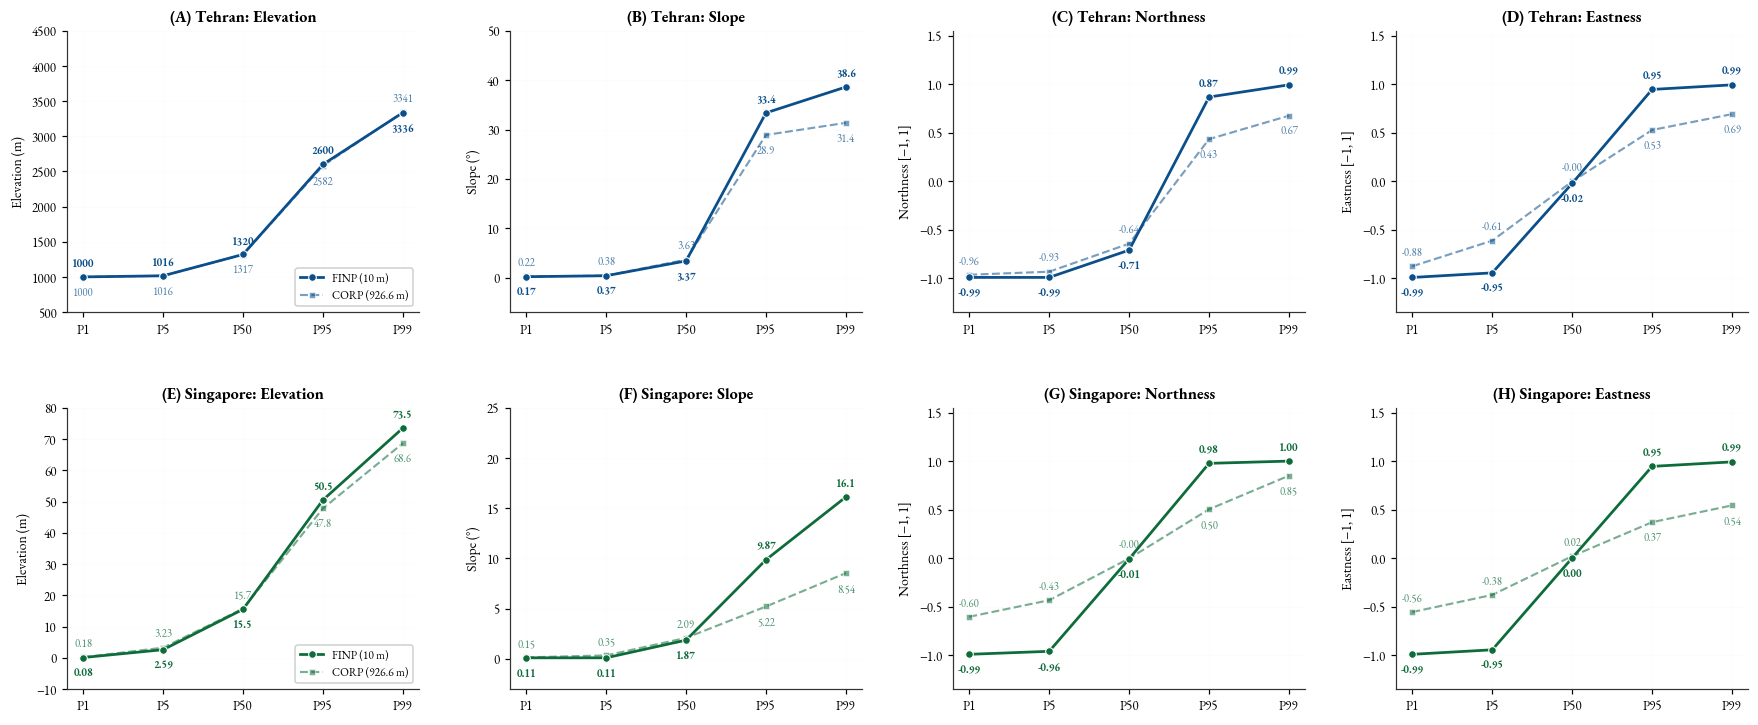

——————————————————————————————
Topographic Distribution Audit
——————————————————————————————

[1] Topographic Percentile Distributions Per (City, Tier, Variable)

     City Tier           Variable    P1    P5   P50   P95   P99
   Tehran FINP      Elevation (m)  1000  1016  1320  2600  3336
   Tehran FINP          Slope (°)  0.17  0.37  3.37 33.37 38.62
   Tehran FINP Northness (−1 … 1) -0.99 -0.99 -0.71  0.87  0.99
   Tehran FINP  Eastness (−1 … 1) -0.99 -0.95 -0.02  0.95  0.99
   Tehran CORP      Elevation (m)  1000  1016  1317  2582  3341
   Tehran CORP          Slope (°)  0.22  0.38  3.63 28.89 31.35
   Tehran CORP Northness (−1 … 1) -0.96 -0.93 -0.64  0.43  0.67
   Tehran CORP  Eastness (−1 … 1) -0.88 -0.61 -0.00  0.53  0.69
Singapore FINP      Elevation (m)     0     3    15    50    73
Singapore FINP          Slope (°)  0.11  0.11  1.87  9.87 16.12
Singapore FINP Northness (−1 … 1) -0.99 -0.96 -0.01  0.98  1.00
Singapore FINP  Eastness (−1 … 1) -0.99 -0.95  0.00  0.95  0.99
Singa

In [10]:
# —————————————————————————————
# [§7] Topographic Distribution
# —————————————————————————————

if TopoDF is not None:

    Variables = [ 

        ( 'Elevation' , [ 'ElevP1' , 'ElevP5' , 'ElevP50' , 'ElevP95' , 'ElevP99' ]      , 'Elevation (m)'     , ( 500 , 4500 )   , ( -10 , 80 ) )     ,

        ( 'Slope'     , [ 'SlopeP1' , 'SlopeP5' , 'SlopeP50' , 'SlopeP95' , 'SlopeP99' ] , 'Slope (°)'         , ( -7 , 50 )      , ( -3 , 25 ) )      ,

        ( 'Northness' , [ 'NorthP1' , 'NorthP5' , 'NorthP50' , 'NorthP95' , 'NorthP99' ] , 'Northness [−1, 1]' , ( -1.35 , 1.55 ) , ( -1.35 , 1.55 ) ) ,

        ( 'Eastness'  , [ 'EastP1' , 'EastP5' , 'EastP50' , 'EastP95' , 'EastP99' ]      , 'Eastness [−1, 1]'  , ( -1.35 , 1.55 ) , ( -1.35 , 1.55 ) ) ,

    ]

    PercentileNames = [ 'P1' , 'P5' , 'P50' , 'P95' , 'P99' ]

    def FormatValue(V):

        if abs(V) < 10:

            return f'{V:.2f}'

        if abs(V) < 100:

            return f'{V:.1f}'

        return f'{V:.0f}'

    Fig, Axes = plt.subplots( 2 , 4 , figsize = ( 16 , 6.8 ) )

    for Row, City in enumerate(Cities):

        Colour = CityPalette[City]

        for Col, ( VarName , Columns , YLabel , YlimTehran , YlimSingapore ) in enumerate(Variables):

            Ax    = Axes[Row, Col]

            FINP  = TopoDF[(TopoDF.City == City) & (TopoDF.Source == 'FINP')]

            CORP  = TopoDF[(TopoDF.City == City) & (TopoDF.Source == 'CORP')]

            X     = np.arange(len(PercentileNames))

            if len(FINP) > 1: print(f'  [§7 Warn] {City}/FINP Has {len(FINP)} Rows, Using First')

            if len(CORP) > 1: print(f'  [§7 Warn] {City}/CORP Has {len(CORP)} Rows, Using First')

            YFINP = [ FINP.iloc[0][C] for C in Columns ] if len(FINP) else None

            YCORP = [ CORP.iloc[0][C] for C in Columns ] if len(CORP) else None

            if YFINP is not None:

                Ax.plot( X , YFINP , 'o-' , color = Colour , linewidth = 1.8 , markersize = 5 , markeredgecolor = 'white' , markeredgewidth = 0.7 , label = 'FINP (10 m)' , zorder = 4 )

                for I, ( Xi , Yi ) in enumerate(zip( X , YFINP )):

                    Above = True if YCORP is None else (Yi > YCORP[I])

                    Ax.annotate( FormatValue(Yi) , ( Xi , Yi ) , xytext = ( 0 , 7 if Above else -12 ) , textcoords = 'offset points' , ha = 'center' , fontsize = 7 , color = Colour , fontweight = 'bold' )

            if YCORP is not None:

                Ax.plot( X , YCORP , 's--' , color = Colour , alpha = 0.55 , linewidth = 1.4 , markersize = 4.5 , markeredgecolor = 'white' , markeredgewidth = 0.7 , label = 'CORP (926.6 m)' , zorder = 3 )

                for I, ( Xi , Yi ) in enumerate(zip( X , YCORP )):

                    Above = False if YFINP is None else (Yi >= YFINP[I])

                    Ax.annotate( FormatValue(Yi) , ( Xi , Yi ) , xytext = ( 0 , 7 if Above else -12 ) , textcoords = 'offset points' , ha = 'center' , fontsize = 7 , color = Colour , alpha = 0.75 )

            Ax.set_xticks(X)

            Ax.set_xticklabels( PercentileNames , fontsize = 8.5 )

            Ax.set_ylabel( YLabel , fontsize = 9 )

            Ax.tick_params( axis = 'y' , labelsize = 8.5 )

            Ax.set_ylim(YlimTehran if City == 'Tehran' else YlimSingapore)

            Ax.grid( alpha = 0.15 )

            Panel = chr(ord('A') + Row * 4 + Col)

            Ax.set_title( f'({Panel}) {City}: {VarName}' , fontsize = 10.5 , fontweight = 'bold' , pad = 6 )

            if Col == 0:

                Ax.legend( fontsize = 7.5 , loc = 'lower right' , framealpha = 0.92 , edgecolor = '#cccccc' )

    Fig.subplots_adjust( left = 0.04 , right = 0.995 , top = 0.95 , bottom = 0.07 , hspace = 0.34 , wspace = 0.26 )

    SaveFigure( Fig , 'Figure 7 Topographic Distribution' )

    plt.show()

    # —————
    # Audit
    # —————

    VariablesLong = [ 

        ( 'Elevation (m)' , 'ElevP1' , 'ElevP5' , 'ElevP50' , 'ElevP95' , 'ElevP99' )           ,

        ( 'Slope (°)' , 'SlopeP1' , 'SlopeP5' , 'SlopeP50' , 'SlopeP95' , 'SlopeP99' )          ,

        ( 'Northness (−1 … 1)' , 'NorthP1' , 'NorthP5' , 'NorthP50' , 'NorthP95' , 'NorthP99' ) ,

        ( 'Eastness (−1 … 1)' , 'EastP1' , 'EastP5' , 'EastP50' , 'EastP95' , 'EastP99' )

    ]

    TidyRows = []

    for Index, R in TopoDF[TopoDF.Source.isin([ 'FINP' , 'CORP' ])].iterrows():

        for VarLabel, C1, C5, C50, C95, C99 in VariablesLong:

            TidyRows.append({ 'City' : R['City'] , 'Tier': R['Source'] , 'Variable': VarLabel , 'P1'   : R[C1] , 'P5': R[C5] , 'P50': R[C50] , 'P95': R[C95] , 'P99': R[C99] })

    Tidy = pd.DataFrame(TidyRows)

    def FormatRow(Row):

        IsElevation = 'Elevation' in Row['Variable']

        def F(V):

            if pd.isna(V):

                return ''

            return f'{V:.0f}' if IsElevation else f'{V:.2f}'

        return pd.Series({

            'City' : Row['City'] , 'Tier': Row['Tier'] , 'Variable': Row['Variable'] ,

            'P1'   : F(Row['P1']), 'P5': F(Row['P5']), 'P50': F(Row['P50'])          ,

            'P95'  : F(Row['P95']), 'P99': F(Row['P99'])

        })

    TidyFormatted = Tidy.apply( FormatRow , axis = 1 )

    print('——————————————————————————————')
    print('Topographic Distribution Audit')
    print('——————————————————————————————')

    print('\n[1] Topographic Percentile Distributions Per (City, Tier, Variable)\n')

    print(TidyFormatted.to_string( index = False ) + '\n')

    Diff            = TopoDF[TopoDF.Source == 'FINP-vs-CORP'].copy()

    DiffOut         = Diff[[ 'City' , 'ElevDiffMean' , 'ElevDiffSD' , 'ElevDiffP5' , 'ElevDiffP95' ]].copy()

    DiffOut.columns = [ 'City' , 'ΔElev mean (m)' , 'ΔElev SD (m)' , 'ΔElev P5 (m)' , 'ΔElev P95 (m)' ]

    for C in DiffOut.columns[1:]:

        DiffOut[C] = DiffOut[C].apply(lambda V: f'{V:+.2f}')

    print('\n[2] FINP vs. CORP Elevation Agreement\n')

    print(DiffOut.to_string( index = False ) + '\n')

    TidyFormatted.to_csv( TableDir / 'Table 3A Topographic Distribution.csv' , index = False )

    DiffOut.to_csv( TableDir / 'Table 3B Cross Tier Elevation Agreement.csv' , index = False )

    print(f'\n  Saved: {TableDir / "Table 3A Topographic Distribution.csv"}\n')

    print(f'  Saved: {TableDir / "Table 3B Cross Tier Elevation Agreement.csv"}\n')

---

#### **[§8] Validation Summary Tables**

In [11]:
# ————————————————————————————
# [Table 1] Validation Summary
# ————————————————————————————

SummaryRows = []

if CoverageDF is not None:

    SummaryRows.append({

        'ValidationAxis' : 'Composite Completeness (S2/S1)' ,

        'NChecked'       : f'{len(CoverageDF)} Composites'  ,

        'Result'         : (f'Mean Valid-Pixel Coverage: '

                            f'Tehran {CoverageDF[CoverageDF.City=="Tehran"].FINPValidFrac.mean()*100:.2f}%, '

                            f'Singapore {CoverageDF[CoverageDF.City=="Singapore"].FINPValidFrac.mean()*100:.2f}%'),

    })

if ENLDF is not None:

    SummaryRows.append({

        'ValidationAxis' : 'SAR Speckle Suppression (ENL)' ,

        'NChecked'       : f'{len(ENLDF)} Composites'      ,

        'Result'         : (f'Raw ENL {ENLDF.ENLRaw.min():.2f}–{ENLDF.ENLRaw.max():.2f}; '

                            f'Composite Effective Looks up to {ENLDF.EffectiveLooks.max():.1f}×'),

    })

Range = RangeDF.assign( CoreOk = CoreCompliance(RangeDF) )

SummaryRows.append({

    'ValidationAxis' : 'Physical Range Compliance'                                            ,

    'NChecked'       : f'{len(Range)} Band x City x Season Checks'                            ,

    'Result'         : f'{Range.CoreOk.mean()*100:.1f}% within Literature/Theoretical Bounds'

})

if 'PooledDF' in globals() and PooledDF is not None and len(PooledDF) > 0:

    FINPRate = 100.0 * (PooledDF.loc[PooledDF.Source == 'FINP', 'NormDelta'].abs() > Threshold).mean()

    CORPRate = 100.0 * (PooledDF.loc[PooledDF.Source == 'CORP', 'NormDelta'].abs() > Threshold).mean()

    SummaryRows.append({

        'ValidationAxis' : 'Interannual Temporal Consistency - FINP'     ,

        'NChecked'       : f'{(PooledDF.Source=="FINP").sum():,} Deltas' ,

        'Result'         : f'Anomaly Rate {FINPRate:.2f}%'

    })

    SummaryRows.append({

        'ValidationAxis' : 'Interannual Temporal Consistency - CORP'     ,

        'NChecked'       : f'{(PooledDF.Source=="CORP").sum():,} Deltas' ,

        'Result'         : f'Anomaly Rate {CORPRate:.2f}%'

    })

else:

    print('  [§8] Temporal rows skipped — run §4 first for these.')

    SummaryRows.append({

        'ValidationAxis' : 'Interannual Temporal Consistency - FINP' ,

        'NChecked'       : 'not run'                                 ,

        'Result'         : 'SKIPPED (§4 not executed)'

    })

    SummaryRows.append({

        'ValidationAxis' : 'Interannual Temporal Consistency - CORP' ,

        'NChecked'       : 'not run'                                 ,

        'Result'         : 'SKIPPED (§4 not executed)'

    })

if PlausibilityDF is not None:

    RuleColumns = [ C for C in (

        'NDVIHighAlbedoHighFrac' ,

        'NDVIHighBSIHighFrac'    ,

        'NDWIHighNDVIHighFrac'   ,

        'MNDWIHighBSIHighFrac'

) if C in PlausibilityDF.columns]

    if RuleColumns:

        SummaryRows.append({

            'ValidationAxis' : 'Cross-Index Physical Plausibility'                                      ,

            'NChecked'       : f'{len(PlausibilityDF)} Composite x Tier Combinations'                   ,

            'Result'         : f'Max Violation Rate {PlausibilityDF[RuleColumns].max().max()*100:.3f}%'

        })

    else:

        SummaryRows.append({

            'ValidationAxis' : 'Cross-Index Physical Plausibility' ,

            'NChecked'       : f'{len(PlausibilityDF)} rows'       ,

            'Result'         : 'SKIPPED (Rule Columns Missing)'

        })

if NTLDF is not None:

    MaxViol = max( NTLDF.FracNTLhighBCRlow.max() , NTLDF.FracNTLhighNDVIhigh.max() ) * 100

    SummaryRows.append({

        'ValidationAxis' : 'NTL Spatial Plausibility & Regrid Accuracy' ,

        'NChecked'       : f'{len(NTLDF)} Composites'                   ,

        'Result'         : (f'Median Tile Ratio {NTLDF.NTLTileRatioP50.median():.3f}; '

                            f'Max Rule Violation {MaxViol:.2f}%'),

    })

if PopDF is not None:

    SummaryRows.append({

        'ValidationAxis' : 'Population Density Mass Conservation' ,

        'NChecked'       : f'{len(PopDF)} City-Years'             ,

        'Result'         : (f'{PopDF.RMassVsMass.min()*100:.2f}–'

                   f'{PopDF.RMassVsMass.max()*100:.2f}% Mass Preserved'),

    })

if TopoDF is not None:

    DiffRows = TopoDF[TopoDF['Source'] == 'FINP-vs-CORP']

    if len(DiffRows):

        SummaryRows.append({

            'ValidationAxis' : 'Topographic Cross-Tier Consistency' ,

            'NChecked'       : f'{len(TopoDF)} Distribution Checks' ,

            'Result'         : (f'FINP-vs-CORP Elevation Mean Diff '

                       f'{DiffRows.ElevDiffMean.abs().max():.2f} m or Less'),

        })

if GridDF is not None:

    NTotal   = len(GridDF)

    NAligned = int((GridDF['Aligned'] == 'YES').sum())

    SummaryRows.append({

        'ValidationAxis' : 'Grid Co-Registration'                     ,

        'NChecked'       : f'{NTotal} Composite x Tier Checks'        ,

        'Result'         : f'{NAligned}/{NTotal} Aligned'

    })

Table1 = pd.DataFrame(SummaryRows)

print('\n————————————————————————————')
print('[Table 1] Validation Summary')
print('————————————————————————————\n')

Header, *Rows = Table1.to_string( index = False ).split('\n')

print(Header + '\n')

for R in Rows:

    print(R + '\n')

Table1.to_csv( TableDir / 'Table 1 Validation Summary.csv' , index = False )

# ——————————————————————————————————————————————
# [Table 2] Population Density Mass Conservation
# ——————————————————————————————————————————————

if PopDF is not None:

    Table2                   = PopDF[[ 'City' , 'Year' , 'RMassVsMass' , 'RRawVsSrcCount' ]].copy()

    Table2['RMassVsMass']    = (Table2['RMassVsMass'] * 100).round(3)

    Table2['RRawVsSrcCount'] = Table2['RRawVsSrcCount'].round(1)

    Table2.columns           = [ 'City' , 'Year' , 'MassPreservedPct' , 'RawToSourceRatio' ]

    print('\n——————————————————————————————————————————————')
    print('[Table 2] Population Density Mass Conservation')
    print('——————————————————————————————————————————————\n')

    Header, *Rows = Table2.to_string( index = False ).split('\n')

    print(Header + '\n')

    for R in Rows:

        print(R + '\n')

    Table2.to_csv( TableDir / 'Table 2 Population Mass Conservation.csv' , index = False )

    print()

print(f'Figures Saved In: {FigureDir}\n')

print(f'Tables Saved in:  {TableDir}')


————————————————————————————
[Table 1] Validation Summary
————————————————————————————

                            ValidationAxis                         NChecked                                                     Result

            Composite Completeness (S2/S1)                    48 Composites Mean Valid-Pixel Coverage: Tehran 99.75%, Singapore 98.52%

             SAR Speckle Suppression (ENL)                    48 Composites   Raw ENL 2.70–6.81; Composite Effective Looks up to 17.3×

                 Physical Range Compliance 2592 Band x City x Season Checks                100.0% within Literature/Theoretical Bounds

   Interannual Temporal Consistency - FINP                   401,220 Deltas                                         Anomaly Rate 6.94%

   Interannual Temporal Consistency - CORP                   401,220 Deltas                                         Anomaly Rate 5.07%

         Cross-Index Physical Plausibility 96 Composite x Tier Combinations                    

---

#### **[§9] Gap-Fill Validation (3D)**

—————————————————————————————
Fill Budget (% of Built Area)
—————————————————————————————

           Original  FootprintFilled  WSFGap  TotalFilled

City                                                     

Singapore     77.42            22.58    0.00        22.58

Tehran        96.34             0.98    2.68         3.66

———————————————————————————————————————————————————————————————————
Validation: 100 m Mean-Height Layer vs Complete GBA-Based Reference
———————————————————————————————————————————————————————————————————

     City  Scenario                       Method    R2  R2Lo  R2Hi  RMSEM  BiasM  RMSEInFilledCellsM

Singapore Scattered            Naive (City Mean) 0.844 0.821 0.862  1.961 -0.230               2.163

Singapore Scattered          Original (Raw NDSM) 0.860 0.843 0.874  1.856 -0.302               2.047

Singapore Scattered  This Study (Neighbour Fill) 0.932 0.922 0.940  1.292  0.083               1.424

Singapore Scattered Fitted Line (Reference Only) 0.892 0.873

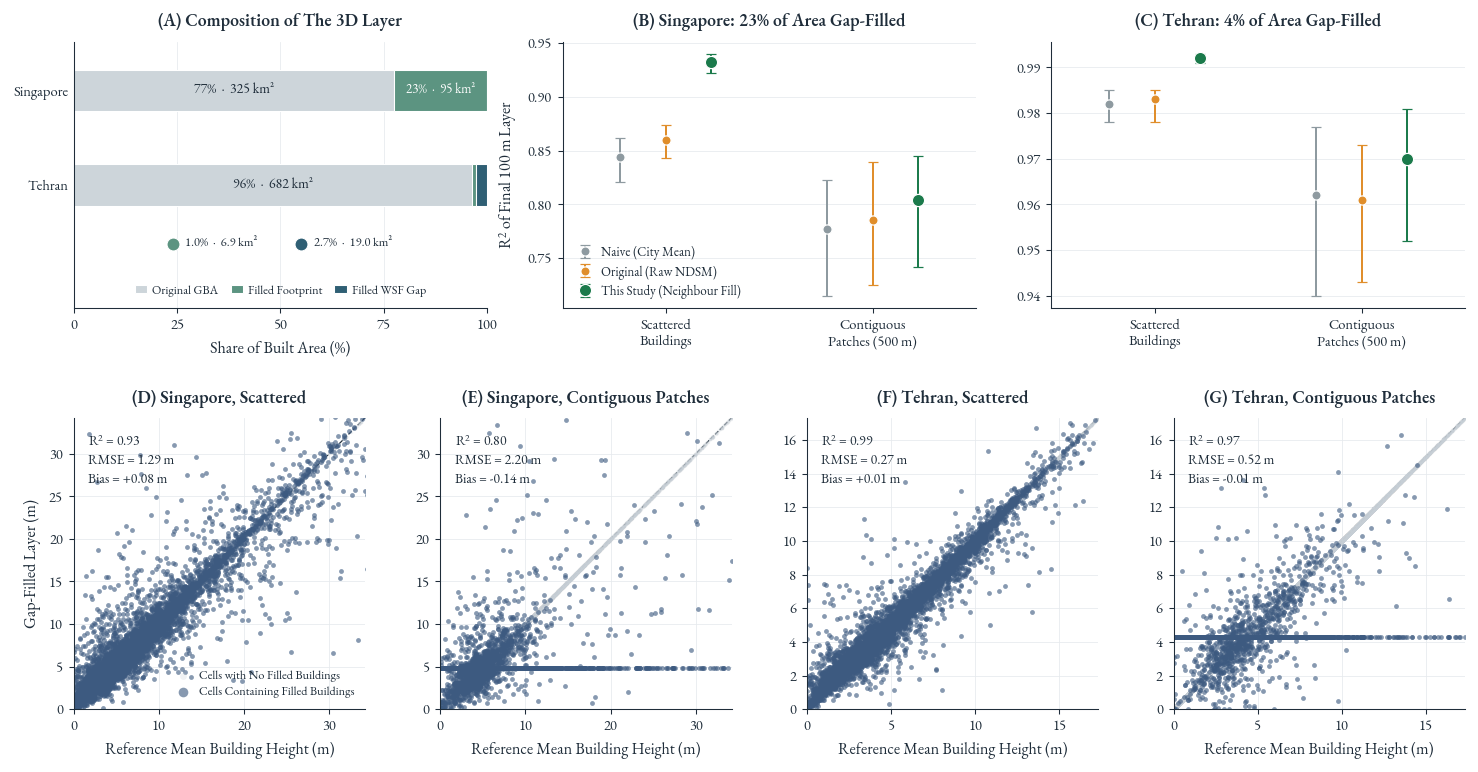

In [12]:
# ————————————————————————
# [§9] Gap-Fill Validation
# ————————————————————————

CellSize     = 0.001

MinBuildings = 3

Reps         = 30

Scens        = [ 'Scattered' , 'Patches' ]

ScenLabel    = {'Scattered': 'Scattered\nBuildings', 'Patches': 'Contiguous\nPatches (500 m)'}

ScenTitle    = {'Scattered': 'Scattered', 'Patches': 'Contiguous Patches'}

NaiveMethod  = 'Naive (City Mean)'

RawMethod    = 'Original (Raw NDSM)'

ThisMethod   = 'This Study (Neighbour Fill)'

CalMethod    = 'Fitted Line (Reference Only)'

FigMethods   = [ NaiveMethod , RawMethod , ThisMethod ]

MethodColour = { NaiveMethod : '#8e9aa0' , RawMethod : '#e08e2b' , ThisMethod : '#1b7a4b' }

Ink          = '#1f2d3a'

ThreeDStyle  = {

    'figure.dpi'         : 110                    ,

    'savefig.dpi'        : 600                    ,

    'font.family'        : [ FontFamily ]         ,

    'font.size'          : 10.5                   ,

    'mathtext.fontset'   : 'custom'               ,

    'mathtext.rm'        : FontFamily             ,

    'mathtext.it'        : f'{FontFamily}:italic' ,

    'mathtext.bf'        : f'{FontFamily}:bold'   ,

    'mathtext.default'   : 'regular'              ,

    'text.color'         : Ink                    ,

    'axes.edgecolor'     : Ink                    ,

    'axes.labelcolor'    : Ink                    ,

    'axes.linewidth'     : 0.7                    ,

    'axes.spines.top'    : False                  ,

    'axes.spines.right'  : False                  ,

    'axes.grid'          : True                   ,

    'axes.axisbelow'     : True                   ,

    'axes.titlesize'     : 11.5                   ,

    'axes.titleweight'   : 'semibold'             ,

    'axes.titlelocation' : 'center'               ,

    'axes.titlepad'      : 10                     ,

    'axes.labelsize'     : 10.5                   ,

    'axes.labelpad'      : 5                      ,

    'grid.color'         : '#e6eaed'              ,

    'grid.linewidth'     : 0.5                    ,

    'xtick.color'        : Ink                    ,

    'ytick.color'        : Ink                    ,

    'xtick.labelsize'    : 9.5                    ,

    'ytick.labelsize'    : 9.5                    ,

    'xtick.major.width'  : 0.7                    ,

    'ytick.major.width'  : 0.7                    ,

    'xtick.major.size'   : 3.5                    ,

    'ytick.major.size'   : 3.5                    ,

    'legend.fontsize'    : 9                      ,

    'legend.frameon'     : False                  ,

    'ps.fonttype'        : 42                     ,

    'savefig.bbox'       : 'tight'                ,

    'savefig.pad_inches' : 0.12                   ,

    'savefig.facecolor'  : 'white'

}

GapDf         = pd.read_csv(GapFillDir / 'Validation-3D-GapFill.csv')

GapDf         = GapDf.rename( columns = { 'city' : 'City' , 'lon' : 'Lon' , 'lat': 'Lat' , 'AreaM2' : 'Area' , 'TruthGBA': 'Truth', 'PredictednDSM': 'NDSM' } )

GapDf         = GapDf.dropna( subset = [ 'Lon' , 'Lat' , 'Area' , 'Truth' , 'NDSM' ] ).reset_index( drop = True )

GapDf['Ix']   = np.floor(GapDf.Lon / CellSize).astype(np.int64)

GapDf['Iy']   = np.floor(GapDf.Lat / CellSize).astype(np.int64)

GapDf['Cell'] = GapDf.Ix * 1_000_000 + GapDf.Iy

GapDf['Blk']  = (GapDf.Ix // 5) * 1_000_000 + (GapDf.Iy // 5)

GapCities     = sorted(GapDf.City.unique())

Budget        = []

for C in GapCities:

    F       = GapFillDir / f'{C}-Fill-Budget.csv'

    R       = pd.read_csv(F).iloc[0]

    O, N, W = R['area_GBA_height_m2'], R['area_nDSM_filled_m2'], R['area_WSF_gap_m2']

    T       = O + N + W

    Budget.append(dict(

        City            = C                 ,

        Original        = 100 * O / T       ,

        FootprintFilled = 100 * N / T       ,

        WSFGap          = 100 * W / T       ,

        TotalFilled     = 100 * (N + W) / T ,

        Share           = (N + W) / T       ,

        OriginalM2      = O                 ,

        FilledM2        = N                 ,

        GapM2           = W

    ))

Budget = pd.DataFrame(Budget).set_index( 'City' , drop = False )

def Fills( D , Known ):

    A, T, N, C    = D.Area.values, D.Truth.values, D.NDSM.values, D.Cell.values

    CityMean      = T[Known].mean()

    KnownSum      = pd.Series(A[Known] * T[Known]).groupby(C[Known]).sum()

    KnownArea     = pd.Series(A[Known]).groupby(C[Known]).sum()

    UniqueCells   = np.unique(C)

    NeighbourSum  = np.zeros(len(UniqueCells))

    NeighbourArea = np.zeros(len(UniqueCells))

    for Dx in ( -1 , 0 , 1 ):

        for Dy in ( -1 , 0 , 1 ):

            Key = UniqueCells + Dx * 1_000_000 + Dy

            NeighbourSum += KnownSum.reindex(Key).fillna(0).values

            NeighbourArea += KnownArea.reindex(Key).fillna(0).values

    Neighbour = np.where(

        NeighbourArea > 0                                 ,

        NeighbourSum / np.maximum( NeighbourArea , 1e-9 ) ,

        CityMean

    )[np.searchsorted( UniqueCells , C )]

    X       = np.column_stack([ N , np.log(A) , np.ones(len(D)) ])

    Weights = np.linalg.lstsq( X[Known] , T[Known] , rcond = None )[0]

    return {

        NaiveMethod : np.full( len(D) , CityMean )      ,

        RawMethod   : N                                 ,

        ThisMethod  : Neighbour                         ,

        CalMethod   : np.clip( X @ Weights , 0 , None )

    }

def Once( D , Share , Scen , Random ):

    if Scen == 'Patches':

        U    = np.unique(D.Blk.values)

        Mask = np.isin( D.Blk.values , U[Random.random(len(U)) < Share] )

    else:

        Mask = Random.random(len(D)) < Share

    Known = ~Mask

    if Mask.sum() < 50 or Known.sum() < 200:

        return None

    Filled  = Fills( D , Known )

    A, T, C = D.Area.values, D.Truth.values, D.Cell.values

    Hit     = pd.Series(Mask.astype(int)).groupby(C).sum()

    Frame   = pd.DataFrame({'Cell': C, 'W': A, 'T': A * T, 'N': 1})

    Res, Ex = [] , {}

    for M, Pr in Filled.items():

        W2          = np.where( Mask & (Pr <= 0) , 0.0 , A )

        Frame['W2'] = W2

        Frame['F']  = W2 * np.where( Mask , Pr , T )

        G           = Frame.groupby('Cell').sum()

        G           = G[(G.N >= MinBuildings) & (G.W2 > 0)]

        Y           = (G['T'] / G.W).values

        Q           = (G['F'] / G.W2).values

        Aff         = Hit.reindex(G.index).fillna(0).values > 0

        E           = Q - Y

        Res.append(dict(

            Method     = M                                                ,

            R2         = 1 - np.sum(E ** 2) / np.sum((Y - Y.mean()) ** 2) ,

            RMSE       = np.sqrt(np.mean(E ** 2))                         ,

            Bias       = np.mean(E)                                       ,

            RMSEFilled = np.sqrt(np.mean(E[Aff] ** 2)) if Aff.any() else np.nan

        ))

        Ex[M] = ( Y , Q , Aff )

    return Res, Ex

Random   = np.random.default_rng(42)

GapRows  = []

Examples = {}

for C in GapCities:

    D  = GapDf[GapDf.City == C].reset_index( drop = True )

    Sh = float(Budget.loc[C, 'Share'])

    Sh = Sh if np.isfinite(Sh) and Sh > 0 else 0.05

    for S in Scens:

        for R in range(Reps):

            O = Once( D , Sh , S , Random )

            if O is None:

                continue

            for X in O[0]:

                X.update( City = C , Scenario = S , Rep = R )

                GapRows.append(X)

            if R == 0 or ( C , S ) not in Examples:
                
                Examples[( C , S )] = O[1]

GapResults = pd.DataFrame(GapRows)

GapSummary = (

    GapResults.groupby( [ 'City' , 'Scenario' , 'Method' ] , sort = False )

         .agg(

             R2                 = ( 'R2' , 'mean' )                      ,

             R2Lo               = ( 'R2' , lambda S: S.quantile(0.025) ) ,

             R2Hi               = ( 'R2' , lambda S: S.quantile(0.975) ) ,

             RMSEM              = ( 'RMSE' , 'mean' )                    ,

             BiasM              = ( 'Bias' , 'mean' )                    ,

             RMSEInFilledCellsM = ( 'RMSEFilled' , 'mean' )

)

         .round(3)

         .reset_index()

)

GapSummary.to_csv( TableDir / 'Table 4 Gap Fill Validation.csv' , index = False )

Pivot      = GapResults.pivot_table( index = [ 'City' , 'Scenario' , 'Rep' ] , columns = 'Method' , values = 'R2' )

PairedGain = (

    (Pivot[ThisMethod] - Pivot[NaiveMethod])

        .groupby([ 'City' , 'Scenario' ])

        .agg(

            DeltaR2 = lambda S: S.mean()          ,

            Lo      = lambda S: S.quantile(0.025) ,

            Hi      = lambda S: S.quantile(0.975) ,

    ).round(3)

)

print('—————————————————————————————')
print('Fill Budget (% of Built Area)')
print('—————————————————————————————\n')

Header, *Rows = Budget.drop( columns = [ 'City' , 'Share' , 'OriginalM2' , 'FilledM2' , 'GapM2' ] ).round(2).to_string().split('\n')

print(Header + '\n')

for R in Rows:

    print(R + '\n')

print('———————————————————————————————————————————————————————————————————')
print('Validation: 100 m Mean-Height Layer vs Complete GBA-Based Reference')
print('———————————————————————————————————————————————————————————————————\n')

Header, *Rows = GapSummary.to_string( index = False ).split('\n')

print(Header + '\n')

for R in Rows:

    print(R + '\n')

print('\n—————————————————————————————————————————')
print('Paired Gain of This Study Over Naive Fill')
print('—————————————————————————————————————————\n')

Header, *Rows = PairedGain.to_string().split('\n')

print(Header + '\n')

for R in Rows:

    print(R + '\n')

with matplotlib.rc_context(ThreeDStyle):

    Fig           = plt.figure( figsize = ( 13.6 , 8.2 ) )

    Layout        = Fig.add_gridspec( 2 , 12 ,

    height_ratios = [ 1.0 , 1.5 ] , hspace = 0.330 , wspace = 1.600 , left = 0.055 , right = 0.985 , top = 0.930 , bottom = 0.070 )

    Ax            = Fig.add_subplot(Layout[0, 0:4])

    Y0            = np.arange(len(GapCities))[::-1]

    SegColour = {

        'Original'  : '#cdd5da' ,

        'Footprint' : '#5c9481' ,

        'WSF'       : '#2f5f74'

    }

    SegLabel = {

        'Original'  : 'Original GBA'     ,

        'Footprint' : 'Filled Footprint' ,

        'WSF'       : 'Filled WSF Gap'

    }

    for I, C in enumerate(GapCities):

        B           = Budget.loc[C]

        Y           = Y0[I]

        OriginalM2  = B.OriginalM2

        FilledM2    = B.FilledM2
        
        GapM2       = B.GapM2

        OriginalKm2 = OriginalM2 / 1e6

        FilledKm2   = FilledM2 / 1e6

        GapKm2      = GapM2 / 1e6

        FilledPct   = B.FootprintFilled + B.WSFGap

        Ax.barh( Y , B.Original , left = 0 , height = .44 , color = SegColour['Original'] , edgecolor = 'white' , linewidth = .7 , label = SegLabel['Original'] if I == 0 else None , zorder = 3 )

        Ax.text( B.Original / 2 , Y , f'{B.Original:.0f}%  ·  {OriginalKm2:.0f} km²' , ha = 'center' , va = 'center' , fontsize = 9 , color = Ink , zorder = 5 )

        L2 = B.Original

        Ax.barh( Y , B.FootprintFilled , left = L2 , height = .44 , color = SegColour['Footprint'] , edgecolor = 'white' , linewidth = .7 , label = SegLabel['Footprint'] if I == 0 else None , zorder = 3 )

        if B.FootprintFilled > 10:

            Ax.text( L2 + B.FootprintFilled / 2 , Y , f'{B.FootprintFilled:.0f}%  ·  {FilledKm2:.0f} km²' , ha = 'center' , va = 'center' , fontsize = 8.5 , color = 'white' , zorder = 5 )

        L3 = L2 + B.FootprintFilled

        Ax.barh( Y , B.WSFGap , left = L3 , height = .44 , color = SegColour['WSF'] , edgecolor = 'white' , linewidth = .7 , label = SegLabel['WSF'] if I == 0 else None , zorder = 3 )

        if B.WSFGap > 10:

            Ax.text( L3 + B.WSFGap / 2 , Y , f'{B.WSFGap:.0f}%  ·  {GapKm2:.0f} km²' , ha = 'center' , va = 'center' , fontsize = 8.5 , color = 'white' , zorder = 5 )

        if FilledPct < 10:

            Ty = Y - 0.62

            Ax.scatter( 24 , Ty , s = 72 , color = SegColour['Footprint'] , edgecolor = 'white' , linewidth = .7 , zorder = 7 , clip_on = False )

            Ax.text( 27 , Ty , f'{B.FootprintFilled:.1f}%  ·  {FilledKm2:.1f} km²' , fontsize = 8.2 , va = 'center' , ha = 'left' , color = Ink , zorder = 7 , clip_on = False )

            if GapM2 > 0:

                Ax.scatter( 55 , Ty , s = 72 , color = SegColour['WSF'] , edgecolor = 'white' , linewidth = .7 , zorder = 7 , clip_on = False )

                Ax.text( 58 , Ty , f'{B.WSFGap:.1f}%  ·  {GapKm2:.1f} km²' , fontsize = 8.2 , va = 'center' , ha = 'left' , color = Ink , zorder = 7 , clip_on = False )

    Ax.set_yticks(Y0)

    Ax.set_yticklabels(GapCities)

    Ax.set_xlim( 0 , 100 )

    Ax.set_ylim( -1.30 , 1.52 )

    Ax.set_xticks([ 0 , 25 , 50 , 75 , 100 ])

    Ax.set_xlabel('Share of Built Area (%)')

    Ax.set_title('(A) Composition of The 3D Layer')

    Ax.grid( axis = 'y' , visible = False )

    Ax.tick_params( axis = 'y' , length = 0 )

    Ax.spines['left'].set_zorder(10)

    Ax.spines['bottom'].set_zorder(10)

    Ax.legend( loc = 'lower center' , bbox_to_anchor = ( .5 , .02 ) , ncol = 3 , fontsize = 8 , handlelength = 1.0 , handletextpad = .4 , columnspacing = 1.0 , borderpad = 0.0 , frameon = False )

    for K, C in enumerate(GapCities[:2]):

        Ax = Fig.add_subplot(Layout[0, 4 + 4 * K:8 + 4 * K])

        G  = GapSummary[GapSummary.City == C]

        for Gi, S in enumerate(Scens):

            for Mi, M in enumerate(FigMethods):

                R = G[(G.Scenario == S) & (G.Method == M)].iloc[0]

                X = Gi + (Mi - 1) * 0.22

                Ax.errorbar(

                X , R.R2 ,

                yerr = [ [ R.R2 - R.R2Lo ] , [ R.R2Hi - R.R2 ] ] ,

                fmt = 'o' , color = MethodColour[M] , capsize = 3 ,

                ms = 8 if M == ThisMethod else 6 ,

                mec = 'white' , mew = .8 , lw = 1.3 ,

                label = M if Gi == 0 and K == 0 else None ,

                )

        Ax.set_xticks(range(len(Scens)))

        Ax.set_xticklabels([ ScenLabel[S] for S in Scens ])

        Ax.set_xlim( -.5 , len(Scens) - .5 )

        Ax.set_ylabel('R$^2$ of Final 100 m Layer' if K == 0 else '')

        Ax.set_title(f'({"BC"[K]}) {C}: {int(round(Budget.loc[C, "TotalFilled"]))}% of Area Gap-Filled')

        Ax.grid( axis = 'x' , visible = False )

    Fig.axes[1].legend( loc = 'lower left' , fontsize = 8.5 , handletextpad = 0.3 , labelspacing = 0.4 , borderpad = 0.2 )

    DotBack  = '#c6ced5'

    DotFront = '#3d5a80'

    Panel    = 0

    for C in GapCities[:2]:

        for S in Scens:

            Ax        = Fig.add_subplot(Layout[1, 3 * Panel:3 * Panel + 3])

            Y, Q, Aff = Examples[( C , S )][ThisMethod]

            Lim       = np.percentile( Y , 99.5 )

            Ax.plot( [ 0 , Lim ] , [ 0 , Lim ] , color = Ink , lw = .8 , ls = '--' , zorder = 0 )

            Ax.scatter( Y[~Aff] , Q[~Aff] , s = 5 , alpha = .25 , color = DotBack , lw = 0 , rasterized = True , label = 'Cells with No Filled Buildings' )

            Ax.scatter( Y[Aff] , Q[Aff] , s = 10 , alpha = .62 , color = DotFront , lw = 0 , rasterized = True , label = 'Cells Containing Filled Buildings' )

            Ax.set_xlim( 0 , Lim )

            Ax.set_ylim( 0 , Lim )

            Ax.set_aspect('equal')

            Ax.set_anchor('N')

            R = GapSummary[(GapSummary.City == C) & (GapSummary.Scenario == S) & (GapSummary.Method == ThisMethod)].iloc[0]

            Ax.text( .05 , .94 , f'R$^2$ = {R.R2:.2f}\nRMSE = {R.RMSEM:.2f} m\nBias = {R.BiasM:+.2f} m' , 

                    transform = Ax.transAxes , va = 'top' , ha = 'left' , fontsize = 9 , linespacing = 1.4 )

            Ax.set_title(f'({"DEFG"[Panel]}) {C}, {ScenTitle[S]}')

            Ax.set_xlabel('Reference Mean Building Height (m)')

            if Panel == 0:

                Ax.set_ylabel('Gap-Filled Layer (m)')

                Ax.legend( loc = 'lower right' , markerscale = 2.0 , fontsize = 8 , handletextpad = 0.3 , labelspacing = 0.4 )

            Panel += 1

    SaveFigure( Fig , 'Figure 8 Gap Fill Validation' )

    plt.show()

---

#### **[§10] GLCM Validation**

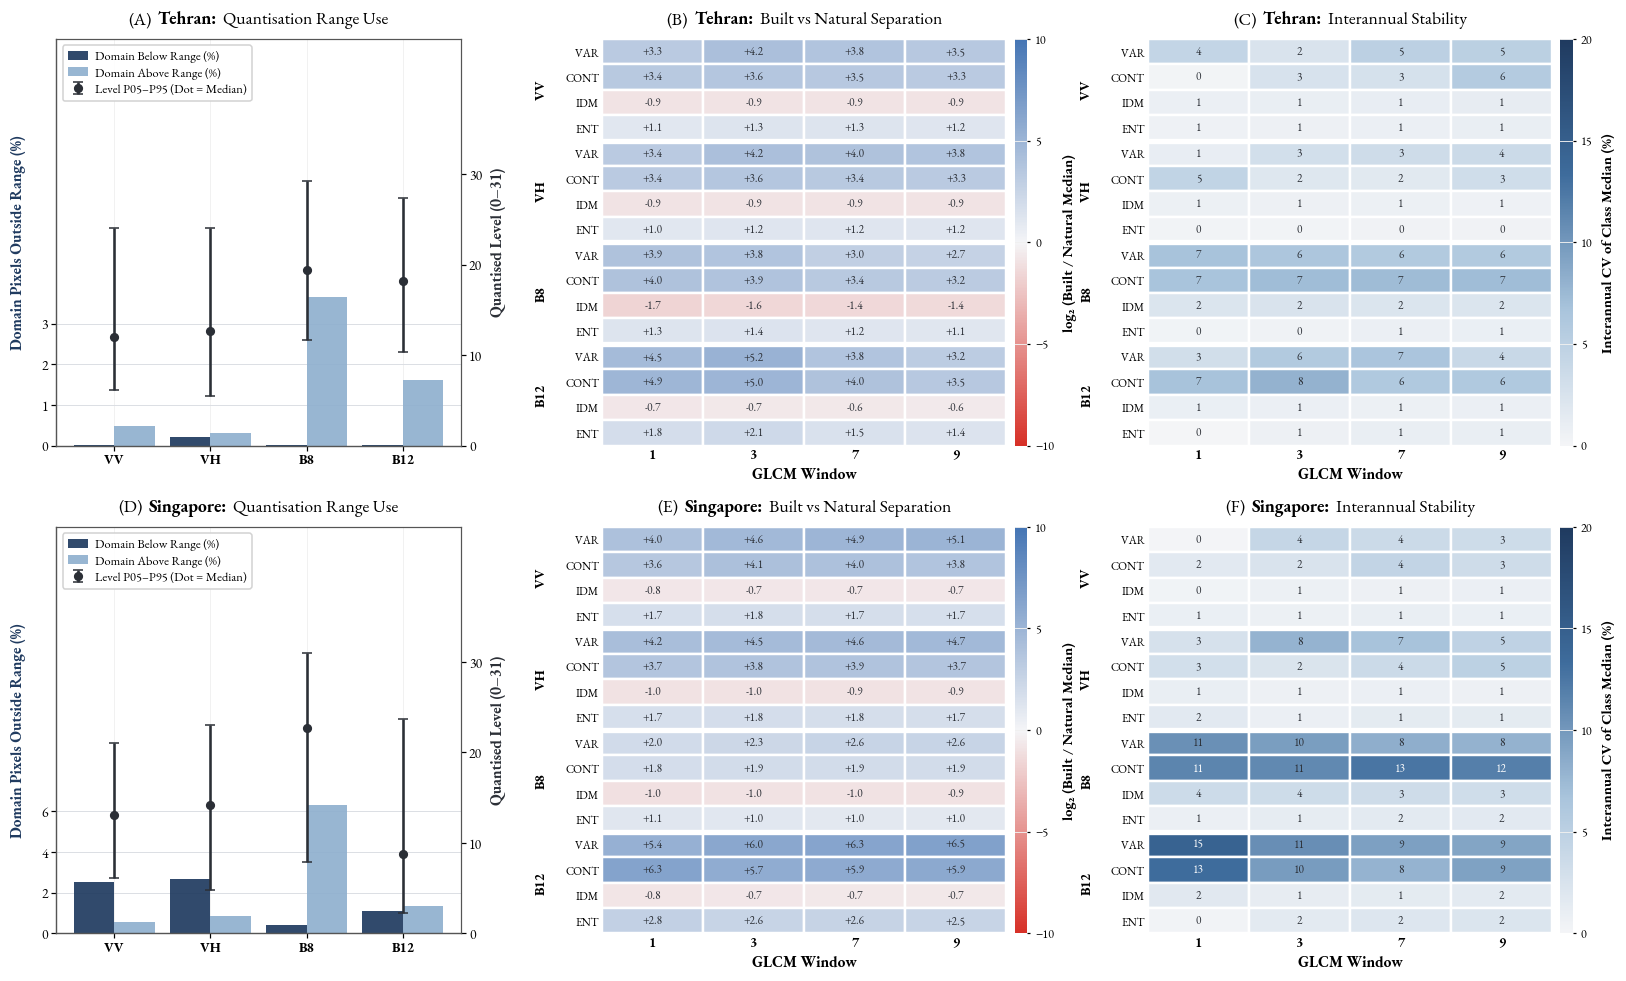

—————————————————————
GLCM Validation Audit
—————————————————————

[1] Quantisation (Mean Over Years)

Tehran

  VV   Domain Below   0.008 % | Above   0.489 % | Worst Class LCZ2   5.962 % | Level P05/P50/P95  6.1/12.0/24.0
  VH   Domain Below   0.211 % | Above   0.316 % | Worst Class LCZ1   4.398 % | Level P05/P50/P95  5.5/12.7/24.0
  B8   Domain Below   0.021 % | Above   3.648 % | Worst Class LCZG  17.700 % | Level P05/P50/P95 11.7/19.4/29.2
  B12  Domain Below   0.000 % | Above   1.621 % | Worst Class LCZ3   7.445 % | Level P05/P50/P95 10.4/18.2/27.4

Singapore

  VV   Domain Below   2.520 % | Above   0.549 % | Worst Class LCZG  89.425 % | Level P05/P50/P95  6.2/13.1/21.1
  VH   Domain Below   2.668 % | Above   0.831 % | Worst Class LCZG  78.002 % | Level P05/P50/P95  4.7/14.2/23.1
  B8   Domain Below   0.403 % | Above   6.318 % | Worst Class LCZG  21.437 % | Level P05/P50/P95  7.9/22.7/31.0
  B12  Domain Below   1.095 % | Above   1.336 % | Worst Class LCZG  37.442 % | Level P05/P50/

In [13]:
# —————————————————————————————
# [§10] GLCM Texture Validation
# —————————————————————————————

if GLCMQuantDF is not None and GLCMTexDF is not None:

    # Layout Constants

    FigSize     = ( 16 , 9.4 )

    TitleSize   = 11.5

    LabelSize   = 10

    TickSize    = 9

    LegendSize  = 8.2

    LineW       = 2.3

    MarkerS     = 5.0

    BarW        = 0.42

    PanelLabels = [ [ '(A)' , '(B)' , '(C)' ] , [ '(D)' , '(E)' , '(F)' ] ]

    PanelTitles = [ 'Quantisation Range Use' , 'Built vs Natural Separation' , 'Interannual Stability' ]

    BandOrder   = [ 'VV' , 'VH' , 'B8' , 'B12' ]

    MetricOrder = [ 'VAR' , 'CONTRAST' , 'IDM' , 'ENT' ]

    MetricLabel = { 'VAR' : 'VAR' , 'CONTRAST' : 'CONT' , 'IDM' : 'IDM' , 'ENT' : 'ENT' }

    BuiltClass  = [ 'LCZ1' , 'LCZ2' , 'LCZ3' ]

    NatureClass = [ 'LCZA' , 'LCZG' ]

    Windows     = sorted(int(W) for W in GLCMTexDF['Window'].unique())

    LevelMax    = int(GLCMQuantDF['LevelMax'].iloc[0])

    RowKeys     = [ ( B , M ) for B in BandOrder for M in MetricOrder ]

    CmapSep     = LinearSegmentedColormap.from_list( 'Sep' , [ '#D73027' , '#F4F5F7' , '#4575B4' ] )

    CmapStab    = LinearSegmentedColormap.from_list( 'Stab' , [ '#F4F5F7' , '#A9C4DC' , '#3E6C9C' , '#1F3A5F' ] )

    CmapSep.set_bad('#e6e8eb')

    CmapStab.set_bad('#e6e8eb')

    def StyleTwin( AxLeft , AxRight ):

        AxRight.grid(False)

        AxLeft.set_facecolor('white')

        AxLeft.set_axisbelow(True)

        AxLeft.grid( True , axis = 'y' , color = '#d9dde2' , linewidth = 0.6 )

        AxLeft.spines['top'].set_visible(True)

        AxLeft.spines['right'].set_visible(False)

        AxRight.spines['top'].set_visible(False)

        AxLeft.tick_params( axis = 'both' , labelsize = TickSize , pad = 2 )

        AxRight.tick_params( axis = 'y' , labelsize = TickSize , pad = 2 )

        AxRight.spines['right'].set_visible(True)

        for Spine in AxLeft.spines.values():

            Spine.set_linewidth(0.8)

            Spine.set_color('#555555')

        for Spine in AxRight.spines.values():

            Spine.set_linewidth(0.8)

            Spine.set_color('#555555')

    def MergedLegend( AxLeft , AxRight ):

        H1, L1 = AxLeft.get_legend_handles_labels()

        H2, L2 = AxRight.get_legend_handles_labels()

        Leg = AxRight.legend( H1 + H2 , L1 + L2 , loc = 'upper left' , ncol = 1 , fontsize = LegendSize , frameon = True , fancybox = True , framealpha = 0.93 , edgecolor = '#cfcfcf' , borderpad = 0.45 , labelspacing = 0.35 , columnspacing = 1.0 , handlelength = 1.6 , handletextpad = 0.5 )

        Leg.set_zorder(20)

    def NiceCeil(Value):

        if Value <= 0:

            return 1.0

        Exp  = 10 ** np.floor(np.log10(Value))

        Mant = next(M for M in ( 1 , 2 , 2.5 , 5 , 10 ) if Value / Exp <= M + 1e-9)

        return Mant * Exp

    def TickSet( Lo , Hi , Bins = 4 ):

        Raw = Ticker.MaxNLocator( nbins = Bins , steps = [ 1 , 2 , 5 , 10 ] ).tick_values( Lo , Hi )

        return [ T for T in Raw if Lo - 1e-9 <= T <= Hi + 1e-9 ]

    def DecimalsFor(Ticks):

        return int(max( 0 , -np.floor(np.log10(abs(Ticks[1] - Ticks[0]))) ))

    def PanelTitle( Ax , Row , Col , City ):

        Box = AnchoredOffsetbox( loc = 'lower center', child = HPacker( children = [ TextArea( PanelLabels[Row][Col] , textprops = dict( fontsize = TitleSize ) ) ,

        TextArea( f'{City}:' , textprops = dict( fontsize = TitleSize , fontweight = 'bold' ) ),

        TextArea( PanelTitles[Col] , textprops = dict( fontsize = TitleSize ) )], align = 'baseline' , pad = 0 , sep = 4 )      ,pad   = 0 , borderpad = 0.6 , frameon = False ,                                bbox_to_anchor = ( 0.5 , 1.0 ), bbox_transform=Ax.transAxes ,prop           = dict( size = TitleSize ))

        Ax.add_artist(Box)

        Box.set_clip_on(False)

    def ClassPivot(Tex):

        return Tex.pivot_table( index = [ 'Band' , 'Metric' , 'Window' , 'Year' ] , columns = 'Class' , values = 'Median' )

    def QuantisationSummary(Quant):

        Dom     = Quant[Quant['Scope'] == 'Domain']

        Cls     = Quant[Quant['Scope'] != 'Domain']

        Summary = {}

        for B in BandOrder:

            D          = Dom[Dom['Band'] == B]

            C          = Cls[Cls['Band'] == B].assign( Clip = lambda S: (S['FracBelow'] + S['FracAbove']) * 100 ).groupby('Scope')['Clip'].mean()

            Summary[B] = {

                'Below'     : D['FracBelow'].mean() * 100 ,

                'Above'     : D['FracAbove'].mean() * 100 ,

                'WorstClip' : C.max()                     ,

                'WorstName' : C.idxmax()                  ,

                'LevelP05'  : D['LevelP05'].mean()        ,

                'LevelP50'  : D['LevelP50'].mean()        ,

                'LevelP95'  : D['LevelP95'].mean()

            }

        return Summary

    def SeparationMatrix(Tex):

        Piv    = ClassPivot(Tex)

        Ratio  = np.log2(Piv[BuiltClass].median( axis = 1 ) / Piv[NatureClass].median( axis = 1 ))

        Ratio  = Ratio.replace( [ np.inf , -np.inf ] , np.nan )

        Lookup = Ratio.groupby([ 'Band' , 'Metric' , 'Window' ]).median().to_dict()

        return np.array( [ [ Lookup.get( ( B , M , W ) , np.nan ) for W in Windows ] for ( B , M ) in RowKeys ] , dtype = float )

    def StabilityMatrix(Tex):

        Piv    = ClassPivot(Tex)

        Group  = Piv.groupby([ 'Band' , 'Metric' , 'Window' ])

        CV     = (Group.std() / Group.mean()) * 100

        Lookup = CV.median( axis = 1 ).to_dict()

        return np.array( [ [ Lookup.get( ( B , M , W ) , np.nan ) for W in Windows ] for ( B , M ) in RowKeys ] , dtype = float )

    def DrawHeat( Ax , Mat , Norm , Cmap , Fmt , CbarLabel ):

        nR, nC = Mat.shape

        Ax.set_facecolor('white')

        Ax.set_aspect('auto')

        for i in range(nR):

            for j in range(nC):

                V = Mat[i, j]

                if np.isnan(V):

                    Txt, Col = '–', '#5A6270'

                    Face     = Cmap.get_bad()

                else:

                    Rgba     = Cmap(Norm(V))

                    Lum      = 0.299 * Rgba[0] + 0.587 * Rgba[1] + 0.114 * Rgba[2]

                    Txt, Col = Fmt.format(V), ('white' if Lum < 0.5 else '#2B2F36')

                    Face     = Rgba

                    Ax.add_patch(Rectangle( ( j - 0.5 , i - 0.5 ) , 1 , 1 , facecolor = Face , edgecolor = 'white' , linewidth = 1.6 , zorder = 1) )

                    Ax.text( j , i , Txt , ha = 'center' , va = 'center' , fontsize = 7.4 , color = Col , zorder = 4 )

        for K in range( 1 , len(BandOrder) ):

            Ax.axhline( K * len(MetricOrder) - 0.5 , color = 'white' , linewidth = 3.5 , zorder = 3 )

        Ax.set_xlim( -0.5 , nC - 0.5 )

        Ax.set_ylim( nR - 0.5 , -0.5 )

        Ax.grid( False , which = 'both' )

        Ax.tick_params( which = 'both' , length = 0 )

        Ax.set_xticks(range(nC))

        Ax.set_xticklabels( [ str(W) for W in Windows ] , fontsize = TickSize , fontweight = 'bold' )

        Ax.set_yticks(range(nR))

        Ax.set_yticklabels( [ MetricLabel[M] for B in BandOrder for M in MetricOrder ] , fontsize = 7.6 )

        Ax.set_xlabel( 'GLCM Window' , fontsize = LabelSize , fontweight = 'bold' , labelpad = 3 )

        Ax.tick_params( axis = 'both' , length = 0 , pad = 2 )

        for K, B in enumerate(BandOrder):

            Ax.text( -0.15 , K * len(MetricOrder) + (len(MetricOrder) - 1) / 2 , B , transform = Ax.get_yaxis_transform() , rotation = 90 , ha = 'center' , va = 'center' , fontsize = TickSize , fontweight = 'bold' , clip_on = False )

        for S in Ax.spines.values():

            S.set_visible(False)

        Cax = Ax.inset_axes([ 1.02 , 0.0 , 0.030 , 1.0 ])

        Cb  = Ax.figure.colorbar( ScalarMappable( norm = Norm , cmap = Cmap ) , cax = Cax )

        Cb.set_ticks(TickSet( Norm.vmin , Norm.vmax ))

        Cb.ax.tick_params( labelsize = TickSize - 1 , length = 2 )

        Cb.outline.set_visible(False)

        Cb.set_label( CbarLabel , fontsize = LabelSize - 0.5 , fontweight = 'bold' , labelpad = 6 )

    SepMats    = { C : SeparationMatrix(GLCMTexDF[GLCMTexDF['City'] == C]) for C in Cities }

    StabMats   = { C : StabilityMatrix(GLCMTexDF[GLCMTexDF['City'] == C])  for C in Cities }

    QuantStats = { C : QuantisationSummary(GLCMQuantDF[GLCMQuantDF['City'] == C]) for C in Cities }

    VSep       = NiceCeil(np.nanmax([ np.nanmax(np.abs(M)) for M in SepMats.values() ]))

    VStab      = NiceCeil(np.nanmax([ np.nanmax(M) for M in StabMats.values() ]))

    NormSep    = Normalize( -VSep , VSep )

    NormStab   = Normalize( 0 , VStab )

    Fig, Axes  = plt.subplots( 2 , 3 , figsize = FigSize )

    for RowIdx, City in enumerate(Cities):

        Stats  = QuantStats[City]

        X      = np.arange(len(BandOrder))

        Below  = np.array([ Stats[B]['Below'] for B in BandOrder ])

        Above  = np.array([ Stats[B]['Above'] for B in BandOrder ])

        LevLo  = np.array([ Stats[B]['LevelP05'] for B in BandOrder ])

        LevMid = np.array([ Stats[B]['LevelP50'] for B in BandOrder ])

        LevHi  = np.array([ Stats[B]['LevelP95'] for B in BandOrder ])

        # Column 1: Quantisation Range Use

        AxLeft  = Axes[RowIdx, 0]

        AxRight = AxLeft.twinx()

        StyleTwin( AxLeft , AxRight )

        AxLeft.bar( X - BarW / 2 , Below , width = BarW , color = '#1F3A5F' , alpha = 0.92 , label = 'Domain Below Range (%)' , edgecolor = 'none' )

        AxLeft.bar( X + BarW / 2 , Above , width = BarW , color = '#8FB0CF' , alpha = 0.92 , label = 'Domain Above Range (%)' , edgecolor = 'none' )

        AxLeft.set_ylabel( 'Domain Pixels Outside Range (%)' , color = '#1F3A5F' , fontweight = 'bold' , fontsize = LabelSize , labelpad = 3 )

        ClipMax   = max( float(np.nanmax(Below)) , float(np.nanmax(Above)) )

        ClipMax   = ClipMax if ClipMax > 0 else 1.0

        LeftTicks = TickSet( 0 , ClipMax * 1.05 )

        AxLeft.set_ylim( 0 , NiceCeil(ClipMax * 1.6) )

        AxLeft.set_yticks(LeftTicks)

        AxLeft.yaxis.set_major_formatter(Ticker.FormatStrFormatter(f'%.{DecimalsFor(LeftTicks)}f'))

        AxRight.errorbar( X , LevMid , yerr = [ LevMid - LevLo , LevHi - LevMid ] , fmt = 'o' , color = '#2B2F36' , ecolor = '#2B2F36' , elinewidth = LineW - 0.6 , capsize = 3.5 , markersize = MarkerS , label = 'Level P05–P95 (Dot = Median)' , zorder = 5 )

        AxRight.set_ylabel( f'Quantised Level (0–{LevelMax})' , color = '#2B2F36' , fontweight = 'bold' , fontsize = LabelSize , labelpad = 3 )

        AxRight.set_ylim( 0 , LevelMax * 1.45 )

        AxRight.set_yticks(TickSet( 0 , LevelMax ))

        AxLeft.yaxis.set_label_coords( -0.075 , 0.5 )

        AxRight.yaxis.set_label_coords( 1.075 , 0.5 )

        AxLeft.set_xticks(X)

        AxLeft.set_xticklabels( BandOrder , fontsize = TickSize , fontweight = 'bold' )

        AxLeft.set_xlim( -0.6 , len(BandOrder) - 0.4 )

        PanelTitle( AxLeft , RowIdx , 0 , City )

        MergedLegend( AxLeft , AxRight )

        # Column 2: Built vs Natural Separation

        DrawHeat( Axes[RowIdx, 1] , SepMats[City] , NormSep , CmapSep , '{:+.1f}' , 'log₂ (Built / Natural Median)' )

        PanelTitle( Axes[RowIdx, 1] , RowIdx , 1 , City )

        # Column 3: Interannual Stability

        DrawHeat( Axes[RowIdx, 2] , StabMats[City] , NormStab , CmapStab , '{:.0f}' , 'Interannual CV of Class Median (%)' )

        PanelTitle( Axes[RowIdx, 2] , RowIdx , 2 , City )

    Fig.subplots_adjust( left = 0.075 , right = 0.925 , bottom = 0.075 , top = 0.940 , hspace = 0.20 , wspace = 0.35 )

    SaveFigure( Fig , 'Figure 9 GLCM Validation' )

    plt.show()

    # —————
    # Audit
    # —————

    print('—————————————————————')
    print('GLCM Validation Audit')
    print('—————————————————————')

    print('\n[1] Quantisation (Mean Over Years)')

    for City in Cities:

        Stats = QuantStats[City]

        print(f'\n{City}\n')

        for B in BandOrder:

            S = Stats[B]

            print(f'  {B:<4} Domain Below {S["Below"]:7.3f} % | Above {S["Above"]:7.3f} % | '

                  f'Worst Class {S["WorstName"]} {S["WorstClip"]:7.3f} % | Level P05/P50/P95 {S["LevelP05"]:4.1f}/{S["LevelP50"]:4.1f}/{S["LevelP95"]:4.1f}')

    print('\n[2] Built vs Natural Separation (log2 Median Ratio, Median Over Years)')

    for City in Cities:

        Mat = SepMats[City]

        print(f'\n{City}\n')

        for M in MetricOrder:

            Rows = [ i for i , ( B , Mt ) in enumerate(RowKeys) if Mt == M ]

            Sub  = Mat[Rows, :]

            print(f'  {M:<9} Positive {int((Sub > 0).sum())} / {int(np.isfinite(Sub).sum())} | Median {np.nanmedian(Sub):+.2f}')

    print('\n[3] Interannual Stability (CV %, Median Over Classes)')

    for City in Cities:

        Mat  = StabMats[City]

        i, j = np.unravel_index( np.nanargmax(Mat) , Mat.shape )

        print(f'\n{City}\n')

        print(f'  Median CV = {np.nanmedian(Mat):.1f} % | Max CV = {np.nanmax(Mat):.1f} % ({RowKeys[i][0]} {RowKeys[i][1]}, Window {Windows[j]})')

    print('\n[4] Separation Robustness (Leave-One-Class-Out, Direction-Consistent Features Of 64; Expected: VAR, CONTRAST, ENT > 0 | IDM < 0)')

    for City in Cities:

        Piv = ClassPivot(GLCMTexDF[GLCMTexDF['City'] == City])

        print(f'\n{City}\n')

        for Drop in BuiltClass + NatureClass:

            Bt    = [ C for C in BuiltClass  if C != Drop ]

            Nt    = [ C for C in NatureClass if C != Drop ]

            Ratio = np.log2(Piv[Bt].median( axis = 1 ) / Piv[Nt].median( axis = 1 )).replace( [ np.inf , -np.inf ] , np.nan )

            Med   = Ratio.groupby([ 'Band' , 'Metric' , 'Window' ]).median()

            Met   = Med.index.get_level_values('Metric')

            Good  = ((Med > 0) & (Met != 'IDM')) | ((Med < 0) & (Met == 'IDM'))

            print(f'  Without {Drop:<5} {int(Good.sum())} / {len(Med)}')

            for Key, Val in Med[~Good].items():

                print(f'      {Key[0]:<4} {Key[1]:<9} Window {Key[2]}  ({Val:+.2f})')

    print()

---

#### **[§11] Map Panel Set**

—————————————
Map Panel Set
—————————————

  Visualization JS : /content/drive/MyDrive/UC4D/Visualization/UC4D-Visualization.js

  Figure Directory : /content/drive/MyDrive/UC4D/UC4D-Validation/Figures

  Save DPI         : 600

  Asset Root       : projects/ee-alirezaali/assets/UC4D

  Sites            : [('A', 'Tehran', 'SPR-2025'), ('B', 'Singapore', 'NEM-2025')]


   Parsed 47 Vis Entries From UC4D-Visualization.js

  → All 33 Layers Resolved From The Module.

  Tehran SPR-2025: Fetching 33 Layers



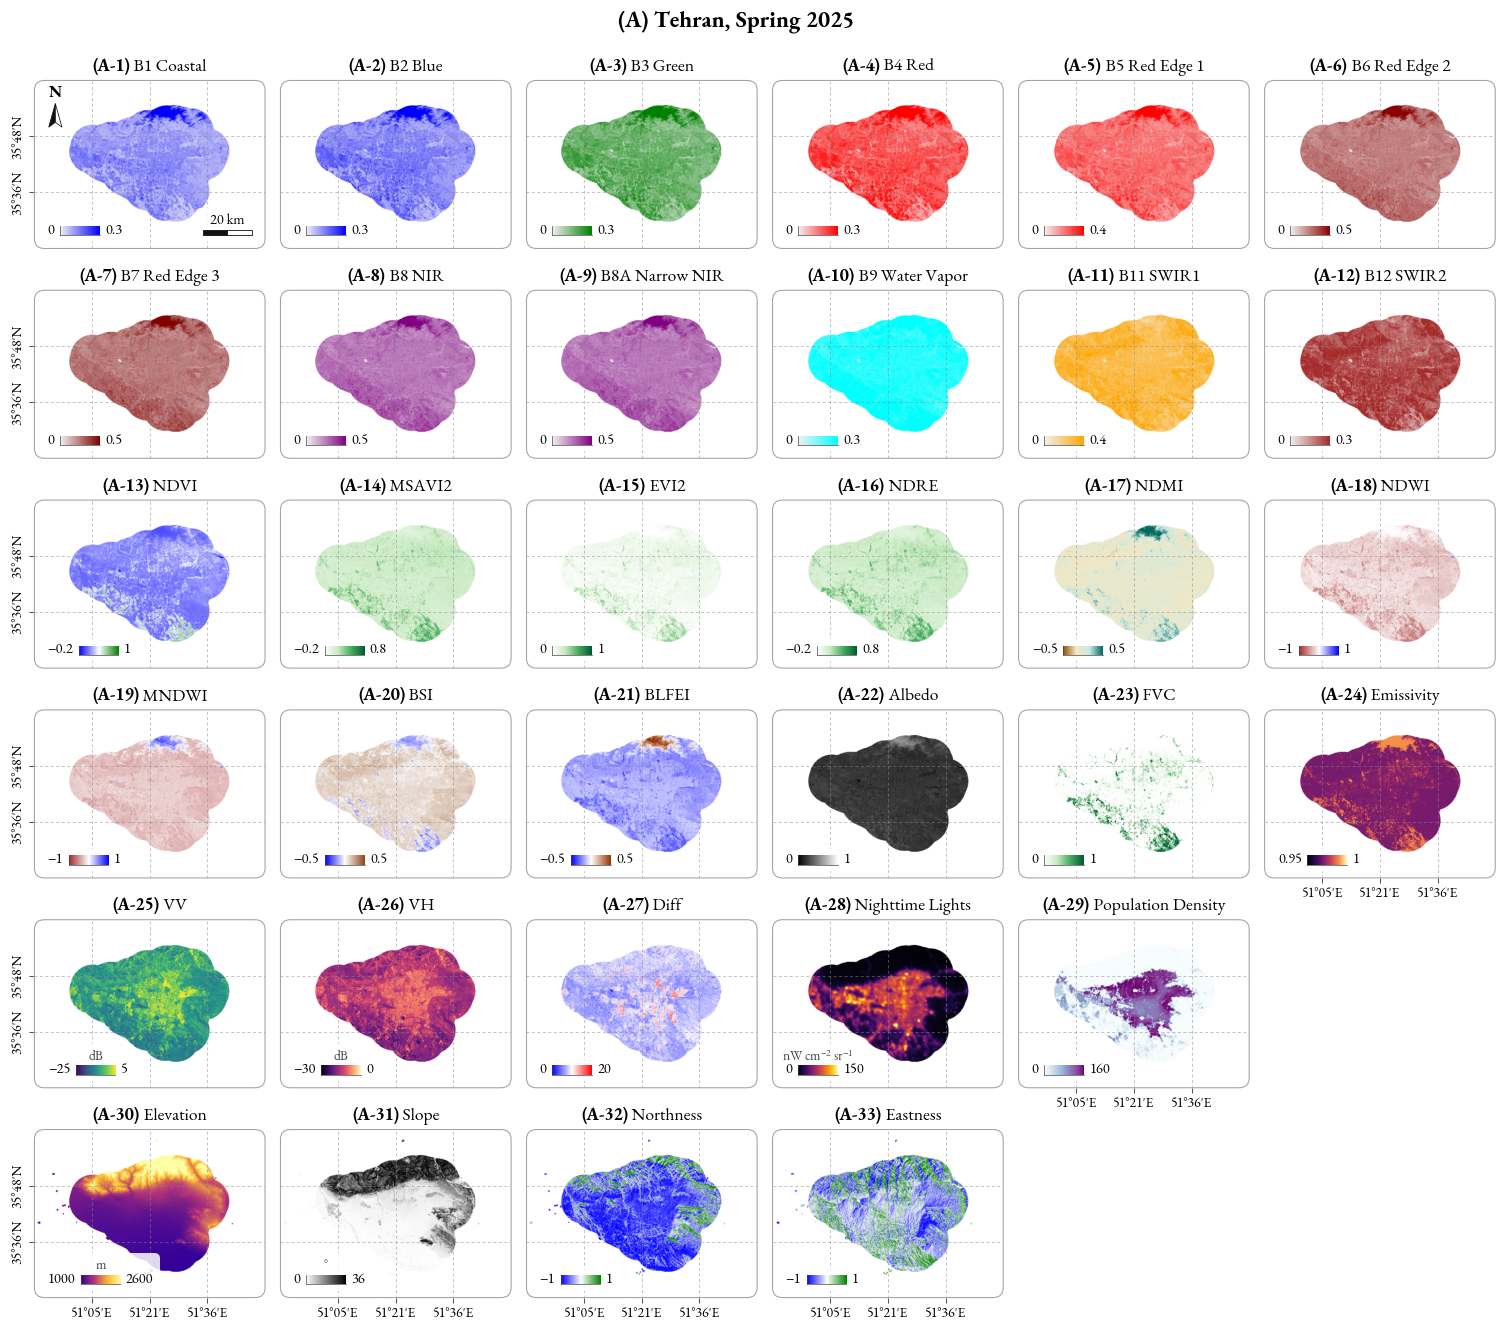

  Singapore NEM-2025: Fetching 33 Layers



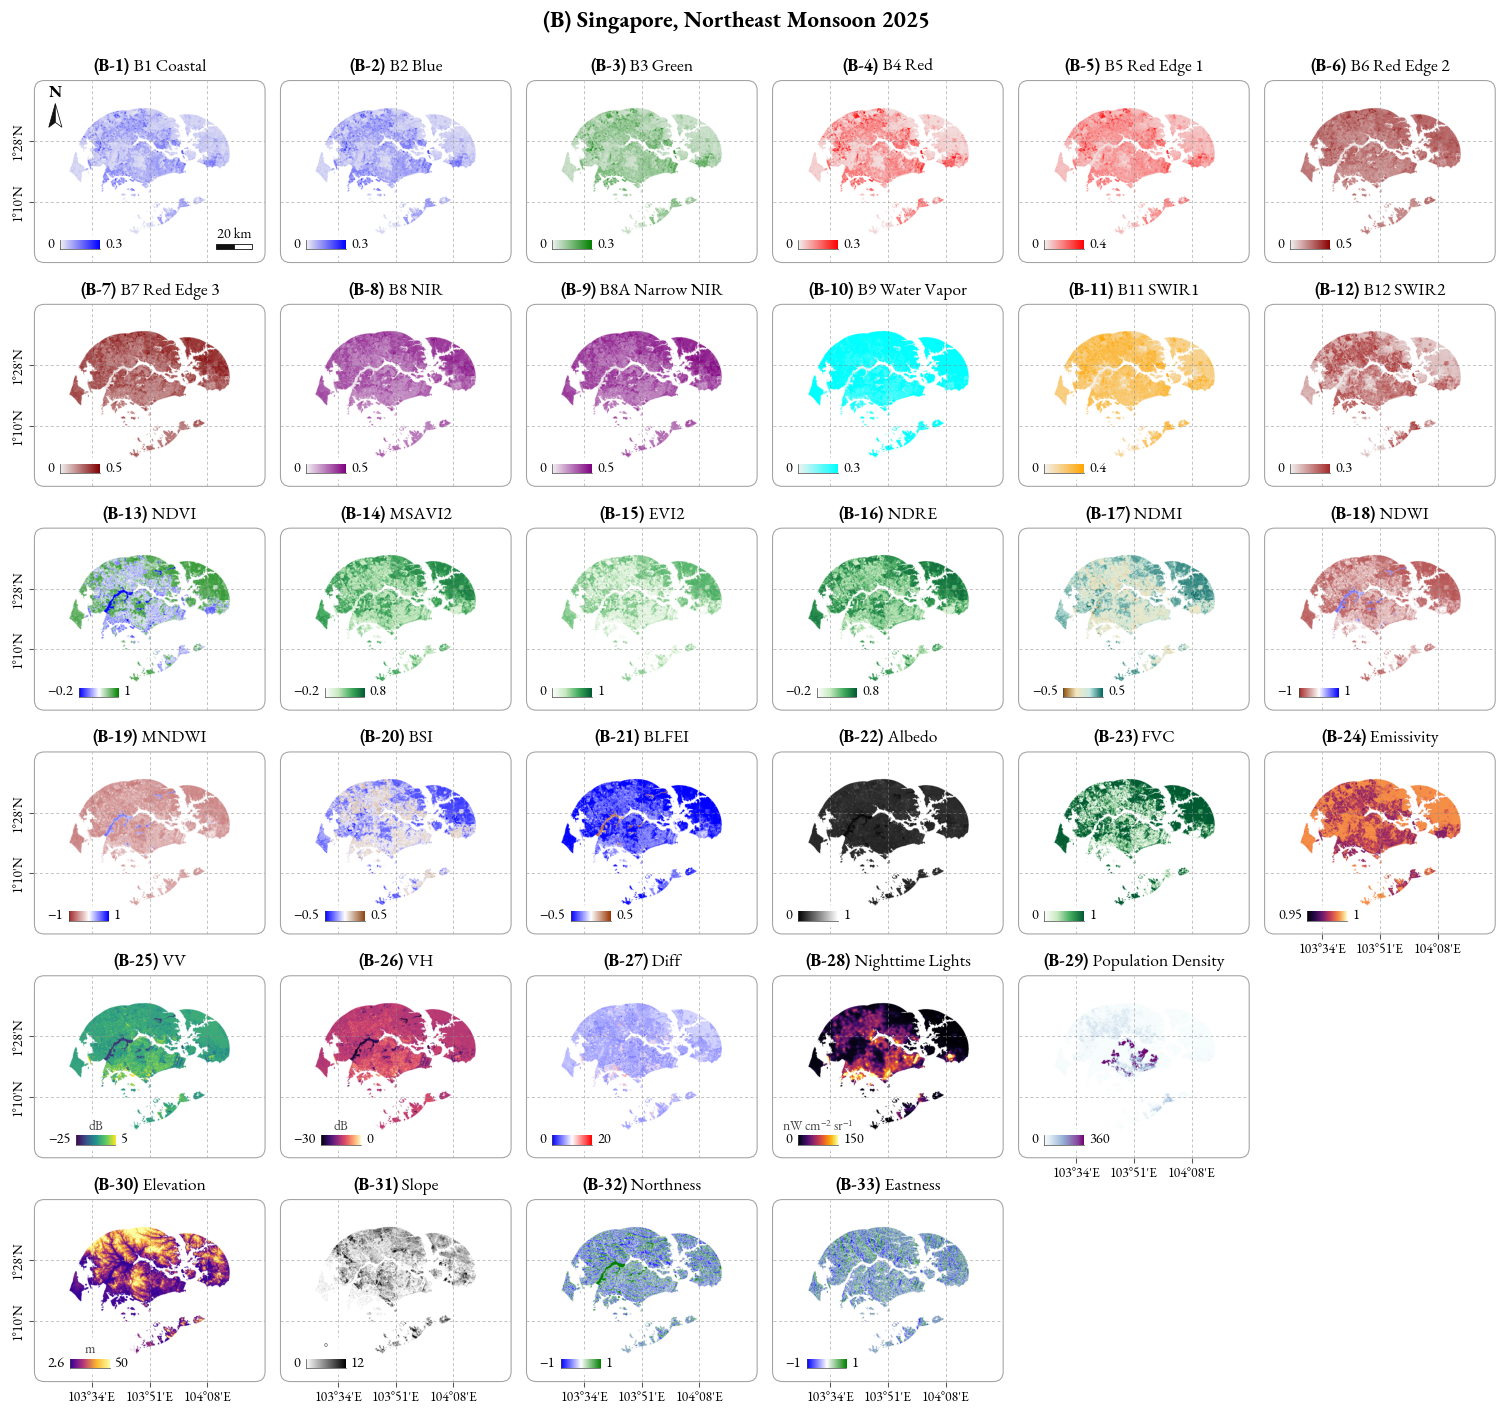

In [14]:
# ———————————————————
# [§11] Map Panel Set
# ———————————————————

if ee is None:

    raise RuntimeError(

        "Earth Engine Python API Is Not Available. §11 Has No Fallback. "

        "Install With: pip install earthengine-api"

)

if 'VisualizationJs' not in globals() or VisualizationJs is None:

    raise RuntimeError(

        "§0 Must Be Run Before §11 (VisualizationJs Config Not Found In Globals)."

)

VisJs = VisualizationJs

if not VisJs.exists():

    raise FileNotFoundError(

        f"UC4D Visualization Module Not Found At {VisJs}. §11 Has No Fallback."

)

# ————————
# Settings
# ————————

FinpBase = AssetRoot + '/STC/FINP'

Sites    = [

    ( chr(ord('A') + I) , City , f"{SeasonOrder[City][0]}-{Years[-1]}" )

    for I, City in enumerate(Cities)

]

SeasonNames = {

'SPR' : 'Spring' , 'SUM': 'Summer' , 'AUT': 'Autumn' , 'WIN': 'Winter' ,

'IM1' : 'Inter-Monsoon 1' , 'NEM': 'Northeast Monsoon'                 ,

'SWM' : 'Southwest Monsoon' , 'IM2': 'Inter-Monsoon 2'                 ,

}

Rows = [

    [ 'B1' , 'B2' , 'B3' , 'B4' , 'B5' , 'B6' ]                     ,
    
    [ 'B7' , 'B8' , 'B8A' , 'B9' , 'B11' , 'B12' ]                  ,

    [ 'NDVI' , 'MSAVI2' , 'EVI2' , 'NDRE' , 'NDMI' , 'NDWI' ]       ,

    [ 'MNDWI' , 'BSI' , 'BLFEI' , 'Albedo' , 'FVC' , 'Emissivity' ] ,

    [ 'VV' , 'VH' , 'Diff' , 'NTL' , 'PD' ]                         ,

    [ 'Elevation' , 'Slope' , 'Northness' , 'Eastness' ]

]

FigureWidth                                      = 14.0

ThumbPixels                                      = 1100

PadFraction                                      = 0.22

Workers                                          = 4

SavePdf                                          = False

OpticalDivisor                                   = 10000

AutoStretch                                      = {'Elevation': ( 5 , 95 ), 'Slope': ( None , 98 ), 'PD': ( None , 98 )}

FsTitle, FsLegend, FsTick, FsBlock               = 11.5, 9.4, 9.0, 15.0

MarginLeft, MarginRight, MarginTop, MarginBottom = 0.62, 0.10, 0.08, 0.06

GapX, GapY                                       = 0.14, 0.08

Header, TitleH, LonH                             = 0.46, 0.30, 0.30

RadiusInches                                     = 0.09

TickStepsArcmin                                  = ( 1 , 2 , 5 , 10 , 15 , 20 , 30 , 60 , 120 )

Preference                                       = {

    'legend'   : [ 'LL' , 'LR' , 'UR' , 'UL' ] ,

    'north'    : [ 'UL' , 'UR' , 'LL' , 'LR' ] ,

    'scalebar' : [ 'LR' , 'LL' , 'UR' , 'UL' ] ,

}

OccupancyOk                   = 0.02

LegendBarWidth                = 0.36

FrameColor, GridColor         = '#a3a3a3', '#8a8a8a'

LegendBox, ScaleBox, NorthBox = ( 1.05 , 0.30 ), ( 0.95 , 0.28 ), ( 0.28 , 0.40 )

# ——————————————
# Layer metadata
# ——————————————

def Layer( unit = '' , div = 1 , label = None , static = False , **Legacy ):

    if 'Unit'    in Legacy: unit   = Legacy['Unit']

    if 'Divisor' in Legacy: div    = Legacy['Divisor']

    if 'Label'   in Legacy: label  = Legacy['Label']

    if 'Static'  in Legacy: static = Legacy['Static']

    return dict( unit = unit , div = div , label = label , static = static )

Layers = {

    'B1'        : Layer( div = OpticalDivisor , label = 'B1 Coastal' )                         ,

    'B2'        : Layer( div = OpticalDivisor , label = 'B2 Blue' )                            ,

    'B3'        : Layer( div = OpticalDivisor , label = 'B3 Green' )                           ,

    'B4'        : Layer( div = OpticalDivisor , label = 'B4 Red' )                             ,

    'B5'        : Layer( div = OpticalDivisor , label = 'B5 Red Edge 1' )                      ,

    'B6'        : Layer( div = OpticalDivisor , label = 'B6 Red Edge 2' )                      ,

    'B7'        : Layer( div = OpticalDivisor , label = 'B7 Red Edge 3' )                      ,

    'B8'        : Layer( div = OpticalDivisor , label = 'B8 NIR' )                             ,

    'B8A'       : Layer( div = OpticalDivisor , label = 'B8A Narrow NIR' )                     ,

    'B9'        : Layer( div = OpticalDivisor , label = 'B9 Water Vapor' )                     ,

    'B11'       : Layer( div = OpticalDivisor , label = 'B11 SWIR1' )                          ,

    'B12'       : Layer( div = OpticalDivisor , label = 'B12 SWIR2' )                          ,

    'NDVI'      : Layer(), 'MSAVI2': Layer(), 'EVI2': Layer(), 'NDRE': Layer()                 ,

    'NDMI'      : Layer(), 'NDWI': Layer(), 'MNDWI': Layer(), 'BSI': Layer(), 'BLFEI': Layer() ,

    'Albedo'    : Layer(), 'FVC': Layer(), 'Emissivity': Layer()                               ,

    'VV'        : Layer( unit = 'dB' ), 'VH': Layer( unit = 'dB' ), 'Diff': Layer()            ,

    'NTL'       : Layer( unit = r'nW cm$^{-2}$ sr$^{-1}$' , label = 'Nighttime Lights' )       ,

    'PD'        : Layer( label = 'Population Density' )                                        ,

    'Elevation' : Layer( unit = 'm' , static = True )                                          ,

    'Slope'     : Layer( unit = '\u00b0' , static = True )                                     ,

    'Northness' : Layer( static = True ), 'Eastness': Layer( static = True )

}

# ———————————————————————————
# Visualization Module Parser
# ———————————————————————————

def Hex(Colour):

    S = str(Colour).strip().strip("'\"")

    if re.fullmatch( r'[0-9a-fA-F]{6}' , S ):

        return '#' + S

    return S

def ParseVisualisation(PathToJs):

    Text    = Path(PathToJs).read_text( encoding = 'utf-8' )

    Text    = re.sub( r'//[^\n]*' , '' , Text )

    Text    = re.sub( r'/\*.*?\*/' , '' , Text , flags = re.DOTALL )

    Pattern = re.compile(

        r'exports\.(\w+?)(?:VisParams|Vis)\s*=\s*\{(?P<body>.*?)\}\s*;?' ,

        re.DOTALL

)

    Out = {}

    for Match in Pattern.finditer(Text):

        Band         = Match.group(1)

        Body         = Match.group('body')

        MinMatch     = re.search( r'\bmin\s*:\s*([-\d.eE+]+)' , Body )

        MaxMatch     = re.search( r'\bmax\s*:\s*([-\d.eE+]+)' , Body )

        PaletteMatch = re.search( r'\bpalette\s*:\s*\[([^\]]+)\]' , Body , re.DOTALL )

        if not (MinMatch and MaxMatch and PaletteMatch):

            continue

        Palette   = [ Hex(C) for C in re.findall( r"['\"]([^'\"]+)['\"]" , PaletteMatch.group(1) ) ]

        Out[Band] = {

            'min'     : float(MinMatch.group(1)) ,

            'max'     : float(MaxMatch.group(1)) ,

            'palette' : Palette

        }

    return Out

def ApplyModuleVis(PathToJs):

    PathToJs = Path(PathToJs)

    if not PathToJs.exists():

        raise FileNotFoundError(f'UC4D-Visualization.js Not Found At {PathToJs}')

    Vis = ParseVisualisation(PathToJs)

    print(f'   Parsed {len(Vis)} Vis Entries From {PathToJs.name}\n')

    Sources = {}

    for Band in Layers:

        if Band not in Vis:

            raise RuntimeError(f'Layer "{Band}" not exported by {PathToJs.name}')

        V = Vis[Band]

        if not V.get('palette'):

            raise RuntimeError(f'Layer "{Band}" has empty palette in {PathToJs.name}')

        Layers[Band]['palette'] = V['palette']

        Layers[Band]['vmin']    = V['min']

        Layers[Band]['vmax']    = V['max']

        Sources[Band]           = 'MODULE'

    Missing = [ B for B , S in Sources.items() if S != 'MODULE' ]

    if Missing:

        raise RuntimeError(f'Layers without a MODULE palette: {Missing}')

    return Sources

# ————————————
# Earth Engine
# ————————————

def InitEarthEngine():

    try:

        ee.Initialize( project = EarthEngineProject )

    except Exception as E:

        raise RuntimeError(

            f"Earth Engine Not Initialized For Project '{EarthEngineProject}'. "

            f"Run ee.Authenticate() In a Separate Cell, Then Re-run §11. "

            f"§11 Has No Fallback. Underlying Error: {str(E)[:240]}"

) from E

def UnscaleImage(Img):

    Specs = [

        ([ 'NDVI' , 'MNDWI' , 'NDWI' , 'BLFEI' , 'EVI2' , 'MSAVI2' , 'NDMI' , 'Emissivity' , 'Albedo' ,

          'Northness' , 'Eastness' , 'NDRE' , 'BSI' , 'FVC' , 'SVF' , 'BCR' , 'FAI']               , 10000 ) ,

        ( [ 'VV' , 'VH' , 'Diff' , 'SDH' ]                                                         , 100   ) ,

        ( [ 'NTL' , 'BH' , 'PD' ]                                                                  , 100   ) ,

        ( [ 'B1' , 'B2' , 'B3' , 'B4' , 'B5' , 'B6' , 'B7' , 'B8' , 'B8A' , 'B9' , 'B11' , 'B12' ] , 1     ) ,

        ( [ 'Elevation' ]                                                                          , 100   ) ,

        ( [ 'Slope' ]                                                                              , 100   )

    ]

    Present = Img.bandNames().getInfo()

    Groups  = []
    
    for Bands, Scale in Specs:

        Intersect = [ B for B in Bands if B in Present ]

        if not Intersect:

            continue
            
        Sub = Img.select(Intersect).toFloat()

        Groups.append(Sub.divide(Scale) if Scale != 1 else Sub)

    return ee.Image.cat(Groups).select(Present)

def Nice2(V):

    return float(f'{V:.2g}') if V else 0.0

def AutoLimits( Img , Geom , Band , LowPct , HighPct , Fallback ):

    Pcts = [ P for P in ( LowPct , HighPct ) if P is not None ]

    try:

        Stats = (Img.select(Band)

                    .reduceRegion(

                        reducer = ee.Reducer.percentile(Pcts),

geometry  = Geom ,

scale     = 100  ,

maxPixels = 1e13 ,

                        bestEffort = True

                    ).getInfo()) or {}

        Values = sorted(V for V in Stats.values() if V is not None)

        if len(Values) == 2:

            Low, High = Nice2(Values[0]), Nice2(Values[1])

        elif len(Values) == 1:

            Low, High = Fallback[0], Nice2(Values[0])

        else:

            return Fallback

        return ( Low , High ) if High > Low else Fallback

    except Exception as E:

        print(f'  ! Auto Stretch {Band}: {str(E)[:100]}\n')

        return Fallback

def PrepareSite( Letter , City , SeasonLabel ):

    DynAsset       = f'{FinpBase}/{City}/Dynamic/{City}-{SeasonLabel}'

    StaAsset       = f'{FinpBase}/{City}/Static/{City}'

    DynRaw, StaRaw = ee.Image(DynAsset), ee.Image(StaAsset)

    Ring           = DynRaw.geometry().bounds().getInfo()['coordinates'][0]

    Lons, Lats     = [ P[0] for P in Ring ], [ P[1] for P in Ring ]

    Lon0, Lon1     = min(Lons), max(Lons)

    Lat0, Lat1     = min(Lats), max(Lats)

    PadX, PadY     = PadFraction * (Lon1 - Lon0), PadFraction * (Lat1 - Lat0)

    Lon0, Lon1     = Lon0 - PadX, Lon1 + PadX

    Lat0, Lat1     = Lat0 - PadY, Lat1 + PadY

    Region         = [ [ Lon0 , Lat0 ] , [ Lon1 , Lat0 ] , [ Lon1 , Lat1 ] , [ Lon0 , Lat1 ] , [ Lon0 , Lat0 ] ]

    LatC           = 0.5 * (Lat0 + Lat1)

    WidthM         = (Lon1 - Lon0) * 111320 * math.cos(math.radians(LatC))

    HeightM        = (Lat1 - Lat0) * 111320

    Dyn, Sta       = UnscaleImage(DynRaw), UnscaleImage(StaRaw)

    Auto           = {}

    for Band, ( LowPct , HighPct ) in AutoStretch.items():

        Img, Geom  = ( Sta , StaRaw.geometry() ) if Layers[Band]['static'] else ( Dyn , DynRaw.geometry() )

        Auto[Band] = AutoLimits( Img , Geom , Band , LowPct , HighPct , ( Layers[Band]['vmin'] , Layers[Band]['vmax'] ) )

    Season, Year = SeasonLabel.split('-')

    return dict(

        letter  = Letter , city = City , season = Season , year = Year , label = SeasonLabel ,

        region  = Region                                                                     ,

        lon0    = Lon0 , lon1 = Lon1 , lat0 = Lat0 , lat1 = Lat1                             ,

        width_m = WidthM , height_m = HeightM , aspect = WidthM / HeightM                    ,

        dyn = Dyn, sta = Sta, auto = Auto

)

def LayerMeta( Band , Site ):

    M = dict(Layers[Band])

    if Band in AutoStretch and Band in Site['auto']:

        M['vmin'], M['vmax'] = Site['auto'][Band]

    return M

def ThumbDims(Site):

    Dx, Dy = Site['lon1'] - Site['lon0'], Site['lat1'] - Site['lat0']

    return (( ThumbPixels , max( 1 , round(ThumbPixels * Dy / Dx) ) ) if Dx >= Dy

            else ( max( 1 , round(ThumbPixels * Dx / Dy) ) , ThumbPixels ))

CacheDir = BaseDir / 'Gallery Cache'

CacheDir.mkdir( parents = True , exist_ok = True )

def FetchThumb( Img , Band , Vmin , Vmax , Palette , Region , Dims , Key , Retries = 5 ):

    F = CacheDir / f'{Key}.png'

    if F.exists():

        return Image.open(F).convert('RGBA')

    Err = None

    for K in range(Retries):

        try:

            Url = Img.select(Band).getThumbURL({

                'min'        : Vmin                   ,

                'max'        : Vmax                   ,

                'palette'    : Palette                ,

                'region'     : Region                 ,

                'dimensions' : f'{Dims[0]}x{Dims[1]}' ,

                'crs'        : 'EPSG:4326'            ,

                'format'     : 'png'

            })

            R = requests.get( Url , timeout = 180 )

            if 'json' in R.headers.get( 'Content-Type' , '' ) or R.content[:1] == b'{':

                raise RuntimeError(f'GEE: {R.text[:240]}')

            R.raise_for_status()

            ImgOut = Image.open(BytesIO(R.content)).convert('RGBA')

            ImgOut.save(F)

            return ImgOut

        except Exception as E:

            Err = E

            time.sleep(2 * (K + 1))

    raise Err

def FetchLayers(Site):

    Dims  = ThumbDims(Site)

    Bands = [ B for Row in Rows for B in Row ]

    def Job(Band):

        M   = LayerMeta( Band , Site )

        Src = Site['sta'] if M['static'] else Site['dyn']

        Sig = hashlib.md5(

            json.dumps([ M['palette'] , M['vmin'] , M['vmax'] , PadFraction ]).encode()

        ).hexdigest()[:8]

        Key = f"{Site['city']}-{Site['label']}-{Band}-v8-{ThumbPixels}-{Sig}"

        return FetchThumb( Src , Band , M['vmin'] , M['vmax'] , M['palette'] , Site['region'] , Dims , Key )

    Out = {}

    with ThreadPoolExecutor( max_workers = Workers ) as Ex:

        Futs = {Ex.submit( Job , B ): B for B in Bands}

        for Fu in as_completed(Futs):

            B = Futs[Fu]

            try:

                Out[B] = Fu.result()

            except Exception as E:

                print(f"  ! ERROR {Site['city']} {B}: {str(E)[:300]}\n")

                Out[B] = None

    return Out

# —————————
# Rendering
# —————————

def FormatLegend(V):

    S = f'{V:.0f}' if abs(V) >= 10 else f'{V:.2f}'.rstrip('0').rstrip('.')

    return ('0' if S in ( '-0' , '' ) else S).replace( '-' , '\u2212' )

def DegLabel( V , Axis ):

    Hemi = ('E' if V >= 0 else 'W') if Axis == 'lon' else ('N' if V >= 0 else 'S')

    A    = abs(V)

    D    = int(A + 1e-9)

    M    = int(round((A - D) * 60))

    if M == 60:

        D, M = D + 1, 0

    return f"{D}\u00b0{Hemi}" if M == 0 else f"{D}\u00b0{M:02d}'{Hemi}"

Renderer   = None

WidthCache = {}

def EstWidth( S , Fs ):

    global Renderer

    Key = ( S , round( Fs , 2 ) )

    if Key not in WidthCache:

        if Renderer is None:

            Renderer = RendererAgg( 100 , 100 , 72 )

        Fp              = FontManager.FontProperties( size = Fs )

        W, _, _         = Renderer.get_text_width_height_descent( S , Fp , '$' in S )

        WidthCache[Key] = W / 72.0

    return WidthCache[Key]

def AutoTicks( Site , Pw , Ph ):

    tx = list(np.linspace( Site['lon0'] , Site['lon1'] , 5 )[1:-1])

    ty = list(np.linspace( Site['lat0'] , Site['lat1'] , 4 )[1:-1])

    return tx, ty

def CornerXY( Corner , W , H , Pw , Ph , Margin = 0.06 ):

    return (

        Margin if Corner[1] == 'L' else Pw - Margin - W ,

        Margin if Corner[0] == 'L' else Ph - Margin - H ,

)

def Backing( Ax , X , Y , W , H , Pw , Ph ):

    Ax.add_patch(FancyBboxPatch(

        ( X / Pw , Y / Ph ), W / Pw, H / Ph,

        boxstyle        = f'round,pad=0,rounding_size={0.05 / Pw}' ,

        mutation_aspect = Pw / Ph                                  ,

        transform       = Ax.transAxes                             ,

        facecolor       = 'white'                                  ,

        edgecolor       = 'none'                                   ,

        alpha           = 0.85                                     ,

        zorder          = 6

    ))

def DrawLegend( Ax , Corner , Cmap , Lo , Hi , Unit , Pw , Ph ):

    Lt, Rt               = FormatLegend(Lo), FormatLegend(Hi)

    BarW, BarH, Gap, Pad = min( LegendBarWidth , 0.2 * Pw ), 0.085, 0.05, 0.06

    Wl, Wr               = EstWidth( Lt , FsLegend ), EstWidth( Rt , FsLegend )

    UnitH                = 0.14 if Unit else 0.0

    W                    = max( 2 * Pad + Wl + Gap + BarW + Gap + Wr , 2 * Pad + (EstWidth( Unit , FsLegend - 0.6 ) if Unit else 0) )

    H                    = 2 * Pad + BarH + UnitH

    X0, Y0               = CornerXY( Corner , W , H , Pw , Ph )

    Backing( Ax , X0 , Y0 , W , H , Pw , Ph )

    Bx  = X0 + (W - (Wl + Gap + BarW + Gap + Wr)) / 2 + Wl + Gap

    By  = Y0 + Pad

    Cax = Ax.inset_axes([ Bx / Pw , By / Ph , BarW / Pw , BarH / Ph ])

    Cax.imshow( np.linspace( 0 , 1 , 256 )[None, :] , cmap = Cmap , aspect = 'auto' )

    Cax.set_xticks([]); Cax.set_yticks([]); Cax.set_zorder(8)

    for Sp in Cax.spines.values():

        Sp.set_linewidth(0.45); Sp.set_edgecolor('#444444')

    Yc = (By + BarH / 2) / Ph

    Ax.text( (Bx - Gap) / Pw , Yc , Lt , ha = 'right' , va = 'center' , fontsize = FsLegend , transform = Ax.transAxes , zorder = 8 )

    Ax.text( (Bx + BarW + Gap) / Pw , Yc , Rt , ha = 'left' , va = 'center' , fontsize = FsLegend , transform = Ax.transAxes , zorder = 8 )

    if Unit:

        Ax.text( (Bx + BarW / 2) / Pw , (By + BarH + 0.015) / Ph , Unit , ha = 'center' , va = 'bottom' , fontsize = FsLegend - 0.6 , color = '#444444' , transform = Ax.transAxes , zorder = 8 )

def NiceKm( WidthM , Frac = 0.26 ):

    Target = WidthM * Frac / 1000

    for L in ( 50 , 20 , 10 , 5 , 2 , 1 , 0.5 ):

        if L <= Target:

            return L

    return 0.5

def DrawScalebar( Ax , Corner , WidthM , Pw , Ph ):

    L                   = NiceKm(WidthM)

    BarIn, Txt, Pad, Th = L * 1000 / WidthM * Pw, f'{L:g} km', 0.06, 0.05

    W                   = 2 * Pad + max( BarIn , EstWidth( Txt , FsLegend ) )

    H                   = 2 * Pad + Th + 0.14

    X0, Y0              = CornerXY( Corner , W , H , Pw , Ph )

    Backing( Ax , X0 , Y0 , W , H , Pw , Ph )

    Bx, By = X0 + (W - BarIn) / 2, Y0 + Pad

    for K, Fc in enumerate(( '#111111' , 'white' )):

        Ax.add_patch(Rectangle(

            ( (Bx + K * BarIn / 2) / Pw , By / Ph ) ,

            BarIn / 2 / Pw , Th / Ph ,

            transform = Ax.transAxes ,

            facecolor = Fc           ,

            edgecolor = '#111111'  ,

            linewidth = 0.55         ,

            zorder = 8    ))

    Ax.text( (Bx + BarIn / 2) / Pw , (By + Th + 0.015) / Ph , Txt , 

ha       = 'center' , va = 'bottom' ,

fontsize = FsLegend , transform = Ax.transAxes , zorder = 8 )

def DrawNorth( Ax , Corner , Pw , Ph ):

    W, H   = 0.26, 0.38

    X0, Y0 = CornerXY( Corner , W , H , Pw , Ph )

    Backing( Ax , X0 , Y0 , W , H , Pw , Ph )

    Cx, Cy     = X0 + W / 2, Y0 + 0.09

    T, L, R, N = ( 0 , 0.14 ), ( -0.06 , -0.075 ), ( 0.06 , -0.075 ), ( 0 , -0.03 )

    def Pts(*P):

        return [ ( (Cx + P[0]) / Pw , (Cy + P[1]) / Ph ) for P in P ]

    Ax.add_patch(Polygon( Pts( T , L , N ) , closed = True , transform = Ax.transAxes , facecolor = '#111111' , edgecolor = '#111111' , linewidth = 0.5 , zorder = 8 ))

    Ax.add_patch(Polygon( Pts( T , R , N ) , closed = True , transform = Ax.transAxes , facecolor = 'white' , edgecolor = '#111111' , linewidth = 0.5 , zorder = 8 ))

    Ax.text( Cx / Pw , (Cy + 0.14 + 0.02) / Ph , 'N' , ha = 'center' , va = 'bottom' , fontsize = FsLegend + 1.2 , fontweight = 'bold' , transform = Ax.transAxes , zorder = 8 )

def PickCorners( Cov , Pw , Ph ):

    H, W = Cov.shape

    def Occ( Corner , Box ):

        Wf, Hf = min( 1 , Box[0] / Pw ), min( 1 , Box[1] / Ph )

        C0, C1 = ( 0 , int(W * Wf) ) if Corner[1] == 'L' else ( W - int(W * Wf) , W )

        R0, R1 = ( 0 , int(H * Hf) ) if Corner[0] == 'U' else ( H - int(H * Hf) , H )

        return float(Cov[R0:R1, C0:C1].mean()) if (R1 > R0 and C1 > C0) else 1.0

    Used, Out = [], {}

    for Kind, Box in ( ( 'legend' , LegendBox ) , ( 'north' , NorthBox ) , ( 'scalebar' , ScaleBox ) ):

        Cand = [ C for C in Preference[Kind] if C not in Used ]

        Ok   = [ C for C in Cand if Occ( C , Box ) <= OccupancyOk ]

        Pick = (Ok[0] if Ok

                else min( Cand , key = lambda C: ( round( Occ( C , Box ) , 3 ) , Preference[Kind].index(C) ) ))

        Out[Kind] = Pick

        Used.append(Pick)

    return Out

def PrepThumb(Img):

    A     = np.asarray(Img).astype(np.float32)

    Alpha = A[..., 3:4] / 255.0

    Rgb   = (A[..., :3] * Alpha + 255.0 * (1 - Alpha)).astype(np.uint8)

    return Rgb, A[..., 3] > 0

def SeasonText(Site):

    return f"{SeasonNames.get(Site['season'], Site['season'])} {Site['year']}"

def PanelTitle( Ax , Tag , Label ):

    Pack = HPacker(

        children = [ TextArea( Tag , textprops = dict( fontsize = FsTitle , fontweight = 'bold' ) ) , TextArea( ' ' + Label , textprops = dict( fontsize = FsTitle ) ), ] , align = 'baseline' , pad = 0 , sep = 0, )

    Ax.add_artist(AnnotationBbox( Pack , ( 0.5 , 1.0 ) , xycoords = 'axes fraction' , box_alignment = ( 0.5 , 0 ) , xybox = ( 0 , 3 ) , boxcoords = 'offset points' , frameon = False , pad = 0 , ))

def BuildFigure( Site , Thumbs ):

    NCols = max(len(R) for R in Rows)

    NRows = len(Rows)

    Pw    = (FigureWidth - MarginLeft - MarginRight - (NCols - 1) * GapX) / NCols

    Ph    = Pw / Site['aspect']

    H     = (MarginTop + Header + NRows * (TitleH + Ph) + (NRows - 1) * GapY + LonH + MarginBottom)

    Fig = plt.figure( figsize = ( FigureWidth , H ) , facecolor = 'white' )

    Fig.text( 0.5 , 1 - (MarginTop + Header / 2) / H , f"({Site['letter']}) {Site['city']}, {SeasonText(Site)}" , ha = 'center' , va = 'center' , fontsize = FsBlock , fontweight = 'bold' )

    Prepped = {B: (PrepThumb(T) if T is not None else ( None , None ))

               for B, T in Thumbs.items()}

    Cov = None

    for B, ( Rgb , Mask ) in Prepped.items():

        if Mask is not None:

            Cov = Mask if Cov is None or Cov.shape != Mask.shape else (Cov | Mask)

    Cov     = Cov if Cov is not None else np.zeros( ( 10 , 10 ) , bool )

    Corners = PickCorners( Cov , Pw , Ph )

    Xt, Yt  = AutoTicks( Site , Pw , Ph )

    K       = 0

    for R, RowBands in enumerate(Rows):

        for C, Band in enumerate(RowBands):

            K += 1

            Left  = MarginLeft + C * (Pw + GapX)

            Top   = MarginTop + Header + R * (TitleH + Ph + GapY) + TitleH

            Rect  = [ Left / FigureWidth , 1 - (Top + Ph) / H , Pw / FigureWidth , Ph / H ]

            Meta  = LayerMeta( Band , Site )

            Below = R + 1 < NRows and C < len(Rows[R + 1])

            Ax    = Fig.add_axes(Rect)

            Ax.set_xlim( Site['lon0'] , Site['lon1'] )

            Ax.set_ylim( Site['lat0'] , Site['lat1'] )

            Ax.set_autoscale_on(False)

            Ax.patch.set_visible(False)

            for Sp in Ax.spines.values():

                Sp.set_visible(False)

            Fk = dict(

            boxstyle        = f'round,pad=0,rounding_size={RadiusInches / Pw}' ,

            mutation_aspect = Pw / Ph                                          ,

            transform       = Ax.transAxes

            )

            BgPatch = FancyBboxPatch( ( 0 , 0 ) , 1 , 1 , facecolor = 'white' , edgecolor = 'none' , zorder = 1 , **Fk )

            Ax.add_patch(BgPatch)

            if Prepped[Band][0] is not None:

                Im = Ax.imshow( Prepped[Band][0] , extent = ( Site['lon0'] , Site['lon1'] , Site['lat0'] , Site['lat1'] ) , origin = 'upper' , aspect = 'auto' , interpolation = 'antialiased' , zorder = 2 )

                Im.set_clip_path(BgPatch)

            else:

                Ax.text( 0.5 , 0.5 , 'Layer Unavailable' , ha = 'center' , va = 'center' , transform = Ax.transAxes , fontsize = FsLegend , color = '#999999' )

            for X in Xt:

                Ln, = Ax.plot( [ X , X ] , [ Site['lat0'] , Site['lat1'] ] , color = GridColor , lw = 0.55 , alpha = 0.6 , dashes = ( 3.5 , 3 ) , zorder = 4 )

                Ln.set_clip_path(BgPatch)

            for Y in Yt:

                Ln, = Ax.plot( [ Site['lon0'] , Site['lon1'] ] , [ Y , Y ] , color = GridColor , lw = 0.55 , alpha = 0.6 , dashes = ( 3.5 , 3 ) , zorder = 4 )

                Ln.set_clip_path(BgPatch)

            Ax.add_patch(FancyBboxPatch( ( 0 , 0 ) , 1 , 1 , fill = False , edgecolor = FrameColor , linewidth = 0.7 , zorder = 10 , clip_on = False , **Fk ))

            Ax.set_xticks(Xt); Ax.set_yticks(Yt)

            Ax.set_xticklabels( [ DegLabel( X , 'lon' ) for X in Xt ] if not Below else [] , fontsize = FsTick )

            Ax.set_yticklabels( [ DegLabel( Y , 'lat' ) for Y in Yt ] if C == 0 else [] , fontsize = FsTick , rotation = 90 , va = 'center')

            Ax.tick_params( axis = 'x' , length = 3.5 if not Below else 0 , width = 0.7 , color = '#555555' , pad = 2.5 )

            Ax.tick_params( axis = 'y' , length = 3.5 if C == 0 else 0 , width = 0.7 , color = '#555555' , pad = 2.5 )

            Cmap = LinearSegmentedColormap.from_list( Band , Meta['palette'] )

            DrawLegend( Ax , Corners['legend'] , Cmap , Meta['vmin'] / Meta['div'] , Meta['vmax'] / Meta['div'] , Meta['unit'] , Pw , Ph )

            if K == 1:

                DrawScalebar( Ax , Corners['scalebar'] , Site['width_m'] , Pw , Ph )

                DrawNorth( Ax , Corners['north'] , Pw , Ph )

            PanelTitle( Ax , f"({Site['letter']}-{K})" , Meta['label'] or Band )

    return Fig

# —————————
# Execution
# —————————

print('—————————————')
print('Map Panel Set')
print('—————————————\n')

print(f"  Visualization JS : {VisJs}\n")

print(f"  Figure Directory : {FigureDir}\n")

print(f"  Save DPI         : {SaveDPI}\n")

print(f"  Asset Root       : {AssetRoot}\n")

print(f"  Sites            : {Sites}\n")

print()

Sources = ApplyModuleVis(VisJs)

if any(S != 'MODULE' for S in Sources.values()):

    raise RuntimeError('Zero-Fallback Check Failed: Some Layer Lacks a MODULE Source.')

print(f"  → All {len(Layers)} Layers Resolved From The Module.\n")

InitEarthEngine()

for SiteTuple in Sites:

    Site = PrepareSite(*SiteTuple)

    NLay = sum(len(R) for R in Rows)

    print(f"  {Site['city']} {Site['label']}: Fetching {NLay} Layers\n")

    Thumbs = FetchLayers(Site)

    Fig    = BuildFigure( Site , Thumbs )

    Name   = f"Figure 10{Site['letter']} {Site['city']} {Site['label'].replace('-', '')}"

    Fig.savefig( FigureDir / f'{Name}.png' , dpi = SaveDPI , facecolor = 'white' )

    if SavePdf:

        Fig.savefig( FigureDir / f'{Name}.pdf' , facecolor = 'white' )

    plt.show()


---

#### **[§12] Global UC4D Check**

  Amsterdam • Mumbai • Osaka • Cairo • Reykjavik • Beijing • Arequipa • Marrakech • Perth • CapeTown • Islamabad • AddisAbaba • SaltLakeCity • Almaty • Moscow • Anchorage • Ushuaia • Jakarta • Tehran • Singapore



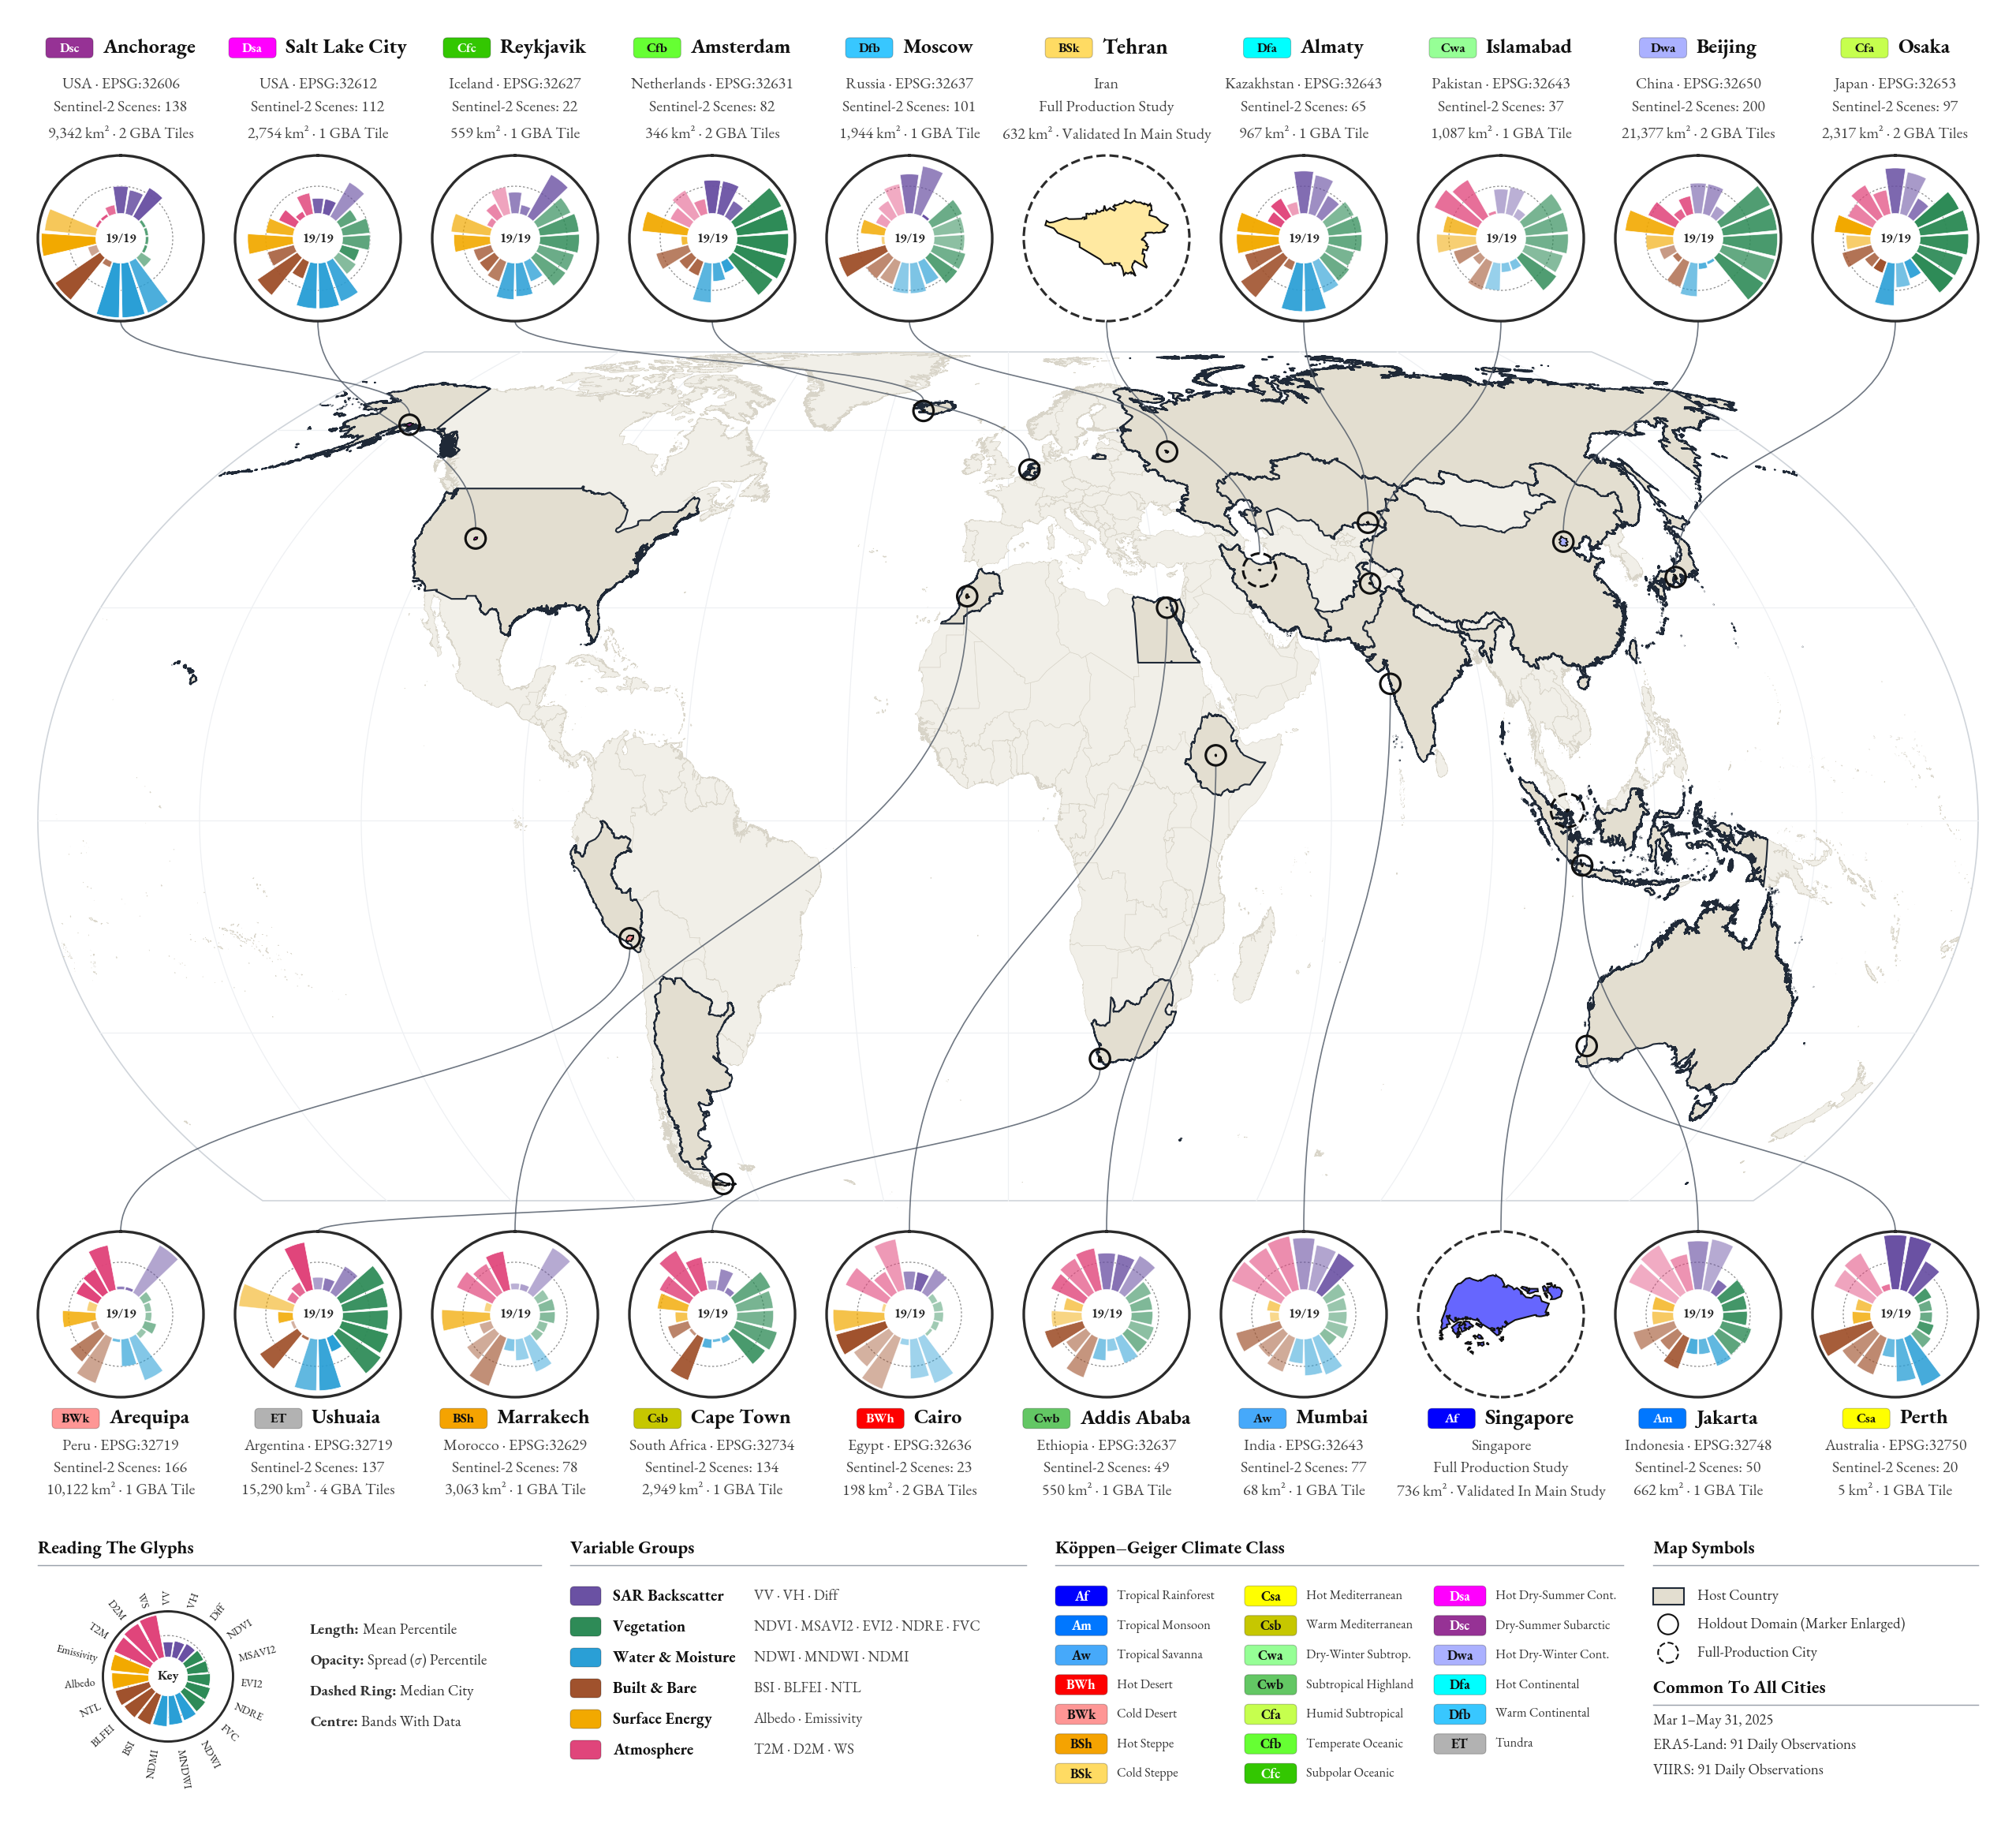

————————————————————————————————————————————————
Global UC4D Check: Host Country And Köppen Class
————————————————————————————————————————————————

                               Country Koppen    Lat     Lon

Amsterdam                  Netherlands    Cfb  52.36    4.91

Mumbai                           India     Aw  18.99   72.84

Osaka                            Japan    Cfa  34.63  135.51

Cairo           Arab Republic of Egypt    BWh  30.02   31.55

Reykjavik                      Iceland    Cfc  64.19  -21.73

Beijing                          China    Dwa  40.16  116.38

Arequipa                          Peru    BWk -16.35  -71.55

Marrakech                      Morocco    BSh  31.73   -8.16

Perth                        Australia    Csa -31.95  115.85

CapeTown                  South Africa    Csb -33.89   18.59

Islamabad                     Pakistan    Cwa  33.67   73.12

AddisAbaba                    Ethiopia    Cwb   8.98   38.79

SaltLakeCity  United States of America    Dsa 

In [15]:
# ———————————————————————
# [§12] Global UC4D Check
# ———————————————————————

CSVPath      = BaseDir / 'UC4D-Global-Check.csv'

FigureName   = 'Figure 11 Global UC4D'

SimplifyM    = 500

PixelKm2     = 0.01

HostTolDeg   = 0.5

SplitLat     = 32.5

LatMin       = -58

LatMax       = 84

Anchors      = list(Cities)

AccentNames  = {'Sao Paulo': 'São Paulo', 'Bogota': 'Bogotá'}

CountryShort = {

    'United States of America'     : 'USA'         ,

    'United States'                : 'USA'         ,

    'Russian Federation'           : 'Russia'      ,

    'Netherlands (Kingdom of the)' : 'Netherlands' ,

    'Islamic Republic of Iran'     : 'Iran'        ,

    'Iran (Islamic Republic of)'   : 'Iran'        ,

    'Arab Republic of Egypt'       : 'Egypt'

}

MapStyle = {

    'figure.dpi'         : 150                                                      ,

    'savefig.dpi'        : 300                                                      ,

    'font.family'        : 'serif'                                                  ,

    'font.serif'         : [ FontFamily , 'Garamond' , 'Georgia' , 'DejaVu Serif' ] ,

    'savefig.bbox'       : 'tight'                                                  ,

    'savefig.pad_inches' : 0.12                                                     ,

    'savefig.facecolor'  : 'white'

}

# Köppen–Geiger Palette

KG = {

    'Af'  : ( '#0000FE' , 'Tropical Rainforest' )    , 'Am' : ( '#0077FF' , 'Tropical Monsoon' )      ,

    'Aw'  : ( '#46A9FA' , 'Tropical Savanna' )       , 'BWh': ( '#FE0000' , 'Hot Desert' )            ,

    'BWk' : ( '#FE9695' , 'Cold Desert' )            , 'BSh': ( '#F5A301' , 'Hot Steppe' )            ,

    'BSk' : ( '#FFDB63' , 'Cold Steppe' )            , 'Csa': ( '#FFFF00' , 'Hot Mediterranean' )     ,

    'Csb' : ( '#C6C700' , 'Warm Mediterranean' )     , 'Csc': ( '#969600' , 'Cold Mediterranean' )    ,

    'Cwa' : ( '#96FF96' , 'Dry-Winter Subtrop.' )    , 'Cwb': ( '#63C764' , 'Subtropical Highland' )  ,

    'Cwc' : ( '#329633' , 'Cold Subtrop. Highland' ) , 'Cfa': ( '#C6FF4E' , 'Humid Subtropical' )     ,

    'Cfb' : ( '#66FF33' , 'Temperate Oceanic' )      , 'Cfc': ( '#33C701' , 'Subpolar Oceanic' )      ,

    'Dsa' : ( '#FF00FE' , 'Hot Dry-Summer Cont.' )   , 'Dsb': ( '#C600C7' , 'Warm Dry-Summer Cont.' ) ,

    'Dsc' : ( '#963295' , 'Dry-Summer Subarctic' )   , 'Dsd': ( '#966495' , 'Very Cold Dry-Summer' )  ,

    'Dwa' : ( '#ABB1FF' , 'Hot Dry-Winter Cont.' )   , 'Dwb': ( '#5A77DB' , 'Warm Dry-Winter Cont.' ) ,

    'Dwc' : ( '#4C51B5' , 'Dry-Winter Subarctic' )   , 'Dwd': ( '#320087' , 'Very Cold Dry-Winter' )  ,

    'Dfa' : ( '#00FFFF' , 'Hot Continental' )        , 'Dfb': ( '#38C7FF' , 'Warm Continental' )      ,

    'Dfc' : ( '#007E7D' , 'Subarctic' )              , 'Dfd': ( '#00455E' , 'Very Cold Subarctic' )   ,

    'ET'  : ( '#B2B2B2' , 'Tundra' )                 , 'EF' : ( '#686868' , 'Ice Cap' )

}

Koppen = {

'Tehran'    : 'BSk' , 'Singapore'  : 'Af' , 'Amsterdam'  : 'Cfb' , 'Mumbai'    : 'Aw'    ,

'Osaka'     : 'Cfa' , 'Cairo'      : 'BWh' , 'Reykjavik'  : 'Cfc' , 'Beijing'   : 'Dwa'  ,

'Arequipa'  : 'BWk' , 'Marrakech'  : 'BSh' , 'Perth'      : 'Csa' , 'CapeTown'  : 'Csb'  ,

'Islamabad' : 'Cwa' , 'AddisAbaba' : 'Cwb' , 'SaltLakeCity' : 'Dsa' , 'Almaty'    : 'Dfa' ,

    'Moscow' : 'Dfb' , 'Anchorage'  : 'Dsc' , 'Ushuaia'    : 'ET'  , 'Jakarta'   : 'Am'

}

# Groups

Groups = [

    ( 'SAR Backscatter'  , '#6a51a3' , [ 'VV' , 'VH' , 'Diff' ] )                        ,

    ( 'Vegetation'       , '#2e8b57' , [ 'NDVI' , 'MSAVI2' , 'EVI2' , 'NDRE' , 'FVC' ] ) ,

    ( 'Water & Moisture' , '#2a9fd6' , [ 'NDWI' , 'MNDWI' , 'NDMI' ] )                   ,

    ( 'Built & Bare'     , '#a0522d' , [ 'BSI' , 'BLFEI' , 'NTL' ] )                     ,

    ( 'Surface Energy'   , '#f2a900' , [ 'Albedo' , 'Emissivity' ] )                     ,

    ( 'Atmosphere'       , '#e0457b' , [ 'T2M_C' , 'D2M_C' , 'WS_ms' ] )

]

Bands      = [ B for _ , _ , Bs in Groups for B in Bs ]

BandColors = [ C for _ , C , Bs in Groups for _ in Bs ]

BandLabels = {'T2M_C': 'T2M', 'D2M_C': 'D2M', 'WS_ms': 'WS'}

NBands     = len(Bands)

Theta      = np.linspace( 0 , 2 * np.pi , NBands , endpoint = False )

BarWidth   = 2 * np.pi / NBands * 0.88

# Data

Df          = pd.read_csv(CSVPath).drop( columns = [ 'system:index' , '.geo' ] , errors = 'ignore' ).set_index('City')

SeasonLabel = str(Df['Season'].iloc[0])

Missing     = [ C for B in Bands for C in ( f'{B}_mean' , f'{B}_stdDev' ) if C not in Df.columns ]

Missing    += [ C for C in ( 'S2_Scenes' , 'Valid_Pixels' , 'GBA_Tiles' ) if C not in Df.columns ]

if Missing:

    raise KeyError(f'CSV Is Missing Columns: {Missing}')

MeanRank   = Df[[ f'{B}_mean'   for B in Bands ]].set_axis( Bands , axis = 1 ).rank( pct = True )

SpreadRank = Df[[ f'{B}_stdDev' for B in Bands ]].set_axis( Bands , axis = 1 ).rank( pct = True ).fillna(0.5)

BandsValid = Df[[ f'{B}_mean'   for B in Bands ]].notna().sum( axis = 1 )

PlotCities = list(Df.index) + [ A for A in Anchors if A not in Df.index ]

Unclassed  = [ C for C in PlotCities if C not in Koppen ]

if Unclassed:

    raise KeyError(f'No Köppen Class Designated For: {Unclassed}')

KColor = {C: KG[Koppen[C]][0] for C in PlotCities}

# GEE: Footprint, Centroid, Area

def FetchCity(City):

    Geom = (ee.FeatureCollection(f'{AssetRoot}/Spatial-Domains/Holdout-Domain/{City}').geometry().simplify(SimplifyM))

    Out  = ee.Feature( Geom , {'centroid': Geom.centroid(1000).coordinates() , 'area' : Geom.area(100).divide(1e6)} ).getInfo()

    return {'geom': Out['geometry'], 'centroid': Out['properties']['centroid'], 'area': Out['properties']['area']}

try:

    ee.Number(1).getInfo()

except Exception:

    ee.Initialize( project = EarthEngineProject )

Info = {}

with ThreadPoolExecutor( max_workers = 6 ) as Pool:

    Jobs = {Pool.submit( FetchCity , C ): C for C in PlotCities}

    for Job in as_completed(Jobs):

        try:

            Info[Jobs[Job]] = Job.result()

        except Exception as Error:

            print(f'  {Jobs[Job]}: failed ({str(Error)[:90]})\n')

if Info:

    print("  " + " • ".join([ C for C in PlotCities if C in Info ]) + "\n")

Absent = [ C for C in PlotCities if C not in Info ]

if Absent:

    raise RuntimeError(f'No GEE Geometry For: {Absent}')

Lon = {C: Info[C]['centroid'][0] for C in PlotCities}

Lat = {C: Info[C]['centroid'][1] for C in PlotCities}

# Helpers: Geometry + Color 

def Lum(Hex):

    R, G, B = matplotlib.colors.to_rgb(Hex)

    return 0.299 * R + 0.587 * G + 0.114 * B

def Pretty(City):

    Name = re.sub( r'(?<=[a-z])(?=[A-Z])' , ' ' , City )

    return AccentNames.get( Name , Name )

def Rings(Geo):

    """Outer Rings of a GeoJSON Geometry As a List of (n, 2) Arrays."""

    if Geo is None: return []

    T = Geo.get('type')

    if T == 'Polygon'           : return [ np.asarray( Geo['coordinates'][0] , float ) ]

    if T == 'MultiPolygon'      : return [ np.asarray( P[0] , float ) for P in Geo['coordinates'] ]

    if T == 'GeometryCollection': return [ R for G in Geo['geometries'] for R in Rings(G) ]

    return []

def EqualEarth( Lo , La ):

    A1, A2, A3, A4 = 1.340264, -0.081106, 0.000893, 0.003796

    Phi, Lam       = np.radians(np.asarray( La , float )) , np.radians(np.asarray( Lo , float ))

    Th             = np.arcsin(np.sqrt(3) / 2 * np.sin(Phi))

    X              = 2 * np.sqrt(3) * Lam * np.cos(Th) / (3 * (9*A4*Th**8 + 7*A3*Th**6 + 3*A2*Th**2 + A1))

    Y              = Th * (A1 + A2*Th**2 + Th**6 * (A3 + A4*Th**2))

    return X, Y

LaL            = np.linspace( LatMin , LatMax , 200 )

LoL            = np.linspace( -180 , 180 , 400 )

EdLo           = np.r_[np.full_like( LaL , -180 ) , LoL , np.full_like( LaL , 180 ), LoL[::-1]]

EdLa           = np.r_[LaL, np.full_like( LoL , LatMax ), LaL[::-1], np.full_like( LoL , LatMin )]

EdX, EdY       = EqualEarth( EdLo , EdLa )

X0, X1, Y0, Y1 = EdX.min(), EdX.max(), EdY.min(), EdY.max()

# Figure Geometry (Inches)

MapW      = 16.4

Margin    = 0.20

FigW      = MapW + 2 * Margin

MapLeft   = Margin

MapH      = MapW * (Y1 - Y0) / (X1 - X0)

Sc        = MapW / (X1 - X0)

GlyphD    = 1.40

GlyphR    = GlyphD / 2

TextGap   = 0.18

Pitch     = 0.19

NameGap   = 0.04

TopGap    = 0.12

BottomGap = 0.00

TextBlock = GlyphR + TextGap + 3 * Pitch + NameGap + 0.09 + TopGap + BottomGap

MapGap    = 0.26

LegGap    = 0.20

LegendH   = 2.18

LegBottom = Margin

LegTop    = LegBottom + LegendH

BottomY   = LegTop + LegGap + TextBlock

MapBottom = BottomY + GlyphR + MapGap

MapTop    = MapBottom + MapH

TopY      = MapTop + MapGap + GlyphR

FigH      = TopY + TextBlock + Margin

def ToIn( Lo , La ):

    X, Y = EqualEarth( Lo , La )

    return MapLeft + (np.asarray(X) - X0) * Sc, MapBottom + (np.asarray(Y) - Y0) * Sc

# Host Country Lookup (WBOB)

WBOB  = ee.FeatureCollection("projects/sat-io/open-datasets/WORLD-BANK/WBGAD/WB_GAD_ADM0").getInfo()

Polys = [ ( Fi , R ) for Fi , Feat in enumerate(WBOB['features'])

         if Feat.get('geometry') and Feat['properties'].get('NAM_0') != 'Antarctica'

         for R in Rings(Feat['geometry']) if len(R) >= 4]

def HostIndex( Lo , La ):

    for Fi, R in Polys:

        if (R[:, 0].min() <= Lo <= R[:, 0].max() and R[:, 1].min() <= La <= R[:, 1].max()

                and matplotlib.path.Path(R).contains_point(( Lo , La ))):

            return Fi

    Dist, Fi = min( ( np.min(np.hypot( R[:, 0] - Lo , R[:, 1] - La )) , Fi ) for Fi , R in Polys )

    return Fi if Dist < HostTolDeg else None

HostOf  = {C: HostIndex( Lon[C] , Lat[C] ) for C in PlotCities}

Country = {C: (WBOB['features'][F]['properties'].get('NAM_0') if F is not None else '') for C, F in HostOf.items()}

HostSet = {F for F in HostOf.values() if F is not None}

# Glyph Slot Assignment

MarkIn = {C: tuple(float(V) for V in ToIn( Lon[C] , Lat[C] )) for C in PlotCities}

Top    = sorted( [ C for C in PlotCities if Lat[C] >= SplitLat ] , key = lambda C: MarkIn[C][0] )

Bot    = sorted( [ C for C in PlotCities if Lat[C] <  SplitLat ] , key = lambda C: MarkIn[C][0] )

def SpreadPositions( Desired , MinGap , Lo , Hi ):

    N = len(Desired)

    if N == 1: return [ min( max( Desired[0] , Lo ) , Hi ) ]

    MinGap = min( MinGap , (Hi - Lo) / (N - 1) )

    Blocks = []

    for I, D in enumerate(Desired):

        Blocks.append([ D - I * MinGap , 1 ])

        while len(Blocks) > 1 and Blocks[-2][0] > Blocks[-1][0]:

            A, B = Blocks.pop(), Blocks.pop()

            W    = A[1] + B[1]

            Blocks.append([ (A[0] * A[1] + B[0] * B[1]) / W , W ])

    P = np.array([ M for M , W in Blocks for _ in range(W) ]) + MinGap * np.arange(N)

    P += max( 0 , Lo - P[0] )

    P -= max( 0 , P[-1] - Hi )

    return list(P)

SlotLo, SlotHi = MapLeft + GlyphR, MapLeft + MapW - GlyphR

TopX           = dict(zip( Top , SpreadPositions( [ MarkIn[C][0] for C in Top ] , GlyphD + 0.30 , SlotLo , SlotHi ) ))

BotX           = dict(zip( Bot , SpreadPositions( [ MarkIn[C][0] for C in Bot ] , GlyphD + 0.30 , SlotLo , SlotHi ) ))

Hole, BarScale = 0.30, 0.94

MedianR        = Hole + (1 - Hole) * BarScale * 0.5

def Text( X , Y , S , Size , **Kw ):

    Kw = {'ha': 'left', 'va': 'center', 'color': '#333333', 'zorder': 8, **Kw}

    return Ov.text( X , Y , S , fontsize = Size , **Kw )

def TextWidth( S , Size , **Kw ):

    T = Ov.text( 0 , 0 , S , fontsize = Size , **Kw )

    W = T.get_window_extent(Rend).width / Fig.dpi

    T.remove()

    return W

def FitSize( Strings , MaxW , Size , **Kw ):

    """Largest common font size <= Size that keeps every string inside MaxW (inches)."""

    return Size * min( 1.0 , MaxW / max(TextWidth( S , Size , **Kw ) for S in Strings) )

def PolarAt( Cx , Cy , D ):

    Ax = Fig.add_axes( [ (Cx - D/2) / FigW , (Cy - D/2) / FigH , D / FigW , D / FigH ] , projection = 'polar' )

    Ax.set_zorder(5)

    return Ax

def DrawGlyph( Ax , RingW , MeanR = None , SpreadR = None , Centre = '' , CentreSize = 8 ):

    Ax.set_theta_zero_location('N'); Ax.set_theta_direction(-1)

    Ax.set_xticks([]); Ax.set_yticks([]); Ax.grid(False); Ax.set_facecolor('white')

    Ax.spines['polar'].set_edgecolor('#2b2b2b'); Ax.spines['polar'].set_linewidth(RingW)

    if MeanR is not None:

        T = np.linspace( 0 , 2 * np.pi , 240 )

        Ax.plot( T , np.full_like( T , MedianR ) , color = '#8a8a8a' , lw = 0.6 , ls = ( 0 , ( 2 , 2 ) ) , zorder = 1 )

        Bars = Ax.bar( Theta , (1 - Hole) * BarScale * np.asarray(MeanR) , width = BarWidth , bottom = Hole , color = BandColors , edgecolor = 'white' , linewidth = 0.35 , zorder = 2 )

        for Bar, S in zip( Bars , np.asarray(SpreadR) ):

            Bar.set_alpha(0.42 + 0.58 * S)

    Ax.set_ylim( 0 , 1 )

    Ax.text( 0 , 0 , Centre , ha = 'center' , va = 'center' , fontsize = CentreSize , fontweight = 'bold' , color = '#222222' , zorder = 3 )

def Chip( X , Y , W , H , Hex , Label = '' , Size = 8 ):

    Ov.add_patch(matplotlib.patches.FancyBboxPatch( ( X , Y ) , W , H , boxstyle = 'round,pad=0,rounding_size=0.035' , facecolor = Hex , edgecolor = '#00000040' , linewidth = 0.5 , zorder = 8 ))

    if Label:

        Text( X + W/2 , Y + H/2 - 0.004 , Label , Size , ha = 'center' , fontweight = 'bold' , color = '#111111' if Lum(Hex) > 0.55 else 'white' , zorder = 9 )

def NameLine( Cx , Y , City , Size ):

    ChipW, Gp = 0.40, 0.08

    Name      = Text( 0 , Y , Pretty(City) , Size , fontweight = 'bold' , color = '#111111' )

    Left      = Cx - (ChipW + Gp + Name.get_window_extent(Rend).width / Fig.dpi) / 2

    Chip( Left , Y - 0.085 , ChipW , 0.17 , KColor[City] , Koppen[City] , 8 )

    Name.set_x(Left + ChipW + Gp)

def Footprint(City):

    Mx, My = MarkIn[City]

    IsA    = City in Anchors

    for R in Rings(Info[City]['geom']):

        Px, Py = ToIn( R[:, 0] , R[:, 1] )

        Ov.add_patch(matplotlib.patches.Polygon( np.column_stack([ Px , Py ]) , closed = True , facecolor = KColor[City] , edgecolor = '#111111' , linewidth = 0.7 , zorder = 9 ))

    Rr = 0.14 if IsA else 0.085

    ls = '--' if IsA else '-'

    Ov.add_patch(matplotlib.patches.Circle( ( Mx , My ) , Rr , facecolor = 'none' , edgecolor = '#111111' , linewidth = 1.5 , linestyle = ls , zorder = 10 ))

    return Rr

def Leader( Gx , Gy , City , IsTop , Rr ):

    Mx, My = MarkIn[City]

    Sy     = Gy - GlyphR if IsTop else Gy + GlyphR

    Ey     = My + Rr     if IsTop else My - Rr

    Mid    = (Sy + Ey) / 2

    P      = matplotlib.path.Path( [ ( Gx , Sy ) , ( Gx , Mid ) , ( Mx , Mid ) , ( Mx , Ey ) ] , [ matplotlib.path.Path.MOVETO ] + [ matplotlib.path.Path.CURVE4 ] * 3 )

    Ov.add_patch(matplotlib.patches.PathPatch( P , facecolor = 'none' , edgecolor = '#4b5563' , linewidth = 0.8 , alpha = 0.8 , zorder = 4 ))

def PlaceCity( City , Gx , Gy , IsTop ):

    Rr = Footprint(City)

    Leader( Gx , Gy , City , IsTop , Rr )

    Steps = [ TextGap ] + [ TextGap + NameGap + K * Pitch for K in range( 1 , 4 ) ]

    Ys    = [ Gy + GlyphR + D for D in reversed(Steps) ] if IsTop else [ Gy - GlyphR - D for D in Steps ]

    if IsTop: Ys[0] += TopGap

    else:     Ys[0] -= BottomGap

    NameLine( Gx , Ys[0] , City , 13 if City in Anchors else 12.5 )

    CountryName = CountryShort.get( Country[City] , Country[City] )

    if City in Df.index:

        R     = Df.loc[City]

        Crs   = f' · {R["CRS"]}' if 'CRS' in Df.columns else ''

        Tiles = int(R['GBA_Tiles'])

        Lines = [ f'{CountryName}{Crs}' ,

                 f'Sentinel-2 Scenes: {int(R["S2_Scenes"]):,}',

                 f'{R["Valid_Pixels"] * PixelKm2:,.0f} km² · {Tiles} GBA Tile{"s" if Tiles != 1 else ""}' ]

        DrawGlyph( PolarAt( Gx , Gy , GlyphD ) , 1.6 , MeanRank.loc[City].values , SpreadRank.loc[City].values , 

                  f'{int(BandsValid[City])}/{NBands}', 7.6)

    else:

        Lines = [ CountryName , 'Full Production Study' , f'{Info[City]["area"]:,.0f} km² · Validated In Main Study' ]

        Ov.add_patch(matplotlib.patches.Circle( ( Gx , Gy ) , GlyphR , facecolor = 'none' , edgecolor = '#2b2b2b' , linewidth = 1.5 , linestyle = '--' , zorder = 6 ))

        Cl     = math.cos(math.radians(Lat[City]))

        Shapes = [ np.column_stack([ (R[:, 0] - Lon[City]) * Cl , R[:, 1] - Lat[City] ]) for R in Rings(Info[City]['geom']) ]

        Allp   = np.vstack(Shapes)

        Mn, Mx = Allp.min(0), Allp.max(0)

        Scale  = 0.74 * GlyphD / max(Mx - Mn)

        Mid    = (Mn + Mx) / 2

        for Pn in Shapes:

            Ov.add_patch(matplotlib.patches.Polygon(

                np.column_stack([ Gx + (Pn[:, 0] - Mid[0]) * Scale , Gy + (Pn[:, 1] - Mid[1]) * Scale ]),

                closed = True, facecolor=matplotlib.colors.to_rgba( KColor[City] , 0.6 ) , edgecolor = '#111111' , linewidth = 1.0 , zorder = 7) )

    for Y, S in zip( Ys[1:] , Lines ):

        Text( Gx , Y , S , 9.6 , ha = 'center' , color = '#444444' )

def Title( X , Y , S , W ):

    Text( X , Y , S , 11 , fontweight = 'bold' , color = '#111111' )

    Ov.plot( [ X , X + W ] , [ Y - 0.14 , Y - 0.14 ] , color = '#9aa1ab' , lw = 0.7 , zorder = 8 )

# ————————————
# Build Figure
# ————————————

with matplotlib.rc_context(MapStyle):

    Fig = plt.figure( figsize = ( FigW , FigH ) )

    Fig.patch.set_facecolor('white')

    Ov   = Fig.add_axes([ 0 , 0 , 1 , 1 ]); Ov.set_xlim( 0 , FigW ); Ov.set_ylim( 0 , FigH ); Ov.axis('off'); Ov.set_zorder(1)

    Rend = Fig.canvas.get_renderer()

    # Basemap

    Ex, Ey = ToIn( EdLo , EdLa )

    Ov.add_patch(matplotlib.patches.Polygon( np.column_stack([ Ex , Ey ]) , closed = True , facecolor = 'white' , edgecolor = '#cfd4da' , linewidth = 0.8 , zorder = 0 ))

    for Lo in range( -150 , 180 , 30 ):

        Lt = np.linspace( LatMin , LatMax , 120 )

        Ov.plot( *ToIn( np.full_like( Lt , Lo ) , Lt ) , color = '#eef0f3' , lw = 0.6 , zorder = 1 )

    for La in ( -30 , 0 , 30 , 60 ):

        Lo = np.linspace( -180 , 180 , 300 )

        Ov.plot( *ToIn( Lo , np.full_like( Lo , La ) ) , color = '#eef0f3' , lw = 0.6 , zorder = 1 )

    Base, Host = [], []

    for Fi, R in Polys:

        Px, Py = ToIn( R[:, 0] , R[:, 1] )

        (Host if Fi in HostSet else Base).append(matplotlib.patches.Polygon( np.column_stack([ Px , Py ]) , closed = True ))

    Ov.add_collection(matplotlib.collections.PatchCollection( Base , facecolor = '#f1efe8' , edgecolor = '#d8d4c8' , linewidth = 0.3 , zorder = 2 ))

    Ov.add_collection(matplotlib.collections.PatchCollection( Host , facecolor = '#e3ded0' , edgecolor = '#1f2937' , linewidth = 1.0 , zorder = 3 ))

    # Cities

    for C in Top: PlaceCity( C , TopX[C] , TopY , True )

    for C in Bot: PlaceCity( C , BotX[C] , BottomY , False )

    # Legend Panel

    ColX   = {K: MapLeft + X for K, X in dict( A = 0.00 , B = 4.50 , C = 8.60 , D = 13.65 ).items()}

    ColW   = dict( A = 4.25 , B = 3.85 , C = 4.80 , D = MapW - 13.65 )

    TitleY = LegTop - 0.08

    # A · Reading The Glyphs

    Xa = ColX['A']

    Title( Xa , TitleY , 'Reading The Glyphs' , ColW['A'] )

    KeyD, Kx, Ky = 1.10, Xa + 1.10, TitleY - 1.08

    KeyAx        = PolarAt( Kx , Ky , KeyD )

    DrawGlyph( KeyAx , 1.4 , np.linspace( 0.35 , 1.0 , NBands ) , np.ones(NBands) , 'Key' , 8 )

    for Th, B in zip( Theta , Bands ):

        Left = np.sin(Th) < 0

        KeyAx.text( Th , 1.12 , BandLabels.get( B , B ) , fontsize = 6.6 , color = '#222222' , clip_on = False , 

                   rotation = (90 - np.degrees(Th)) + (180 if Left else 0), rotation_mode='anchor',

ha = 'right' if Left else 'left' , va = 'center' )

    Notes = [ 'Length: Mean Percentile' , 'Opacity: Spread (σ) Percentile' , 'Dashed Ring: Median City' , 'Centre: Bands With Data' ]

    Size  = FitSize( Notes , ColW['A'] - 2.30 , 9.2 )

    for I, S in enumerate(Notes):

        Y_pos = Ky + 0.39 - I * 0.26

        if ':' in S:

            Prefix, Suffix = S.split( ':' , 1 )

            Prefix += ':'

            W = TextWidth( Prefix , Size , fontweight = 'bold' )

            Text( Xa + 2.30 , Y_pos , Prefix , Size , fontweight = 'bold' )

            Text( Xa + 2.30 + W , Y_pos , Suffix , Size )

        else:

            Text( Xa + 2.30 , Y_pos , S , Size )

    # B · Groups

    Xb = ColX['B']

    Title( Xb , TitleY , 'Variable Groups' , ColW['B'] )

    Members = [ ' · '.join(BandLabels.get( B , B ) for B in Bs) for _ , _ , Bs in Groups ]

    Size    = FitSize( Members , ColW['B'] - 1.55 , 9.0 )

    for I, ( ( Name , Col , _ ) , Mem ) in enumerate(zip( Groups , Members )):

        Y = TitleY - 0.40 - I * 0.26

        Chip( Xb , Y - 0.08 , 0.26 , 0.16 , Col )

        Text( Xb + 0.36 , Y , Name , 9.6 , fontweight = 'bold' , color = '#111111' )

        Text( Xb + 1.55 , Y , Mem , Size , color = '#444444' )

    # C · Köppen–Geiger

    Xc      = ColX['C']

    Present = [ K for K in KG if K in set(Koppen.values()) ]

    NCol    = 2 if len(Present) <= 14 else 3

    PerCol  = math.ceil(len(Present) / NCol)

    CellW   = ColW['C'] / NCol

    Title( Xc , TitleY , 'Köppen–Geiger Climate Class' , ColW['C'] )

    Size = FitSize( [ KG[K][1] for K in Present ] , CellW - 0.52 - 0.06 , 8.6 )

    for I, K in enumerate(Present):

        Cc, Rr = divmod( I , PerCol )

        X, Y   = Xc + Cc * CellW, TitleY - 0.40 - Rr * 0.25

        Chip( X , Y - 0.085 , 0.44 , 0.17 , KG[K][0] , K , 8.2 )

        Text( X + 0.52 , Y , KG[K][1] , Size )

    # D · Map Symbols + Common Metadata

    Xd = ColX['D']

    Title( Xd , TitleY , 'Map Symbols' , ColW['D'] )

    Y = TitleY - 0.40

    Ov.add_patch(matplotlib.patches.Rectangle( ( Xd , Y - 0.07 ) , 0.26 , 0.14 , facecolor = '#e3ded0' , edgecolor = '#1f2937' , linewidth = 1.0 , zorder = 8 ))

    Text( Xd + 0.38 , Y , 'Host Country' , 9.0 )

    Y -= 0.24

    Ov.add_patch(matplotlib.patches.Circle( ( Xd + 0.13 , Y ) , 0.085 , facecolor = 'none' , edgecolor = '#111111' , linewidth = 1.0 , zorder = 8 ))

    Text( Xd + 0.38 , Y , 'Holdout Domain (Marker Enlarged)' , 9.0 )

    Y -= 0.24

    Ov.add_patch(matplotlib.patches.Circle( ( Xd + 0.13 , Y ) , 0.085 , facecolor = 'none' , edgecolor = '#111111' , linewidth = 1.0 , linestyle = '--' , zorder = 8 ))

    Text( Xd + 0.38 , Y , 'Full-Production City' , 9.0 )

    Y -= 0.30

    Title( Xd , Y , 'Common To All Cities' , ColW['D'] )

    Common = [ SeasonLabel ]

    for Col, Lab in ( ( 'ERA5_Scenes' , 'ERA5-Land' ) , ( 'VIIRS_Scenes' , 'VIIRS' ) ):

        if Col in Df.columns and Df[Col].nunique() == 1:

            Common.append(f'{Lab}: {int(Df[Col].iloc[0])} Daily Observations')

    for I, S in enumerate(Common):

        Text( Xd , Y - 0.27 - I * 0.21 , S , 9.0 )

    SaveFigure( Fig , FigureName )

    plt.show()

print('————————————————————————————————————————————————')
print('Global UC4D Check: Host Country And Köppen Class')
print('————————————————————————————————————————————————\n')

Header, *Rows = pd.DataFrame({'Country': Country, 'Koppen': Koppen, 'Lat': Lat, 'Lon': Lon}).round(2).loc[PlotCities].to_string().split('\n')

print(Header + '\n')

for R in Rows:

    print(R + '\n')

---

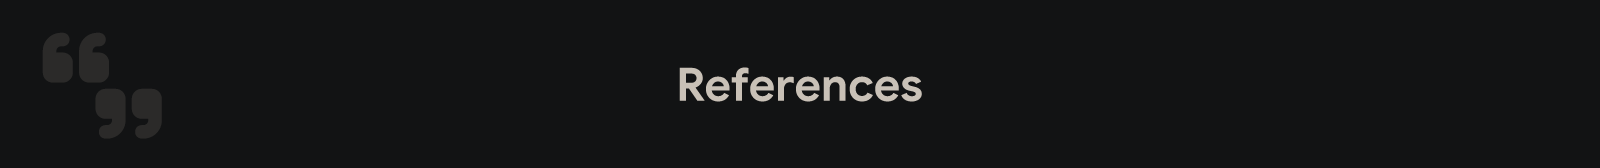

**[1] Source Data and Methods**

- Muñoz-Sabater, J., Dutra, E., Agustí-Panareda, A., et al. (2021). ERA5-Land: A state-of-the-art global reanalysis dataset for land applications. *Earth System Science Data, 13*(9), 4349–4383. https://doi.org/10.5194/essd-13-4349-2021

- Bonafoni, S., & Sekertekin, A. (2020). Albedo retrieval from Sentinel-2 data. *Remote Sensing, 12*(24), 4139. https://doi.org/10.3390/rs12244139

- Sobrino, J. A., Jiménez-Muñoz, J. C., & Paolini, L. (2004). Land surface temperature retrieval from LANDSAT TM 5. *Remote Sensing of Environment, 90*(4), 434–440. https://doi.org/10.1016/j.rse.2004.02.003

**[2] Software**

- Harris, C. R., Millman, K. J., van der Walt, S. J., et al. (2020). Array programming with NumPy. *Nature, 585*, 357–362. https://doi.org/10.1038/s41586-020-2649-2

- Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90–95. https://doi.org/10.1109/MCSE.2007.55

- McKinney, W. (2010). Data structures for statistical computing in Python. *Proceedings of the 9th Python in Science Conference*, 56–61. https://doi.org/10.25080/Majora-92bf1922-00a

- Gorelick, N., Hancher, M., Dixon, M., Ilyushchenko, S., Thau, D., & Moore, R. (2017). Google Earth Engine: Planetary-scale geospatial analysis for everyone. *Remote Sensing of Environment, 202*, 18–27. https://doi.org/10.1016/j.rse.2017.06.031